<a href="https://colab.research.google.com/github/lizlorenzana931109-art/FinPredict-Actividad5/blob/main/fuentes/entrena_ipynb.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# FinPredict | Actividad 5

## Gestión de datos, entrenamiento y ajuste de modelos

**Objetivo:** Desarrollar un modelo de clasificación para predecir el incumplimiento hipotecario utilizando datos sintéticos.

**Alcance:** 50,000 contratos hipotecarios con aperturas escalonadas entre 2021 y 2025.

**Metodología:** Preparación y validación de datos, análisis exploratorio, entrenamiento de Regresión Logística y Random Forest, validación cruzada y registro de experimentos con MLflow.

**Herramientas:** Python, Google Colab, GitHub, scikit-learn y MLflow.

In [1]:

# ============================================================
# FINPREDICT | ACTIVIDAD 5
# 01. Preparación del entorno
# ============================================================

# Instalación de librerías necesarias
%pip -q install mlflow pyarrow

# Librerías para manipulación y análisis de datos
import pandas as pd
import numpy as np
import matplotlib
import sklearn
import pyarrow
import mlflow

# Información del entorno
print("FINPREDICT | Validación del entorno")
print("-" * 45)

print(f"Pandas:        {pd.__version__}")
print(f"NumPy:         {np.__version__}")
print(f"Matplotlib:    {matplotlib.__version__}")
print(f"Scikit-learn:  {sklearn.__version__}")
print(f"PyArrow:       {pyarrow.__version__}")
print(f"MLflow:        {mlflow.__version__}")

print("-" * 45)
print("Entorno preparado correctamente.")


     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 50.2/50.2 kB 1.5 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 51.1/51.1 kB 2.3 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.3/44.3 kB 1.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.0/12.0 MB 96.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.1/4.1 MB 99.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.0/2.0 MB 66.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 268.7/268.7 kB 20.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 148.8/148.8 kB 10.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 114.9/114.9 kB 8.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 228.4/228.4 kB 17.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 136.5/136.5 kB 11.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 148.7/148.7 kB 11.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━

## 02. Configuración y generación de datos sintéticos

### Objetivo

Construir un conjunto de datos sintéticos de 50,000 contratos hipotecarios, con aperturas escalonadas entre enero de 2021 y diciembre de 2025.

La simulación permitirá generar información contractual, sociodemográfica y transaccional para estudiar patrones de comportamiento de pago e identificar señales asociadas al incumplimiento hipotecario.

### Criterios metodológicos

- **Reproducibilidad:** utilización de una semilla aleatoria fija.
- **Consistencia temporal:** los movimientos deberán respetar la fecha de apertura de cada contrato.
- **Consistencia financiera:** los importes y condiciones contractuales deberán seguir reglas de negocio documentadas.
- **Calidad de datos:** se incorporarán inconsistencias controladas para evaluar los procesos de limpieza.
- **Uso responsable:** los datos serán completamente sintéticos y las variables sociodemográficas estarán sujetas a evaluación ética.

Los resultados representarán un escenario simulado y no deberán interpretarse como evidencia del comportamiento real de una cartera hipotecaria.

In [2]:

# ============================================================
# FINPREDICT | ACTIVIDAD 5
# 02. Parámetros generales del dataset
# ============================================================

from datetime import datetime

# Semilla para reproducibilidad
SEMILLA = 42
rng = np.random.default_rng(SEMILLA)

# Universo de contratos
NUM_CONTRATOS = 50_000

# Periodo de simulación
FECHA_INICIO = pd.Timestamp("2021-01-01")
FECHA_FIN = pd.Timestamp("2025-12-31")

# Parámetros generales
MONEDA = "MXN"
TIPO_PROBLEMA = "Clasificación binaria"

# Información del proyecto
print("FINPREDICT | Configuración del dataset")
print("-" * 50)
print(f"Contratos:       {NUM_CONTRATOS:,}")
print(f"Periodo:         {FECHA_INICIO.date()} a {FECHA_FIN.date()}")
print(f"Semilla:         {SEMILLA}")
print(f"Moneda:          {MONEDA}")
print(f"Problema:        {TIPO_PROBLEMA}")
print("-" * 50)
print("Configuración inicializada correctamente.")


FINPREDICT | Configuración del dataset
--------------------------------------------------
Contratos:       50,000
Periodo:         2021-01-01 a 2025-12-31
Semilla:         42
Moneda:          MXN
Problema:        Clasificación binaria
--------------------------------------------------
Configuración inicializada correctamente.


In [3]:

# ============================================================
# FINPREDICT | ACTIVIDAD 5
# 03. Generación de identificadores y fechas de apertura
# ============================================================

# Identificadores únicos de los 50,000 contratos
ids_credito = [
    f"HIP{i:06d}"
    for i in range(1, NUM_CONTRATOS + 1)
]

# Fechas aleatorias dentro del periodo definido
dias_periodo = (FECHA_FIN - FECHA_INICIO).days + 1

dias_aleatorios = rng.integers(
    low=0,
    high=dias_periodo,
    size=NUM_CONTRATOS
)

fechas_apertura = (
    FECHA_INICIO + pd.to_timedelta(dias_aleatorios, unit="D")
)

# Tabla inicial de contratos
df_contratos = pd.DataFrame({
    "id_credito": ids_credito,
    "fecha_apertura": fechas_apertura
})

# Ordenar por identificador
df_contratos = df_contratos.sort_values(
    "id_credito"
).reset_index(drop=True)

# Validaciones iniciales
assert len(df_contratos) == NUM_CONTRATOS
assert df_contratos["id_credito"].is_unique
assert df_contratos["fecha_apertura"].between(
    FECHA_INICIO, FECHA_FIN
).all()

print("FINPREDICT | Contratos generados")
print("-" * 45)
print(f"Total de contratos: {len(df_contratos):,}")
print(f"IDs únicos:         {df_contratos['id_credito'].nunique():,}")
print(f"Fecha mínima:       {df_contratos['fecha_apertura'].min().date()}")
print(f"Fecha máxima:       {df_contratos['fecha_apertura'].max().date()}")
print("-" * 45)

display(df_contratos.head(10))


FINPREDICT | Contratos generados
---------------------------------------------
Total de contratos: 50,000
IDs únicos:         50,000
Fecha mínima:       2021-01-01
Fecha máxima:       2025-12-31
---------------------------------------------


,id_credito,fecha_apertura
0,HIP000001,2021-06-12
1,HIP000002,2024-11-14
2,HIP000003,2024-04-10
3,HIP000004,2023-03-13
4,HIP000005,2023-03-02
5,HIP000006,2025-04-17
6,HIP000007,2021-06-06
7,HIP000008,2024-06-27
8,HIP000009,2022-01-03
9,HIP000010,2021-06-21


In [5]:
# Librería para visualización de datos
import matplotlib.pyplot as plt

FINPREDICT | Distribución de aperturas


,contratos,porcentaje
fecha_apertura,,
2021,10016,20.03
2022,9959,19.92
2023,9975,19.95
2024,10144,20.29
2025,9906,19.81


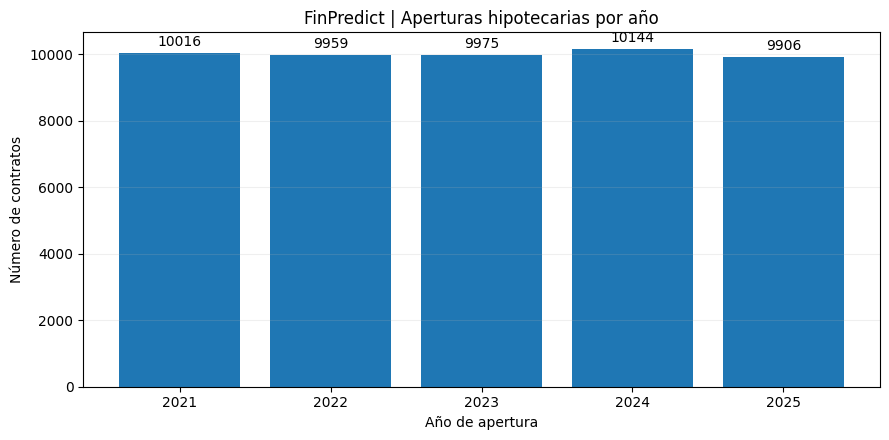

Validación: el universo de contratos está completo.


In [6]:

# ============================================================
# FINPREDICT | ACTIVIDAD 5
# 04. Análisis de aperturas por año
# ============================================================

# Distribución anual
distribucion_anual = (
    df_contratos["fecha_apertura"]
    .dt.year
    .value_counts()
    .sort_index()
)

# Porcentaje por año
resumen_aperturas = pd.DataFrame({
    "contratos": distribucion_anual,
    "porcentaje": (
        distribucion_anual / NUM_CONTRATOS * 100
    ).round(2)
})

print("FINPREDICT | Distribución de aperturas")
display(resumen_aperturas)

# Visualización
fig, ax = plt.subplots(figsize=(9, 4.5))

barras = ax.bar(
    resumen_aperturas.index.astype(str),
    resumen_aperturas["contratos"]
)

ax.bar_label(barras, padding=3, fmt="%.0f")

ax.set_title("FinPredict | Aperturas hipotecarias por año")
ax.set_xlabel("Año de apertura")
ax.set_ylabel("Número de contratos")
ax.grid(axis="y", alpha=0.2)

plt.tight_layout()
plt.show()

# Validación del universo
assert distribucion_anual.sum() == NUM_CONTRATOS

print("Validación: el universo de contratos está completo.")


### Análisis de distribución temporal

Se generaron 50,000 contratos hipotecarios sintéticos, con fechas de apertura comprendidas entre el 1 de enero de 2021 y el 31 de diciembre de 2025.

El análisis exploratorio identificó una distribución aproximadamente uniforme entre los cinco años, con porcentajes anuales de 19.81% a 20.29%.

El año 2024 presentó la mayor concentración de aperturas (10,144 contratos), mientras que 2025 registró la menor (9,906 contratos).

No se identificaron desequilibrios temporales relevantes en la distribución anual. Este comportamiento es consistente con el mecanismo de generación aleatoria utilizado y no representa una tendencia observada en datos hipotecarios reales.

**Conclusión:** Se valida la distribución inicial de aperturas para continuar con la generación de características contractuales y financieras.


### 05. Metodología de generación y validación de condiciones financieras

**Objetivo:** Generar condiciones financieras consistentes para los 50,000 contratos hipotecarios sintéticos, utilizando supuestos controlados y una fórmula de amortización de pagos constantes.

#### Variables y supuestos de generación

| Variable | Metodología | Valores permitidos |
|---|---|---|
| `monto_original` | Distribución uniforme aleatoria | $300,000 a $5,000,000 MXN |
| `plazo_meses` | Distribución categórica ponderada | 120 (10%), 180 (20%), 240 (50%) y 360 (20%) |
| `tasa_interes_anual` | Distribución uniforme aleatoria | 7% a 15% anual |
| `pago_mensual` | Cálculo financiero | Amortización con mensualidades constantes |

Los rangos y probabilidades son **supuestos de simulación académica** y no representan estadísticas observadas de una cartera hipotecaria real.

#### Cálculo de la mensualidad

Se utiliza la fórmula de amortización francesa, bajo el supuesto de tasa fija y pagos mensuales constantes:

$$
M = P \frac{r(1+r)^n}{(1+r)^n-1}
$$

Donde:

- **M:** mensualidad contractual en pesos mexicanos.
- **P:** monto original financiado.
- **r:** tasa de interés mensual, calculada como tasa anual porcentual dividida entre 100 y entre 12.
- **n:** número total de mensualidades del crédito.

$$
r = \frac{\text{tasa de interés anual}}{100 \times 12}
$$

La mensualidad considera capital e intereses. No incluye seguros, comisiones, gastos adicionales ni ajustes por incumplimiento. Los cálculos se redondean a dos decimales para representar importes monetarios.

#### Resultados obtenidos

| Indicador | Resultado |
|---|---:|
| Contratos generados | 50,000 |
| Monto mínimo financiado | $300,062.43 MXN |
| Monto máximo financiado | $4,999,970.55 MXN |
| Mensualidad promedio | $28,603.07 MXN |

#### Validaciones de calidad

Se ejecutaron controles automatizados para comprobar que:

1. Los importes originales se encuentran dentro del rango definido.
2. Los plazos pertenecen exclusivamente al catálogo autorizado.
3. Las tasas anuales se encuentran entre 7% y 15%.
4. Todas las mensualidades calculadas son positivas.
5. No existen valores nulos en las cuatro variables financieras generadas.

**Resultado:** Todas las validaciones se ejecutaron satisfactoriamente.

#### Interpretación técnica

La generación incorpora variabilidad en monto, plazo y tasa de interés, manteniendo consistencia matemática entre las condiciones contractuales y la mensualidad calculada.

El pago mensual promedio de $28,603.07 MXN es un resultado del conjunto de supuestos sintéticos y no representa una estimación del mercado hipotecario mexicano.

Estas variables permitirán construir posteriormente las obligaciones de pago y contrastarlas con los movimientos realizados por cada crédito, para calcular indicadores de comportamiento y morosidad.

**Consideración metodológica:** La consistencia financiera demostrada corresponde al cálculo inicial de mensualidades. La validación integral de saldos, pagos, atrasos y ajustes se realizará cuando se construya el histórico transaccional.
  

In [7]:

# ============================================================
# FINPREDICT | ACTIVIDAD 5
# 05. Generación de condiciones financieras
# ============================================================

# 1. Monto original del crédito (MXN)
df_contratos["monto_original"] = np.round(
    rng.uniform(300_000, 5_000_000, NUM_CONTRATOS),
    2
)

# 2. Plazo del financiamiento
plazos = [120, 180, 240, 360]
probabilidades = [0.10, 0.20, 0.50, 0.20]

df_contratos["plazo_meses"] = rng.choice(
    plazos,
    size=NUM_CONTRATOS,
    p=probabilidades
)

# 3. Tasa anual fija, expresada en porcentaje
df_contratos["tasa_interes_anual"] = np.round(
    rng.uniform(7.0, 15.0, NUM_CONTRATOS),
    4
)

# 4. Cálculo de mensualidad contractual
P = df_contratos["monto_original"]
r = df_contratos["tasa_interes_anual"] / 100 / 12
n = df_contratos["plazo_meses"]

df_contratos["pago_mensual"] = np.round(
    P * (r * (1 + r)**n) / ((1 + r)**n - 1),
    2
)

# 5. Validaciones financieras
assert df_contratos["monto_original"].between(
    300_000, 5_000_000
).all()

assert df_contratos["plazo_meses"].isin(
    plazos
).all()

assert df_contratos["tasa_interes_anual"].between(
    7.0, 15.0
).all()

assert (df_contratos["pago_mensual"] > 0).all()

assert df_contratos[
    ["monto_original", "plazo_meses",
     "tasa_interes_anual", "pago_mensual"]
].notna().all().all()

print("FINPREDICT | Condiciones financieras generadas")
print("-" * 55)
print(f"Contratos: {len(df_contratos):,}")
print(f"Monto mínimo: ${df_contratos['monto_original'].min():,.2f}")
print(f"Monto máximo: ${df_contratos['monto_original'].max():,.2f}")
print(f"Pago mensual promedio: ${df_contratos['pago_mensual'].mean():,.2f}")
print("-" * 55)
print("Validaciones financieras satisfactorias.")

display(df_contratos.head(10))


FINPREDICT | Condiciones financieras generadas
-------------------------------------------------------
Contratos: 50,000
Monto mínimo: $300,062.43
Monto máximo: $4,999,970.55
Pago mensual promedio: $28,603.07
-------------------------------------------------------
Validaciones financieras satisfactorias.


,id_credito,fecha_apertura,monto_original,plazo_meses,tasa_interes_anual,pago_mensual
0,HIP000001,2021-06-12,4784933.89,360,10.3400,43198.32
1,HIP000002,2024-11-14,4955117.17,180,11.6005,58202.15
2,HIP000003,2024-04-10,4215882.23,360,10.8975,39822.65
3,HIP000004,2023-03-13,2386254.37,360,11.6595,23921.70
4,HIP000005,2023-03-02,2872824.08,360,13.8317,33656.96
5,HIP000006,2025-04-17,2665542.79,180,12.1300,32214.27
6,HIP000007,2021-06-06,1031633.61,240,8.5900,9011.61
7,HIP000008,2024-06-27,4315746.60,240,9.6991,40791.19
8,HIP000009,2022-01-03,3476217.40,240,11.4310,36906.28
9,HIP000010,2021-06-21,3298297.40,180,11.6403,38825.06


## 06. Análisis exploratorio de condiciones financieras

### Objetivo

Evaluar la distribución estadística de los montos originales, las mensualidades, las tasas de interés y los plazos de los 50,000 contratos hipotecarios sintéticos.

El análisis permitirá identificar patrones de concentración, dispersión y posibles valores atípicos, diferenciando entre variaciones financieras válidas y errores de calidad de datos.

**Metodología:** se utilizarán estadísticas descriptivas, histogramas y diagramas de caja (*boxplots*).

Los valores atípicos identificados no serán eliminados automáticamente, ya que podrían corresponder a condiciones contractuales válidas dentro de los rangos definidos para la simulación.

FINPREDICT | Estadísticas financieras
-------------------------------------------------------


,monto_original,plazo_meses,tasa_interes_anual,pago_mensual
count,50000.00,50000.00,50000.00,50000.00
mean,2656556.67,240.05,11.00,28603.07
std,1354038.53,71.05,2.31,15692.15
min,300062.43,120.00,7.00,2087.83
25%,1483200.36,180.00,8.99,15383.03
50%,2663115.60,240.00,10.99,27827.34
75%,3823750.31,240.00,13.01,40161.19
max,4999970.55,360.00,15.00,79864.65


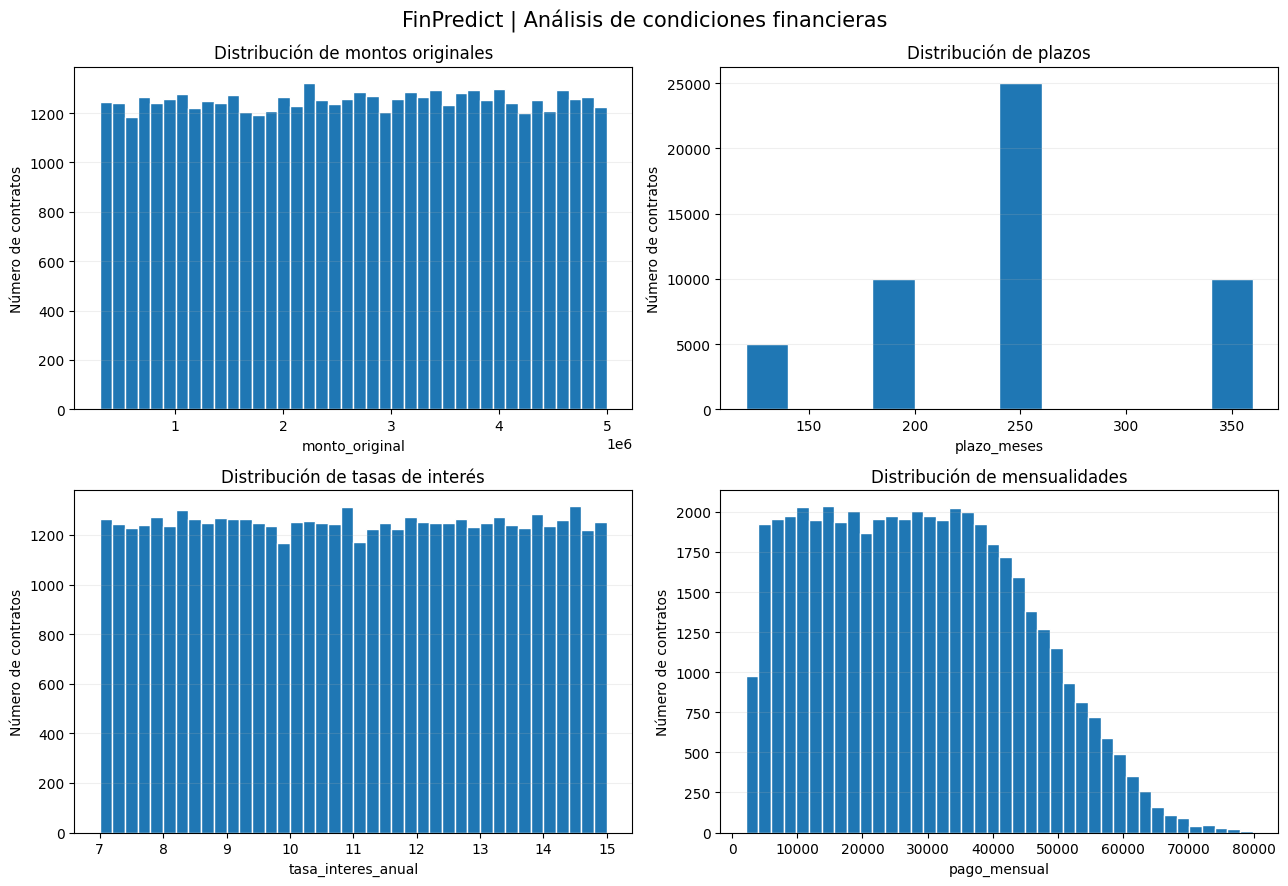


FINPREDICT | Valores atípicos potenciales
-------------------------------------------------------
monto_original: 0 (0.00%)
pago_mensual: 12 (0.02%)


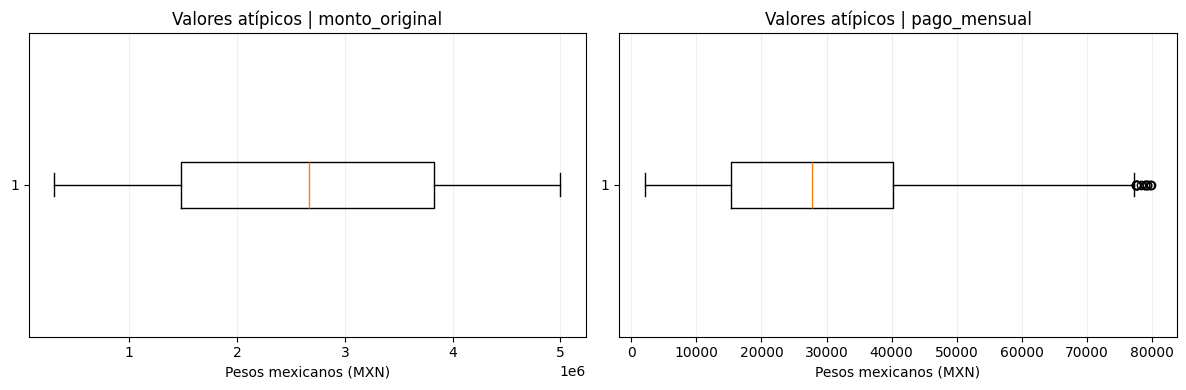

In [8]:

# ============================================================
# FINPREDICT | ACTIVIDAD 5
# 06. Análisis exploratorio de condiciones financieras
# ============================================================

import matplotlib.pyplot as plt
import seaborn as sns

# Variables financieras para el análisis
variables_financieras = [
    "monto_original",
    "plazo_meses",
    "tasa_interes_anual",
    "pago_mensual"
]

# Estadísticas descriptivas
print("FINPREDICT | Estadísticas financieras")
print("-" * 55)

display(
    df_contratos[variables_financieras]
    .describe()
    .round(2)
)

# Histogramas
fig, axes = plt.subplots(2, 2, figsize=(13, 9))

titulos = [
    "Distribución de montos originales",
    "Distribución de plazos",
    "Distribución de tasas de interés",
    "Distribución de mensualidades"
]

for ax, columna, titulo in zip(
    axes.flatten(),
    variables_financieras,
    titulos
):
    ax.hist(
        df_contratos[columna],
        bins=40 if columna != "plazo_meses" else 12,
        edgecolor="white"
    )

    ax.set_title(titulo)
    ax.set_xlabel(columna)
    ax.set_ylabel("Número de contratos")
    ax.grid(axis="y", alpha=0.2)

plt.suptitle(
    "FinPredict | Análisis de condiciones financieras",
    fontsize=15
)

plt.tight_layout()
plt.show()

# Detección estadística de valores atípicos (IQR)
print("\nFINPREDICT | Valores atípicos potenciales")
print("-" * 55)

for columna in ["monto_original", "pago_mensual"]:
    q1 = df_contratos[columna].quantile(0.25)
    q3 = df_contratos[columna].quantile(0.75)
    iqr = q3 - q1

    limite_inferior = q1 - 1.5 * iqr
    limite_superior = q3 + 1.5 * iqr

    atipicos = df_contratos[
        (df_contratos[columna] < limite_inferior) |
        (df_contratos[columna] > limite_superior)
    ]

    print(
        f"{columna}: {len(atipicos):,} "
        f"({len(atipicos) / NUM_CONTRATOS * 100:.2f}%)"
    )

# Diagramas de caja
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

for ax, columna in zip(
    axes,
    ["monto_original", "pago_mensual"]
):
    ax.boxplot(
        df_contratos[columna].dropna(),
        vert=False
    )

    ax.set_title(f"Valores atípicos | {columna}")
    ax.set_xlabel("Pesos mexicanos (MXN)")
    ax.grid(axis="x", alpha=0.2)

plt.tight_layout()
plt.show()



### 06.1. Resultados del análisis exploratorio financiero

Se analizaron las condiciones financieras de 50,000 contratos hipotecarios sintéticos mediante estadísticas descriptivas, histogramas y detección de valores atípicos utilizando el rango intercuartílico (IQR).

#### Principales resultados

| Indicador | Resultado |
|---|---:|
| Monto original promedio | $2,656,556.67 MXN |
| Plazo promedio | 240.05 meses |
| Tasa de interés promedio | 11.00% anual |
| Mensualidad promedio | $28,603.07 MXN |
| Mensualidad mínima | $2,087.83 MXN |
| Mensualidad máxima | $79,864.65 MXN |
| Valores atípicos en monto original | 0 |
| Valores atípicos en mensualidad | 12 (0.024%) |

#### Interpretación

Los montos originales y las tasas presentan estadísticas centrales consistentes con los rangos de generación definidos.

El plazo promedio es cercano a 240 meses, correspondiente a 20 años, en concordancia con la distribución de probabilidades establecida.

Se identificaron 12 mensualidades potencialmente atípicas mediante el método IQR. Estos registros representan el 0.024% de la población.

La presencia de mensualidades elevadas no constituye por sí misma un error de calidad, ya que puede explicarse por combinaciones válidas de importe financiado, tasa de interés y plazo contractual.

#### Decisión de tratamiento

Los 12 registros permanecerán sujetos a validación financiera individual. No se eliminarán automáticamente por su clasificación estadística.

Esta decisión evita descartar observaciones válidas y preserva la variabilidad de las condiciones contractuales simuladas.

#### Conclusión

El análisis inicial no evidencia inconsistencias en los rangos financieros configurados. La evaluación de valores atípicos permite distinguir entre variabilidad estadística y posibles errores, fortaleciendo los criterios de calidad de datos del proyecto FinPredict.


In [9]:

# ============================================================
# FINPREDICT | ACTIVIDAD 5
# 07. Auditoría de mensualidades atípicas
# ============================================================

q1 = df_contratos["pago_mensual"].quantile(0.25)
q3 = df_contratos["pago_mensual"].quantile(0.75)
iqr = q3 - q1

limite_inferior = q1 - 1.5 * iqr
limite_superior = q3 + 1.5 * iqr

df_atipicos = df_contratos.loc[
    (df_contratos["pago_mensual"] < limite_inferior) |
    (df_contratos["pago_mensual"] > limite_superior)
].copy()

# Recalcular independientemente la mensualidad esperada
p = df_atipicos["monto_original"]
r = df_atipicos["tasa_interes_anual"] / 100 / 12
n = df_atipicos["plazo_meses"]

df_atipicos["mensualidad_recalculada"] = np.round(
    p * (r * (1 + r)**n) / ((1 + r)**n - 1),
    2
)

df_atipicos["diferencia_calculo"] = (
    df_atipicos["pago_mensual"] -
    df_atipicos["mensualidad_recalculada"]
).round(2)

print("FINPREDICT | Auditoría financiera de atípicos")
print(f"Límite inferior IQR: ${limite_inferior:,.2f}")
print(f"Límite superior IQR: ${limite_superior:,.2f}")
print(f"Registros detectados: {len(df_atipicos):,}")

display(
    df_atipicos[[
        "id_credito",
        "monto_original",
        "plazo_meses",
        "tasa_interes_anual",
        "pago_mensual",
        "mensualidad_recalculada",
        "diferencia_calculo"
    ]]
)

# Validación del cálculo
assert np.isclose(
    df_atipicos["diferencia_calculo"], 0, atol=0.01
).all()

print("Validación: las mensualidades atípicas coinciden con la fórmula.")


FINPREDICT | Auditoría financiera de atípicos
Límite inferior IQR: $-21,784.21
Límite superior IQR: $77,328.44
Registros detectados: 12


,id_credito,monto_original,plazo_meses,tasa_interes_anual,pago_mensual,mensualidad_recalculada,diferencia_calculo
18834,HIP018835,4862326.09,120,14.7003,77556.32,77556.32,0.0
28232,HIP028233,4859723.35,120,14.6915,77488.76,77488.76,0.0
28852,HIP028853,4976789.52,120,14.6471,79220.88,79220.88,0.0
30499,HIP030500,4982281.60,120,14.7886,79737.84,79737.84,0.0
32360,HIP032361,4896867.45,120,14.5647,77703.33,77703.33,0.0
36247,HIP036248,4897244.34,120,14.7351,78217.12,78217.12,0.0
38270,HIP038271,4946883.46,120,14.8094,79234.10,79234.10,0.0
41400,HIP041401,4952493.68,120,14.9880,79864.65,79864.65,0.0
45011,HIP045012,4910099.85,120,14.9188,78973.09,78973.09,0.0
45797,HIP045798,4838022.47,120,14.8274,77543.64,77543.64,0.0


Validación: las mensualidades atípicas coinciden con la fórmula.



### 06.2. Auditoría y tratamiento de valores atípicos

Se realizó una revisión individual de los 12 contratos cuya mensualidad superó los límites establecidos mediante el método del rango intercuartílico (IQR).

**Resultados de la auditoría:**

- Límite inferior IQR: -$21,784.21 MXN.
- Límite superior IQR: $77,328.44 MXN.
- Registros identificados: 12 (0.024%).
- Diferencias entre mensualidad registrada y recalculada: $0.00 MXN en todos los casos.

Los contratos identificados presentan montos financiados elevados, plazos de 120 meses y tasas de interés cercanas al extremo superior del rango simulado.

Estas condiciones explican las mensualidades elevadas y son consistentes con la fórmula de amortización utilizada.

**Decisión de calidad de datos:** conservar los 12 registros sin modificaciones.

**Justificación:** los valores atípicos responden a combinaciones válidas de los parámetros financieros definidos. Eliminarlos implicaría perder variabilidad del conjunto de datos sin evidencia de un error.

**Conclusión:** la detección estadística debe complementarse con reglas de negocio antes de decidir la modificación o eliminación de observaciones.



## 07. Generación de información sociodemográfica

### Objetivo

Incorporar variables sociodemográficas sintéticas a los 50,000 contratos hipotecarios para complementar la caracterización de la cartera y permitir posteriores análisis de equidad.

### Variables consideradas

- Edad del titular al momento de la apertura.
- Ingreso mensual estimado al momento de la apertura.
- Tipo de empleo.
- Región geográfica.

### Supuestos de generación

La edad se simula entre 23 y 70 años.

El ingreso mensual se calcula utilizando una relación inicial pago/ingreso comprendida entre 20% y 45%.

El tipo de empleo y la región se generan mediante distribuciones categóricas hipotéticas.

Los valores no corresponden a información real de clientes ni a estadísticas oficiales.

### Consideraciones éticas

Las variables sociodemográficas no serán incorporadas automáticamente al entrenamiento.

Su utilización deberá justificarse según su relevancia predictiva, el riesgo de discriminación y las diferencias de desempeño entre grupos.

Las variables de edad y región se reservarán inicialmente para auditoría de equidad.

El ingreso simulado representa una condición inicial y no necesariamente la situación económica del cliente durante todo el histórico.


In [10]:

# ============================================================
# FINPREDICT | ACTIVIDAD 5
# 08. Generación de variables sociodemográficas
# ============================================================

# 1. Edad del titular al momento de la apertura
df_contratos["edad"] = rng.integers(
    low=23,
    high=71,
    size=NUM_CONTRATOS
)

# 2. Relación mensualidad / ingreso
relacion_pago_ingreso = rng.uniform(
    low=0.20,
    high=0.45,
    size=NUM_CONTRATOS
)

# 3. Ingreso mensual sintético de originación
df_contratos["ingreso_mensual"] = np.round(
    df_contratos["pago_mensual"] / relacion_pago_ingreso,
    2
)

# 4. Tipo de empleo
tipos_empleo = [
    "ASALARIADO",
    "INDEPENDIENTE",
    "EMPRESARIO"
]

df_contratos["tipo_empleo"] = rng.choice(
    tipos_empleo,
    size=NUM_CONTRATOS,
    p=[0.65, 0.25, 0.10]
)

# 5. Región geográfica
regiones = [
    "NORTE",
    "CENTRO",
    "OCCIDENTE",
    "SUR",
    "SURESTE"
]

df_contratos["region"] = rng.choice(
    regiones,
    size=NUM_CONTRATOS,
    p=[0.20, 0.35, 0.20, 0.15, 0.10]
)

# 6. Validaciones
assert df_contratos["edad"].between(23, 70).all()

assert (df_contratos["ingreso_mensual"] > 0).all()

assert df_contratos["tipo_empleo"].isin(
    tipos_empleo
).all()

assert df_contratos["region"].isin(
    regiones
).all()

assert df_contratos[
    ["edad", "ingreso_mensual", "tipo_empleo", "region"]
].notna().all().all()

# Validación de relación pago / ingreso
ratio_real = (
    df_contratos["pago_mensual"] /
    df_contratos["ingreso_mensual"]
)

assert ratio_real.between(
    0.20 - 1e-5, 0.45 + 1e-5
).all()

print("FINPREDICT | Información sociodemográfica")
print("-" * 55)
print(f"Contratos: {len(df_contratos):,}")
print(f"Edad promedio: {df_contratos['edad'].mean():.1f} años")
print(f"Ingreso mensual promedio: "
      f"${df_contratos['ingreso_mensual'].mean():,.2f}")
print(f"Relación pago/ingreso promedio: "
      f"{ratio_real.mean():.2%}")
print("-" * 55)
print("Validaciones sociodemográficas satisfactorias.")

display(df_contratos.head(10))


FINPREDICT | Información sociodemográfica
-------------------------------------------------------
Contratos: 50,000
Edad promedio: 46.4 años
Ingreso mensual promedio: $92,592.32
Relación pago/ingreso promedio: 32.54%
-------------------------------------------------------
Validaciones sociodemográficas satisfactorias.


,id_credito,fecha_apertura,monto_original,plazo_meses,tasa_interes_anual,pago_mensual,edad,ingreso_mensual,tipo_empleo,region
0,HIP000001,2021-06-12,4784933.89,360,10.3400,43198.32,40,143552.49,ASALARIADO,CENTRO
1,HIP000002,2024-11-14,4955117.17,180,11.6005,58202.15,28,195343.82,EMPRESARIO,CENTRO
2,HIP000003,2024-04-10,4215882.23,360,10.8975,39822.65,48,95497.44,INDEPENDIENTE,SUR
3,HIP000004,2023-03-13,2386254.37,360,11.6595,23921.70,61,69458.29,INDEPENDIENTE,OCCIDENTE
4,HIP000005,2023-03-02,2872824.08,360,13.8317,33656.96,46,86302.89,ASALARIADO,OCCIDENTE
5,HIP000006,2025-04-17,2665542.79,180,12.1300,32214.27,24,108222.73,EMPRESARIO,SUR
6,HIP000007,2021-06-06,1031633.61,240,8.5900,9011.61,33,34277.17,INDEPENDIENTE,OCCIDENTE
7,HIP000008,2024-06-27,4315746.60,240,9.6991,40791.19,64,107615.36,ASALARIADO,CENTRO
8,HIP000009,2022-01-03,3476217.40,240,11.4310,36906.28,45,116509.28,ASALARIADO,OCCIDENTE
9,HIP000010,2021-06-21,3298297.40,180,11.6403,38825.06,63,108871.00,ASALARIADO,SURESTE



### 07.1. Resultados de la generación sociodemográfica

Se incorporaron cuatro variables sintéticas a los 50,000 contratos hipotecarios: edad, ingreso mensual, tipo de empleo y región.

#### Resultados obtenidos

| Indicador | Resultado |
|---|---:|
| Contratos procesados | 50,000 |
| Edad promedio | 46.4 años |
| Ingreso mensual promedio | $92,592.32 MXN |
| Relación pago/ingreso promedio | 32.54% |
| Validaciones de integridad | Satisfactorias |

#### Interpretación

La relación pago/ingreso se generó dentro del intervalo de 20% a 45%, lo que permite establecer una relación matemática consistente entre las mensualidades contractuales y los ingresos sintéticos.

La edad, el tipo de empleo y la región se generaron mediante distribuciones hipotéticas. Estas distribuciones no representan estadísticas demográficas de una cartera hipotecaria real.

#### Consideraciones éticas y metodológicas

Las características sociodemográficas se incorporan con fines de caracterización y evaluación experimental.

La edad y la región se reservarán inicialmente para auditorías de equidad, mientras que el tipo de empleo requerirá una evaluación adicional antes de considerarse como predictor.

El ingreso mensual corresponde al momento de originación y se calculó a partir de la mensualidad contractual. Por tanto, no constituye una medición independiente de capacidad de pago.

Se documentará esta dependencia para evitar interpretaciones incorrectas y evaluar su impacto en el entrenamiento.

#### Conclusión

La incorporación de variables sociodemográficas se completó satisfactoriamente según las reglas programadas. Su utilización predictiva quedará condicionada a la evaluación de relevancia, explicabilidad y riesgos éticos.



## 08. Calendario de obligaciones hipotecarias

### Objetivo

Generar las obligaciones mensuales de los contratos hipotecarios sintéticos para comparar posteriormente los importes exigibles con los pagos realizados.

### Criterios temporales

- **Periodo histórico:** enero de 2021 a diciembre de 2025.
- **Fecha de corte predictiva:** 30 de septiembre de 2025.
- **Periodo de evaluación:** octubre a diciembre de 2025.
- **Variable objetivo:** identificar créditos que alcancen al menos 90 días de atraso durante la ventana futura.

Se utilizarán únicamente datos disponibles hasta la fecha de corte para construir las variables predictoras.

Los movimientos posteriores se reservarán para determinar el incumplimiento observado.

### Consideraciones

Los créditos abiertos después de la fecha de corte no serán elegibles para el entrenamiento.

Las obligaciones mensuales se calcularán considerando la fecha de apertura, la mensualidad contractual y el plazo del financiamiento.

El calendario representa obligaciones exigibles, no pagos efectivamente realizados.


In [12]:

# ============================================================
# FINPREDICT | ACTIVIDAD 5
# 09. Configuración temporal del modelo
# ============================================================

FECHA_CORTE = pd.Timestamp("2025-09-30")

FECHA_EVALUACION_INICIO = pd.Timestamp("2025-10-01")
FECHA_EVALUACION_FIN = pd.Timestamp("2025-12-31")

# Contratos elegibles a la fecha de corte
df_elegibles = df_contratos.loc[
    df_contratos["fecha_apertura"] <= FECHA_CORTE
].copy()

# Contratos abiertos después del corte
df_no_elegibles = df_contratos.loc[
    df_contratos["fecha_apertura"] > FECHA_CORTE
].copy()

# Validaciones
assert len(df_elegibles) + len(df_no_elegibles) == NUM_CONTRATOS

assert (
    df_elegibles["fecha_apertura"] <= FECHA_CORTE
).all()

assert (
    df_no_elegibles["fecha_apertura"] > FECHA_CORTE
).all()

print("FINPREDICT | Configuración temporal")
print("-" * 55)

print(f"Fecha de corte: {FECHA_CORTE.date()}")
print(
    f"Ventana de evaluación: "
    f"{FECHA_EVALUACION_INICIO.date()} a "
    f"{FECHA_EVALUACION_FIN.date()}"
)

print(f"Contratos totales: {NUM_CONTRATOS:,}")
print(f"Contratos elegibles: {len(df_elegibles):,}")
print(f"Contratos no elegibles: {len(df_no_elegibles):,}")

print("-" * 55)
print("Validaciones temporales satisfactorias.")


FINPREDICT | Configuración temporal
-------------------------------------------------------
Fecha de corte: 2025-09-30
Ventana de evaluación: 2025-10-01 a 2025-12-31
Contratos totales: 50,000
Contratos elegibles: 47,429
Contratos no elegibles: 2,571
-------------------------------------------------------
Validaciones temporales satisfactorias.


In [13]:

# ============================================================
# FINPREDICT | ACTIVIDAD 5
# 10. Generación del calendario de obligaciones
# ============================================================

from dateutil.relativedelta import relativedelta

registros_obligaciones = []

# Generar obligaciones para los contratos
for contrato in df_contratos.itertuples(index=False):

    fecha_apertura = contrato.fecha_apertura
    fecha_vencimiento = fecha_apertura

    for numero_pago in range(1, contrato.plazo_meses + 1):

        # Calcular cada vencimiento desde la apertura
        fecha_vencimiento = (
            fecha_apertura
            + pd.DateOffset(months=numero_pago)
        )

        # No generar obligaciones posteriores al histórico
        if fecha_vencimiento > FECHA_FIN:
            break

        registros_obligaciones.append({
            "id_credito": contrato.id_credito,
            "numero_pago": numero_pago,
            "fecha_vencimiento": fecha_vencimiento,
            "importe_exigible": contrato.pago_mensual
        })

df_obligaciones = pd.DataFrame(registros_obligaciones)

# Validaciones
assert not df_obligaciones.empty

assert (
    df_obligaciones["fecha_vencimiento"] <= FECHA_FIN
).all()

assert (
    df_obligaciones["importe_exigible"] > 0
).all()

assert not df_obligaciones.duplicated(
    subset=["id_credito", "numero_pago"]
).any()

print("FINPREDICT | Calendario de obligaciones")
print("-" * 55)
print(f"Contratos originales: {len(df_contratos):,}")
print(f"Obligaciones generadas: {len(df_obligaciones):,}")
print(
    f"Contratos con obligaciones: "
    f"{df_obligaciones['id_credito'].nunique():,}"
)
print(
    f"Primera fecha: "
    f"{df_obligaciones['fecha_vencimiento'].min().date()}"
)
print(
    f"Última fecha: "
    f"{df_obligaciones['fecha_vencimiento'].max().date()}"
)
print("-" * 55)

display(df_obligaciones.head(10))


FINPREDICT | Calendario de obligaciones
-------------------------------------------------------
Contratos originales: 50,000
Obligaciones generadas: 1,475,182
Contratos con obligaciones: 49,093
Primera fecha: 2021-02-01
Última fecha: 2025-12-31
-------------------------------------------------------


,id_credito,numero_pago,fecha_vencimiento,importe_exigible
0,HIP000001,1,2021-07-12,43198.32
1,HIP000001,2,2021-08-12,43198.32
2,HIP000001,3,2021-09-12,43198.32
3,HIP000001,4,2021-10-12,43198.32
4,HIP000001,5,2021-11-12,43198.32
5,HIP000001,6,2021-12-12,43198.32
6,HIP000001,7,2022-01-12,43198.32
7,HIP000001,8,2022-02-12,43198.32
8,HIP000001,9,2022-03-12,43198.32
9,HIP000001,10,2022-04-12,43198.32


In [14]:

# ============================================================
# FINPREDICT | ACTIVIDAD 5
# 11. Validación de integridad del calendario
# ============================================================

# Contratos sin obligaciones generadas
ids_con_obligaciones = set(df_obligaciones["id_credito"])

df_sin_obligaciones = df_contratos.loc[
    ~df_contratos["id_credito"].isin(ids_con_obligaciones)
].copy()

# Fecha del primer vencimiento esperado
df_sin_obligaciones["primer_vencimiento"] = (
    df_sin_obligaciones["fecha_apertura"]
    + pd.DateOffset(months=1)
)

# Verificar que todos vencen después del histórico
sin_vencimiento_en_periodo = (
    df_sin_obligaciones["primer_vencimiento"] > FECHA_FIN
)

print("FINPREDICT | Auditoría de obligaciones")
print("-" * 55)
print(f"Contratos sin obligaciones: {len(df_sin_obligaciones):,}")
print(
    "Con primer vencimiento posterior al cierre: "
    f"{sin_vencimiento_en_periodo.sum():,}"
)
print(
    "Casos que requieren revisión: "
    f"{(~sin_vencimiento_en_periodo).sum():,}"
)

display(
    df_sin_obligaciones[
        ["id_credito", "fecha_apertura", "primer_vencimiento"]
    ].head(10)
)

assert sin_vencimiento_en_periodo.all()

print("-" * 55)
print("Validación de integridad satisfactoria.")


FINPREDICT | Auditoría de obligaciones
-------------------------------------------------------
Contratos sin obligaciones: 907
Con primer vencimiento posterior al cierre: 907
Casos que requieren revisión: 0


,id_credito,fecha_apertura,primer_vencimiento
144,HIP000145,2025-12-18,2026-01-18
160,HIP000161,2025-12-24,2026-01-24
264,HIP000265,2025-12-13,2026-01-13
346,HIP000347,2025-12-16,2026-01-16
355,HIP000356,2025-12-18,2026-01-18
400,HIP000401,2025-12-28,2026-01-28
510,HIP000511,2025-12-22,2026-01-22
554,HIP000555,2025-12-03,2026-01-03
690,HIP000691,2025-12-25,2026-01-25
771,HIP000772,2025-12-07,2026-01-07


-------------------------------------------------------
Validación de integridad satisfactoria.



### 08.1. Validación del calendario de obligaciones hipotecarias

**Objetivo:** Verificar la integridad temporal y referencial de las obligaciones generadas para los 50,000 contratos hipotecarios sintéticos.

#### Resultados obtenidos

| Indicador | Resultado |
|---|---:|
| Contratos originales | 50,000 |
| Obligaciones mensuales generadas | 1,475,182 |
| Contratos con obligaciones | 49,093 |
| Contratos sin obligaciones | 907 |
| Casos con inconsistencias detectadas | 0 |

#### Auditoría de contratos sin obligaciones

Se identificaron 907 contratos sin obligaciones exigibles dentro del periodo histórico.

La revisión individual confirmó que, en todos los casos, la primera mensualidad contractual vence después del 31 de diciembre de 2025.

Por tanto, su ausencia en el calendario es consecuencia de las fechas de apertura y no de una pérdida de información.

#### Decisión de tratamiento

Se conservarán los 907 contratos en la tabla maestra, sin modificaciones.

No se generarán obligaciones artificiales antes de su fecha de vencimiento ni se eliminarán contratos válidos.

#### Conclusión

El calendario contiene 1,475,182 obligaciones mensuales generadas conforme a los supuestos temporales y financieros establecidos.

Las validaciones ejecutadas no identificaron inconsistencias en los contratos sin obligaciones.

Este calendario constituye la base para simular pagos, calcular importes pendientes y desarrollar posteriormente indicadores de morosidad.



## 09. Simulación del comportamiento de pago

### Objetivo

Asignar perfiles sintéticos de comportamiento a los 50,000 contratos hipotecarios para generar posteriormente movimientos financieros consistentes con diferentes patrones de cumplimiento.

### Perfiles definidos

| Perfil | Proporción | Contratos |
|---|---:|---:|
| Regular | 60% | 30,000 |
| Retrasos ocasionales | 20% | 10,000 |
| Pago irregular | 15% | 7,500 |
| Deterioro progresivo | 5% | 2,500 |
| **Total** | **100%** | **50,000** |

Los perfiles son supuestos de simulación y no representan distribuciones observadas en una cartera hipotecaria real.

### Consideraciones metodológicas

Los perfiles definirán probabilidades y patrones de generación de pagos, sin determinar automáticamente la variable objetivo de incumplimiento.

La etiqueta de incumplimiento se calculará posteriormente a partir de las obligaciones vencidas y los pagos efectivamente realizados.

El perfil de simulación no se utilizará como variable predictora y se mantendrá separado del dataset analítico para evitar fuga de información.

La asignación se realizará independientemente de las características sociodemográficas.


In [15]:

# ============================================================
# FINPREDICT | ACTIVIDAD 5
# 12. Asignación de perfiles de comportamiento
# ============================================================

# Perfiles y proporciones acordadas
distribucion_perfiles = {
    "REGULAR": 0.60,
    "RETRASO_OCASIONAL": 0.20,
    "IRREGULAR": 0.15,
    "DETERIORO_PROGRESIVO": 0.05
}

# Validar proporciones
assert np.isclose(sum(distribucion_perfiles.values()), 1.0)

# Número exacto de contratos por perfil
conteos = {
    perfil: int(NUM_CONTRATOS * proporcion)
    for perfil, proporcion in distribucion_perfiles.items()
}

assert sum(conteos.values()) == NUM_CONTRATOS

# Construir y mezclar los perfiles aleatoriamente
perfiles = np.concatenate([
    np.repeat(perfil, cantidad)
    for perfil, cantidad in conteos.items()
])

rng.shuffle(perfiles)

# Guardar los perfiles en una tabla de simulación separada
df_perfiles = pd.DataFrame({
    "id_credito": df_contratos["id_credito"].to_numpy(),
    "perfil_simulacion": perfiles
})

# Validaciones
assert len(df_perfiles) == NUM_CONTRATOS
assert df_perfiles["id_credito"].is_unique
assert not df_perfiles.isna().any().any()

# Resumen
resumen_perfiles = (
    df_perfiles["perfil_simulacion"]
    .value_counts()
    .rename_axis("perfil")
    .reset_index(name="contratos")
)

resumen_perfiles["porcentaje"] = (
    resumen_perfiles["contratos"] / NUM_CONTRATOS * 100
).round(2)

print("FINPREDICT | Perfiles de comportamiento")
print("-" * 55)

display(resumen_perfiles)

print(f"Total de contratos: {len(df_perfiles):,}")
print(f"Perfiles distintos: {df_perfiles['perfil_simulacion'].nunique()}")
print("-" * 55)
print("Asignación y validaciones satisfactorias.")


FINPREDICT | Perfiles de comportamiento
-------------------------------------------------------


,perfil,contratos,porcentaje
0,REGULAR,30000,60.0
1,RETRASO_OCASIONAL,10000,20.0
2,IRREGULAR,7500,15.0
3,DETERIORO_PROGRESIVO,2500,5.0


Total de contratos: 50,000
Perfiles distintos: 4
-------------------------------------------------------
Asignación y validaciones satisfactorias.



### 09.1. Reglas de simulación de movimientos

Se definen cuatro perfiles sintéticos de comportamiento financiero: regular, retraso ocasional, irregular y deterioro progresivo.

Cada perfil determina probabilidades de realizar pagos completos, parciales o de omitir mensualidades.

Los pagos efectivamente realizados se registrarán como movimientos financieros, mientras que las obligaciones sin pago permanecerán en el calendario contractual.

Los perfiles se utilizarán exclusivamente para generar comportamientos y no se incorporarán como variables predictoras.

Antes de ejecutar la simulación completa se realizará una prueba funcional sobre un contrato, con el objetivo de validar importes, fechas y consistencia de los movimientos.

Las probabilidades son supuestos académicos y no representan estadísticas reales de morosidad hipotecaria.


In [16]:

# ============================================================
# FINPREDICT | ACTIVIDAD 5
# 13. Prueba funcional de generación de pagos
# ============================================================

# Generador independiente para la prueba
rng_prueba = np.random.default_rng(42)

# Seleccionar contrato con al menos 12 obligaciones
conteo_obligaciones = df_obligaciones["id_credito"].value_counts()

id_prueba = conteo_obligaciones[
    conteo_obligaciones >= 12
].index[0]

obligaciones_prueba = (
    df_obligaciones.loc[
        df_obligaciones["id_credito"] == id_prueba
    ]
    .sort_values("numero_pago")
    .head(12)
    .copy()
)

# Perfil de prueba: comportamiento irregular
probabilidades_pago = [0.55, 0.25, 0.20]

obligaciones_prueba["resultado_pago"] = rng_prueba.choice(
    ["COMPLETO", "PARCIAL", "SIN_PAGO"],
    size=len(obligaciones_prueba),
    p=probabilidades_pago
)

# Factor de pago por obligación
factores = []

for resultado in obligaciones_prueba["resultado_pago"]:
    if resultado == "COMPLETO":
        factores.append(1.0)
    elif resultado == "PARCIAL":
        factores.append(rng_prueba.uniform(0.30, 0.80))
    else:
        factores.append(0.0)

obligaciones_prueba["importe_pagado"] = np.round(
    obligaciones_prueba["importe_exigible"]
    * np.array(factores),
    2
)

# Importe no cubierto en cada obligación
obligaciones_prueba["importe_pendiente"] = (
    obligaciones_prueba["importe_exigible"]
    - obligaciones_prueba["importe_pagado"]
).round(2)

# Validaciones funcionales
assert (
    obligaciones_prueba["importe_pagado"] >= 0
).all()

assert (
    obligaciones_prueba["importe_pagado"]
    <= obligaciones_prueba["importe_exigible"]
).all()

assert np.allclose(
    obligaciones_prueba["importe_pagado"]
    + obligaciones_prueba["importe_pendiente"],
    obligaciones_prueba["importe_exigible"],
    atol=0.01
)

print("FINPREDICT | Prueba funcional de pagos")
print("-" * 55)
print(f"Contrato seleccionado: {id_prueba}")
print("Perfil simulado: IRREGULAR")
print(f"Obligaciones evaluadas: {len(obligaciones_prueba)}")
print("-" * 55)

display(obligaciones_prueba)


FINPREDICT | Prueba funcional de pagos
-------------------------------------------------------
Contrato seleccionado: HIP026062
Perfil simulado: IRREGULAR
Obligaciones evaluadas: 12
-------------------------------------------------------


,id_credito,numero_pago,fecha_vencimiento,importe_exigible,resultado_pago,importe_pagado,importe_pendiente
771521,HIP026062,1,2021-02-12,35291.41,PARCIAL,21948.88,13342.53
771522,HIP026062,2,2021-03-12,35291.41,COMPLETO,35291.41,0.00
771523,HIP026062,3,2021-04-12,35291.41,SIN_PAGO,0.00,35291.41
771524,HIP026062,4,2021-05-12,35291.41,PARCIAL,25105.63,10185.78
771525,HIP026062,5,2021-06-12,35291.41,COMPLETO,35291.41,0.00
771526,HIP026062,6,2021-07-12,35291.41,SIN_PAGO,0.00,35291.41
771527,HIP026062,7,2021-08-12,35291.41,PARCIAL,18411.78,16879.63
771528,HIP026062,8,2021-09-12,35291.41,PARCIAL,14597.21,20694.20
771529,HIP026062,9,2021-10-12,35291.41,COMPLETO,35291.41,0.00
771530,HIP026062,10,2021-11-12,35291.41,COMPLETO,35291.41,0.00


In [17]:

# ============================================================
# FINPREDICT | ACTIVIDAD 5
# 14. Validación de obligaciones y pagos acumulados
# ============================================================

# Copia de la prueba sin modificar los datos originales
df_prueba_saldos = obligaciones_prueba.copy()

# Obligaciones acumuladas
df_prueba_saldos["exigible_acumulado"] = (
    df_prueba_saldos["importe_exigible"]
    .cumsum()
    .round(2)
)

# Pagos acumulados
df_prueba_saldos["pagado_acumulado"] = (
    df_prueba_saldos["importe_pagado"]
    .cumsum()
    .round(2)
)

# Saldo total pendiente
df_prueba_saldos["saldo_pendiente_acumulado"] = (
    df_prueba_saldos["exigible_acumulado"]
    - df_prueba_saldos["pagado_acumulado"]
).round(2)

# Validaciones
assert (
    df_prueba_saldos["saldo_pendiente_acumulado"] >= -0.01
).all()

assert np.allclose(
    df_prueba_saldos["saldo_pendiente_acumulado"],
    df_prueba_saldos["importe_pendiente"].cumsum(),
    atol=0.01
)

print("FINPREDICT | Evolución de obligaciones pendientes")
print("-" * 55)

display(
    df_prueba_saldos[[
        "numero_pago",
        "fecha_vencimiento",
        "resultado_pago",
        "importe_pagado",
        "importe_pendiente",
        "saldo_pendiente_acumulado"
    ]]
)

print("-" * 55)
print(
    "Saldo pendiente al finalizar la prueba: "
    f"${df_prueba_saldos['saldo_pendiente_acumulado'].iloc[-1]:,.2f}"
)
print("Validaciones de acumulación satisfactorias.")


FINPREDICT | Evolución de obligaciones pendientes
-------------------------------------------------------


,numero_pago,fecha_vencimiento,resultado_pago,importe_pagado,importe_pendiente,saldo_pendiente_acumulado
771521,1,2021-02-12,PARCIAL,21948.88,13342.53,13342.53
771522,2,2021-03-12,COMPLETO,35291.41,0.00,13342.53
771523,3,2021-04-12,SIN_PAGO,0.00,35291.41,48633.94
771524,4,2021-05-12,PARCIAL,25105.63,10185.78,58819.72
771525,5,2021-06-12,COMPLETO,35291.41,0.00,58819.72
771526,6,2021-07-12,SIN_PAGO,0.00,35291.41,94111.13
771527,7,2021-08-12,PARCIAL,18411.78,16879.63,110990.76
771528,8,2021-09-12,PARCIAL,14597.21,20694.20,131684.96
771529,9,2021-10-12,COMPLETO,35291.41,0.00,131684.96
771530,10,2021-11-12,COMPLETO,35291.41,0.00,131684.96


-------------------------------------------------------
Saldo pendiente al finalizar la prueba: $166,976.37
Validaciones de acumulación satisfactorias.


In [18]:

# ============================================================
# FINPREDICT | ACTIVIDAD 5
# 15. Simulación de fechas efectivas de pago
# ============================================================

# Generador independiente para la prueba
rng_fechas = np.random.default_rng(123)

df_prueba_fechas = df_prueba_saldos.copy()

fechas_pago = []

for fila in df_prueba_fechas.itertuples():

    if fila.resultado_pago == "SIN_PAGO":
        fechas_pago.append(pd.NaT)
        continue

    if fila.resultado_pago == "COMPLETO":
        dias_desfase = rng_fechas.integers(-3, 11)

    else:  # PARCIAL
        dias_desfase = rng_fechas.integers(0, 21)

    fecha_pago = (
        fila.fecha_vencimiento
        + pd.Timedelta(days=int(dias_desfase))
    )

    fechas_pago.append(fecha_pago)

df_prueba_fechas["fecha_pago"] = pd.to_datetime(
    fechas_pago
)

# Diferencia de días respecto al vencimiento
df_prueba_fechas["dias_desfase"] = (
    df_prueba_fechas["fecha_pago"]
    - df_prueba_fechas["fecha_vencimiento"]
).dt.days

# Validaciones
assert df_prueba_fechas.loc[
    df_prueba_fechas["resultado_pago"] == "SIN_PAGO",
    "fecha_pago"
].isna().all()

assert df_prueba_fechas.loc[
    df_prueba_fechas["resultado_pago"] != "SIN_PAGO",
    "fecha_pago"
].notna().all()

print("FINPREDICT | Simulación de fechas de pago")
print("-" * 55)

display(
    df_prueba_fechas[[
        "numero_pago",
        "fecha_vencimiento",
        "resultado_pago",
        "importe_pagado",
        "fecha_pago",
        "dias_desfase"
    ]]
)

print("-" * 55)
print("Validaciones de fechas satisfactorias.")


FINPREDICT | Simulación de fechas de pago
-------------------------------------------------------


,numero_pago,fecha_vencimiento,resultado_pago,importe_pagado,fecha_pago,dias_desfase
771521,1,2021-02-12,PARCIAL,21948.88,2021-02-12,0.0
771522,2,2021-03-12,COMPLETO,35291.41,2021-03-18,6.0
771523,3,2021-04-12,SIN_PAGO,0.00,NaT,NaN
771524,4,2021-05-12,PARCIAL,25105.63,2021-05-24,12.0
771525,5,2021-06-12,COMPLETO,35291.41,2021-06-09,-3.0
771526,6,2021-07-12,SIN_PAGO,0.00,NaT,NaN
771527,7,2021-08-12,PARCIAL,18411.78,2021-08-31,19.0
771528,8,2021-09-12,PARCIAL,14597.21,2021-09-16,4.0
771529,9,2021-10-12,COMPLETO,35291.41,2021-10-12,0.0
771530,10,2021-11-12,COMPLETO,35291.41,2021-11-11,-1.0


-------------------------------------------------------
Validaciones de fechas satisfactorias.


In [19]:

# ============================================================
# FINPREDICT | ACTIVIDAD 5
# 16. Aplicación de pagos mediante FIFO
# ============================================================

# Obligaciones del contrato de prueba
df_fifo = df_prueba_fechas[
    ["numero_pago", "fecha_vencimiento", "importe_exigible"]
].copy().reset_index(drop=True)

df_fifo["saldo_pendiente"] = df_fifo["importe_exigible"].copy()

# Movimientos efectivos, ordenados cronológicamente
pagos_fifo = (
    df_prueba_fechas.loc[
        df_prueba_fechas["importe_pagado"] > 0,
        ["numero_pago", "fecha_pago", "importe_pagado"]
    ]
    .sort_values(["fecha_pago", "numero_pago"])
)

registros_aplicacion = []

for pago in pagos_fifo.itertuples(index=False):

    disponible = round(float(pago.importe_pagado), 2)

    # Aplicar a la obligación más antigua disponible
    for idx in df_fifo.index:

        if disponible <= 0:
            break

        # No aplicar a obligaciones todavía no originadas
        # según el calendario de vencimientos simulado
        if df_fifo.loc[idx, "fecha_vencimiento"] > (
            pago.fecha_pago + pd.DateOffset(months=1)
        ):
            continue

        pendiente = round(
            float(df_fifo.loc[idx, "saldo_pendiente"]), 2
        )

        if pendiente <= 0:
            continue

        aplicado = round(min(disponible, pendiente), 2)

        df_fifo.loc[idx, "saldo_pendiente"] = round(
            pendiente - aplicado, 2
        )

        disponible = round(disponible - aplicado, 2)

        registros_aplicacion.append({
            "numero_pago_origen": pago.numero_pago,
            "fecha_pago": pago.fecha_pago,
            "obligacion_destino": df_fifo.loc[idx, "numero_pago"],
            "importe_aplicado": aplicado
        })

    assert disponible < 0.01, (
        f"Pago sin aplicar: ${disponible:,.2f}"
    )

df_aplicaciones = pd.DataFrame(registros_aplicacion)

# Validación de conservación de importes
total_pagado = round(pagos_fifo["importe_pagado"].sum(), 2)
total_aplicado = round(
    df_aplicaciones["importe_aplicado"].sum(), 2
)

assert np.isclose(total_pagado, total_aplicado, atol=0.01)

assert np.allclose(
    df_fifo["importe_exigible"].sum() - total_aplicado,
    df_fifo["saldo_pendiente"].sum(),
    atol=0.01
)

print("FINPREDICT | Aplicación FIFO")
print("-" * 55)
print(f"Total pagado: ${total_pagado:,.2f}")
print(f"Total aplicado: ${total_aplicado:,.2f}")
print(
    f"Pendiente total: "
    f"${df_fifo['saldo_pendiente'].sum():,.2f}"
)
print("-" * 55)

display(df_fifo)
print("\nDetalle de aplicación de pagos:")
display(df_aplicaciones.head(20))

print("Validaciones FIFO satisfactorias.")


FINPREDICT | Aplicación FIFO
-------------------------------------------------------
Total pagado: $256,520.55
Total aplicado: $256,520.55
Pendiente total: $166,976.37
-------------------------------------------------------


,numero_pago,fecha_vencimiento,importe_exigible,saldo_pendiente
0,1,2021-02-12,35291.41,0.00
1,2,2021-03-12,35291.41,0.00
2,3,2021-04-12,35291.41,0.00
3,4,2021-05-12,35291.41,0.00
4,5,2021-06-12,35291.41,0.00
5,6,2021-07-12,35291.41,0.00
6,7,2021-08-12,35291.41,0.00
7,8,2021-09-12,35291.41,25810.73
8,9,2021-10-12,35291.41,35291.41
9,10,2021-11-12,35291.41,35291.41



Detalle de aplicación de pagos:


,numero_pago_origen,fecha_pago,obligacion_destino,importe_aplicado
0,1,2021-02-12,1,21948.88
1,2,2021-03-18,1,13342.53
2,2,2021-03-18,2,21948.88
3,4,2021-05-24,2,13342.53
4,4,2021-05-24,3,11763.10
5,5,2021-06-09,3,23528.31
6,5,2021-06-09,4,11763.10
7,7,2021-08-31,4,18411.78
8,8,2021-09-16,4,5116.53
9,8,2021-09-16,5,9480.68


Validaciones FIFO satisfactorias.



### 09.2. Validación de aplicación de pagos mediante FIFO

Se implementó una prueba funcional de aplicación de pagos utilizando el criterio FIFO (*First In, First Out*), mediante el cual los pagos recibidos se asignan prioritariamente a las obligaciones pendientes más antiguas.

#### Resultados de la prueba

| Indicador | Resultado |
|---|---:|
| Contrato evaluado | HIP026062 |
| Obligaciones analizadas | 12 |
| Total pagado | $256,520.55 MXN |
| Total aplicado | $256,520.55 MXN |
| Obligaciones pendientes | $166,976.37 MXN |
| Diferencia entre pagos y aplicaciones | $0.00 MXN |

#### Interpretación

Se comprobó que un pago puede distribuirse entre distintas obligaciones cuando existen importes pendientes de periodos anteriores.

La prueba mantuvo la integridad de los importes: la suma de aplicaciones coincide con el total de pagos recibidos.

El saldo pendiente representa obligaciones contractuales no cubiertas y no debe confundirse con el saldo insoluto de capital del crédito hipotecario.

#### Consideraciones para la implementación definitiva

La prueba permitió validar la conservación de importes y la priorización de obligaciones antiguas.

Antes de ejecutar la simulación completa se precisará el tratamiento de pagos anticipados y se incorporará el cálculo histórico de obligaciones vencidas, evitando utilizar pagos futuros para determinar la morosidad en fechas anteriores.

**Conclusión:** la prueba funcional FIFO fue satisfactoria en términos de integridad monetaria. La lógica temporal requiere ajustes adicionales antes de su aplicación a toda la cartera.


In [20]:

# ============================================================
# FINPREDICT | ACTIVIDAD 5
# 17. Cálculo histórico de días de atraso mediante FIFO
# ============================================================

# Obligaciones del contrato de prueba
obligaciones = (
    df_prueba_fechas[
        ["numero_pago", "fecha_vencimiento", "importe_exigible"]
    ]
    .sort_values("fecha_vencimiento")
    .reset_index(drop=True)
)

# Movimientos con pago efectivo
movimientos = (
    df_prueba_fechas.loc[
        df_prueba_fechas["importe_pagado"] > 0,
        ["fecha_pago", "importe_pagado"]
    ]
    .sort_values("fecha_pago")
    .reset_index(drop=True)
)

def calcular_morosidad_fifo(fecha_evaluacion):
    """Calcula obligaciones vencidas y días de atraso
    utilizando exclusivamente pagos hasta la fecha evaluada.
    """

    # Obligaciones vencidas a la fecha evaluada
    vencidas = obligaciones.loc[
        obligaciones["fecha_vencimiento"] <= fecha_evaluacion
    ].copy()

    # Pagos efectuados hasta la fecha evaluada
    pagos_hasta_fecha = movimientos.loc[
        movimientos["fecha_pago"] <= fecha_evaluacion,
        "importe_pagado"
    ].sum()

    # Aplicación FIFO: cubrir obligaciones más antiguas
    disponible = round(float(pagos_hasta_fecha), 2)

    vencidas["saldo_pendiente"] = vencidas["importe_exigible"]

    for idx in vencidas.index:
        if disponible <= 0:
            break

        pendiente = float(vencidas.loc[idx, "saldo_pendiente"])
        aplicado = round(min(disponible, pendiente), 2)

        vencidas.loc[idx, "saldo_pendiente"] = round(
            pendiente - aplicado, 2
        )

        disponible = round(disponible - aplicado, 2)

    # Primera obligación vencida que permanece sin liquidar
    pendientes = vencidas.loc[
        vencidas["saldo_pendiente"] > 0.01
    ]

    if pendientes.empty:
        dias_atraso = 0
        saldo_vencido = 0.0
    else:
        fecha_mas_antigua = pendientes[
            "fecha_vencimiento"
        ].min()

        dias_atraso = max(
            (fecha_evaluacion - fecha_mas_antigua).days, 0
        )

        saldo_vencido = round(
            pendientes["saldo_pendiente"].sum(), 2
        )

    return {
        "fecha_evaluacion": fecha_evaluacion,
        "dias_atraso": dias_atraso,
        "saldo_vencido": saldo_vencido
    }


# Evaluación al cierre de cada mes de la prueba
fechas_evaluacion = pd.date_range(
    start="2021-02-28",
    end="2022-01-31",
    freq="ME"
)

resultados = [
    calcular_morosidad_fifo(fecha)
    for fecha in fechas_evaluacion
]

df_morosidad_prueba = pd.DataFrame(resultados)

# Validaciones
assert (df_morosidad_prueba["dias_atraso"] >= 0).all()
assert (df_morosidad_prueba["saldo_vencido"] >= 0).all()

print("FINPREDICT | Evolución histórica de morosidad")
print("-" * 55)

display(df_morosidad_prueba)

print("-" * 55)
print("Validaciones de morosidad satisfactorias.")


FINPREDICT | Evolución histórica de morosidad
-------------------------------------------------------


,fecha_evaluacion,dias_atraso,saldo_vencido
0,2021-02-28,16,13342.53
1,2021-03-31,19,13342.53
2,2021-04-30,49,48633.94
3,2021-05-31,49,58819.72
4,2021-06-30,49,58819.72
5,2021-07-31,80,94111.13
6,2021-08-31,111,110990.76
7,2021-09-30,110,131684.96
8,2021-10-31,111,131684.96
9,2021-11-30,110,131684.96


-------------------------------------------------------
Validaciones de morosidad satisfactorias.



### 09.3. Evaluación histórica de morosidad

Se implementó una función de cálculo histórico de morosidad utilizando el criterio FIFO y considerando exclusivamente obligaciones y pagos disponibles hasta cada fecha de evaluación.

#### Resultados del contrato HIP026062

| Indicador | Resultado |
|---|---:|
| Periodo evaluado | Febrero 2021 – enero 2022 |
| Días de atraso iniciales | 16 |
| Primera evaluación mensual con 90 días o más | Agosto 2021 |
| Días de atraso máximos observados | 141 |
| Obligaciones pendientes al cierre | $166,976.37 MXN |

#### Interpretación

El contrato presenta un deterioro progresivo de su situación de pago durante el periodo analizado.

En agosto de 2021 se observan 111 días de atraso, superando el umbral de 90 días establecido para identificar incumplimiento.

Se identifican variaciones en los días de atraso que pueden explicarse por la aplicación de pagos a obligaciones vencidas anteriores.

#### Consideraciones metodológicas

Los días de atraso se calculan a partir del vencimiento más antiguo que permanece pendiente en cada fecha de evaluación.

El cálculo utiliza únicamente información disponible hasta la fecha evaluada, evitando incorporar pagos futuros.

La prueba emplea una simplificación de la aplicación de pagos. La implementación definitiva incorporará controles adicionales de trazabilidad temporal y tratamiento de pagos anticipados.

#### Conclusión

La prueba permite identificar patrones de acumulación de obligaciones vencidas y establecer una base para construir la variable objetivo de incumplimiento hipotecario.

Los resultados corresponden exclusivamente a datos sintéticos y no representan comportamiento crediticio real.


In [21]:

# ============================================================
# FINPREDICT | ACTIVIDAD 5
# 18. Prueba funcional de regularización de obligaciones
# ============================================================

# Copia del estado final de obligaciones de la prueba FIFO
df_regularizacion = df_fifo.copy()

# Pago extraordinario sintético
FECHA_REGULARIZACION = pd.Timestamp("2022-02-15")
PAGO_EXTRAORDINARIO = 180_000.00

# Validar que el pago ocurra después de la prueba
assert FECHA_REGULARIZACION > df_regularizacion[
    "fecha_vencimiento"
].max()

saldo_antes = round(
    df_regularizacion["saldo_pendiente"].sum(), 2
)

disponible = PAGO_EXTRAORDINARIO
aplicaciones_extraordinarias = []

# Aplicación FIFO a obligaciones pendientes
for idx in df_regularizacion.index:

    if disponible <= 0:
        break

    pendiente = round(
        float(df_regularizacion.loc[idx, "saldo_pendiente"]), 2
    )

    if pendiente <= 0:
        continue

    aplicado = round(min(disponible, pendiente), 2)

    df_regularizacion.loc[idx, "saldo_pendiente"] = round(
        pendiente - aplicado, 2
    )

    disponible = round(disponible - aplicado, 2)

    aplicaciones_extraordinarias.append({
        "numero_pago": df_regularizacion.loc[idx, "numero_pago"],
        "fecha_aplicacion": FECHA_REGULARIZACION,
        "importe_aplicado": aplicado
    })

# Resultados
df_aplicaciones_extra = pd.DataFrame(
    aplicaciones_extraordinarias
)

saldo_despues = round(
    df_regularizacion["saldo_pendiente"].sum(), 2
)

total_aplicado = round(
    df_aplicaciones_extra["importe_aplicado"].sum(), 2
)

remanente = round(disponible, 2)

# Validación de integridad monetaria
assert np.isclose(
    PAGO_EXTRAORDINARIO,
    total_aplicado + remanente,
    atol=0.01
)

assert np.isclose(
    saldo_antes - total_aplicado,
    saldo_despues,
    atol=0.01
)

assert (df_regularizacion["saldo_pendiente"] >= 0).all()

print("FINPREDICT | Prueba de regularización")
print("-" * 55)
print(f"Contrato: {id_prueba}")
print(f"Fecha de pago: {FECHA_REGULARIZACION.date()}")
print(f"Saldo anterior: ${saldo_antes:,.2f}")
print(f"Pago extraordinario: ${PAGO_EXTRAORDINARIO:,.2f}")
print(f"Importe aplicado: ${total_aplicado:,.2f}")
print(f"Remanente: ${remanente:,.2f}")
print(f"Saldo posterior: ${saldo_despues:,.2f}")
print("-" * 55)

display(df_regularizacion)
display(df_aplicaciones_extra)

print("Validaciones de regularización satisfactorias.")


FINPREDICT | Prueba de regularización
-------------------------------------------------------
Contrato: HIP026062
Fecha de pago: 2022-02-15
Saldo anterior: $166,976.37
Pago extraordinario: $180,000.00
Importe aplicado: $166,976.37
Remanente: $13,023.63
Saldo posterior: $0.00
-------------------------------------------------------


,numero_pago,fecha_vencimiento,importe_exigible,saldo_pendiente
0,1,2021-02-12,35291.41,0.0
1,2,2021-03-12,35291.41,0.0
2,3,2021-04-12,35291.41,0.0
3,4,2021-05-12,35291.41,0.0
4,5,2021-06-12,35291.41,0.0
5,6,2021-07-12,35291.41,0.0
6,7,2021-08-12,35291.41,0.0
7,8,2021-09-12,35291.41,0.0
8,9,2021-10-12,35291.41,0.0
9,10,2021-11-12,35291.41,0.0


,numero_pago,fecha_aplicacion,importe_aplicado
0,8,2022-02-15,25810.73
1,9,2022-02-15,35291.41
2,10,2022-02-15,35291.41
3,11,2022-02-15,35291.41
4,12,2022-02-15,35291.41


Validaciones de regularización satisfactorias.



### 09.4. Validación de pagos extraordinarios y regularización

**Objetivo:** Comprobar que un pago extraordinario pueda cubrir obligaciones pendientes mediante FIFO, conservando la integridad monetaria.

#### Resultados

| Indicador | Resultado |
|---|---:|
| Contrato evaluado | HIP026062 |
| Fecha de regularización | 2022-02-15 |
| Saldo previo de obligaciones | $166,976.37 MXN |
| Pago extraordinario | $180,000.00 MXN |
| Importe aplicado | $166,976.37 MXN |
| Remanente disponible | $13,023.63 MXN |
| Saldo posterior de las obligaciones evaluadas | $0.00 MXN |

#### Análisis

La aplicación FIFO permitió liquidar las obligaciones pendientes, comenzando por la más antigua.

Se comprobó que la suma del importe aplicado y el remanente coincide con el pago extraordinario realizado.

El remanente se conserva conceptualmente como un importe disponible y no se considera ingreso adicional ni se descarta.

#### Alcance de la validación

La prueba considera únicamente las doce obligaciones previamente simuladas. No demuestra que el crédito completo se encuentre al corriente en la fecha del pago extraordinario.

La implementación definitiva incorporará las obligaciones posteriores y el tratamiento de anticipos.

#### Conclusión

La prueba valida la posibilidad de regularizar obligaciones pendientes mediante pagos extraordinarios y demuestra conservación de importes.

Este mecanismo permitirá representar trayectorias de recuperación de cartera, evitando que todos los créditos con atraso acumulen morosidad de manera irreversible.


In [22]:

# ============================================================
# FINPREDICT | ACTIVIDAD 5
# 19. Diagnóstico de volumen y memoria
# ============================================================

tablas = {
    "Contratos": df_contratos,
    "Obligaciones": df_obligaciones,
    "Perfiles": df_perfiles
}

resumen_memoria = []

for nombre, df in tablas.items():

    memoria_mb = (
        df.memory_usage(deep=True).sum()
        / (1024 ** 2)
    )

    resumen_memoria.append({
        "tabla": nombre,
        "registros": len(df),
        "columnas": len(df.columns),
        "memoria_mb": round(memoria_mb, 2)
    })

df_memoria = pd.DataFrame(resumen_memoria)

print("FINPREDICT | Diagnóstico de recursos")
print("-" * 55)

display(df_memoria)

print(
    "Memoria total estimada de las tablas: "
    f"{df_memoria['memoria_mb'].sum():,.2f} MB"
)

print("-" * 55)
print("Diagnóstico completado.")


FINPREDICT | Diagnóstico de recursos
-------------------------------------------------------


,tabla,registros,columnas,memoria_mb
0,Contratos,50000,10,10.91
1,Obligaciones,1475182,4,115.36
2,Perfiles,50000,2,5.58


Memoria total estimada de las tablas: 131.85 MB
-------------------------------------------------------
Diagnóstico completado.


In [23]:

# ============================================================
# FINPREDICT | ACTIVIDAD 5
# 20. Integración de obligaciones y perfiles
# ============================================================

# Relacionar obligaciones con perfiles de simulación
df_simulacion = df_obligaciones.merge(
    df_perfiles,
    on="id_credito",
    how="left",
    validate="many_to_one"
)

# Orden cronológico por contrato
df_simulacion = df_simulacion.sort_values(
    ["id_credito", "fecha_vencimiento"]
).reset_index(drop=True)

# Validaciones
assert len(df_simulacion) == len(df_obligaciones)

assert df_simulacion["perfil_simulacion"].notna().all()

assert not df_simulacion.duplicated(
    subset=["id_credito", "numero_pago"]
).any()

# Resumen por perfil
resumen_simulacion = (
    df_simulacion
    .groupby("perfil_simulacion")
    .agg(
        obligaciones=("numero_pago", "count"),
        contratos=("id_credito", "nunique")
    )
    .reset_index()
)

resumen_simulacion["porcentaje_obligaciones"] = (
    resumen_simulacion["obligaciones"]
    / len(df_simulacion) * 100
).round(2)

print("FINPREDICT | Preparación de la simulación")
print("-" * 55)
print(f"Obligaciones integradas: {len(df_simulacion):,}")
print(
    f"Contratos integrados: "
    f"{df_simulacion['id_credito'].nunique():,}"
)
print(
    f"Memoria utilizada: "
    f"{df_simulacion.memory_usage(deep=True).sum() / 1024**2:.2f} MB"
)
print("-" * 55)

display(resumen_simulacion)

print("Validaciones de integración satisfactorias.")


FINPREDICT | Preparación de la simulación
-------------------------------------------------------
Obligaciones integradas: 1,475,182
Contratos integrados: 49,093
Memoria utilizada: 198.28 MB
-------------------------------------------------------


,perfil_simulacion,obligaciones,contratos,porcentaje_obligaciones
0,DETERIORO_PROGRESIVO,72821,2447,4.94
1,IRREGULAR,221402,7374,15.01
2,REGULAR,886621,29438,60.10
3,RETRASO_OCASIONAL,294338,9834,19.95


Validaciones de integración satisfactorias.


In [24]:

# ============================================================
# FINPREDICT | ACTIVIDAD 5
# 21. Configuración del simulador de pagos
# ============================================================

REGLAS_PAGO = {
    "REGULAR": {
        "completo": 0.95,
        "parcial": 0.04,
        "sin_pago": 0.01,
        "regularizacion": 0.80
    },
    "RETRASO_OCASIONAL": {
        "completo": 0.85,
        "parcial": 0.10,
        "sin_pago": 0.05,
        "regularizacion": 0.60
    },
    "IRREGULAR": {
        "completo": 0.55,
        "parcial": 0.25,
        "sin_pago": 0.20,
        "regularizacion": 0.25
    },
    "DETERIORO_PROGRESIVO": {
        "completo": 0.70,
        "parcial": 0.20,
        "sin_pago": 0.10,
        "regularizacion": 0.10
    }
}

# Validar probabilidades
for perfil, reglas in REGLAS_PAGO.items():

    suma = (
        reglas["completo"]
        + reglas["parcial"]
        + reglas["sin_pago"]
    )

    assert np.isclose(suma, 1.0), (
        f"Probabilidades inválidas para {perfil}"
    )

    assert 0 <= reglas["regularizacion"] <= 1

print("FINPREDICT | Reglas de simulación")
print("-" * 55)

for perfil, reglas in REGLAS_PAGO.items():
    print(
        f"{perfil}: "
        f"Completo={reglas['completo']:.0%}, "
        f"Parcial={reglas['parcial']:.0%}, "
        f"Sin pago={reglas['sin_pago']:.0%}, "
        f"Regularización={reglas['regularizacion']:.0%}"
    )

print("-" * 55)
print("Reglas configuradas y validadas correctamente.")


FINPREDICT | Reglas de simulación
-------------------------------------------------------
REGULAR: Completo=95%, Parcial=4%, Sin pago=1%, Regularización=80%
RETRASO_OCASIONAL: Completo=85%, Parcial=10%, Sin pago=5%, Regularización=60%
IRREGULAR: Completo=55%, Parcial=25%, Sin pago=20%, Regularización=25%
DETERIORO_PROGRESIVO: Completo=70%, Parcial=20%, Sin pago=10%, Regularización=10%
-------------------------------------------------------
Reglas configuradas y validadas correctamente.


In [25]:

# ============================================================
# FINPREDICT | ACTIVIDAD 5
# 22. Función base de generación de movimientos
# ============================================================

def generar_movimientos_contrato(
    obligaciones_contrato,
    perfil,
    generador
):
    """
    Genera movimientos sintéticos de un contrato hipotecario.

    Parámetros
    ----------
    obligaciones_contrato : DataFrame
        Calendario de obligaciones de un crédito.
    perfil : str
        Perfil sintético de comportamiento.
    generador : numpy.random.Generator
        Generador aleatorio reproducible.

    Retorna
    -------
    DataFrame con movimientos de pago simulados.
    """

    reglas = REGLAS_PAGO[perfil]
    movimientos_generados = []

    obligaciones_ordenadas = obligaciones_contrato.sort_values(
        "fecha_vencimiento"
    )

    total_obligaciones = len(obligaciones_ordenadas)

    for posicion, obligacion in enumerate(
        obligaciones_ordenadas.itertuples(index=False)
    ):

        prob_completo = reglas["completo"]
        prob_parcial = reglas["parcial"]
        prob_sin_pago = reglas["sin_pago"]

        # Deterioro gradual durante el historial
        if perfil == "DETERIORO_PROGRESIVO":

            avance = (
                posicion / max(total_obligaciones - 1, 1)
            )

            prob_completo = 0.70 - 0.40 * avance
            prob_parcial = 0.20 + 0.15 * avance
            prob_sin_pago = 1 - prob_completo - prob_parcial

        resultado = generador.choice(
            ["COMPLETO", "PARCIAL", "SIN_PAGO"],
            p=[prob_completo, prob_parcial, prob_sin_pago]
        )

        if resultado == "SIN_PAGO":
            continue

        # Determinar importe del movimiento
        if resultado == "COMPLETO":
            importe = float(obligacion.importe_exigible)
        else:
            factor = generador.uniform(0.30, 0.80)
            importe = (
                float(obligacion.importe_exigible) * factor
            )

        importe = round(importe, 2)

        # Determinar fecha efectiva
        if resultado == "COMPLETO":
            desfase = int(generador.integers(-3, 11))
        else:
            desfase = int(generador.integers(0, 21))

        fecha_pago = (
            obligacion.fecha_vencimiento
            + pd.Timedelta(days=desfase)
        )

        # No generar pagos posteriores al cierre
        if fecha_pago > FECHA_FIN:
            continue

        # Canal de pago
        tipo_movimiento = generador.choice(
            ["SPEI", "CAJA"],
            p=[0.75, 0.25]
        )

        movimientos_generados.append({
            "id_credito": obligacion.id_credito,
            "numero_pago_origen": obligacion.numero_pago,
            "fecha_movimiento": fecha_pago,
            "tipo_movimiento": tipo_movimiento,
            "importe": importe,
            "resultado_simulado": resultado
        })

    return pd.DataFrame(
        movimientos_generados,
        columns=[
            "id_credito",
            "numero_pago_origen",
            "fecha_movimiento",
            "tipo_movimiento",
            "importe",
            "resultado_simulado"
        ]
    )


print("FINPREDICT | Función base definida correctamente.")


FINPREDICT | Función base definida correctamente.


In [26]:

# ============================================================
# FINPREDICT | ACTIVIDAD 5
# 23. Prueba controlada con cinco contratos
# ============================================================

rng_movimientos_prueba = np.random.default_rng(2025)

# Seleccionar cinco contratos con obligaciones
ids_prueba = (
    df_simulacion["id_credito"]
    .drop_duplicates()
    .head(5)
    .tolist()
)

movimientos_prueba = []

for id_credito in ids_prueba:

    obligaciones_credito = df_simulacion.loc[
        df_simulacion["id_credito"] == id_credito
    ]

    perfil = obligaciones_credito[
        "perfil_simulacion"
    ].iloc[0]

    resultado = generar_movimientos_contrato(
        obligaciones_credito,
        perfil,
        rng_movimientos_prueba
    )

    movimientos_prueba.append(resultado)

df_movimientos_prueba = pd.concat(
    movimientos_prueba,
    ignore_index=True
)

# Validaciones
assert (
    df_movimientos_prueba["importe"] > 0
).all()

assert (
    df_movimientos_prueba["fecha_movimiento"] <= FECHA_FIN
).all()

assert df_movimientos_prueba[
    "id_credito"
].isin(ids_prueba).all()

print("FINPREDICT | Prueba del generador")
print("-" * 55)
print(f"Contratos seleccionados: {len(ids_prueba)}")
print(f"Movimientos generados: {len(df_movimientos_prueba):,}")
print(
    f"Importe total simulado: "
    f"${df_movimientos_prueba['importe'].sum():,.2f}"
)
print("-" * 55)

display(df_movimientos_prueba.head(15))

print("Validaciones iniciales satisfactorias.")


FINPREDICT | Prueba del generador
-------------------------------------------------------
Contratos seleccionados: 5
Movimientos generados: 141
Importe total simulado: $5,043,482.01
-------------------------------------------------------


,id_credito,numero_pago_origen,fecha_movimiento,tipo_movimiento,importe,resultado_simulado
0,HIP000001,2,2021-08-22,CAJA,43198.32,COMPLETO
1,HIP000001,4,2021-10-20,SPEI,43198.32,COMPLETO
2,HIP000001,5,2021-11-25,SPEI,27557.71,PARCIAL
3,HIP000001,6,2021-12-13,SPEI,43198.32,COMPLETO
4,HIP000001,7,2022-01-13,SPEI,43198.32,COMPLETO
5,HIP000001,8,2022-02-22,SPEI,43198.32,COMPLETO
6,HIP000001,9,2022-03-09,SPEI,43198.32,COMPLETO
7,HIP000001,10,2022-04-11,SPEI,43198.32,COMPLETO
8,HIP000001,11,2022-05-18,SPEI,15331.80,PARCIAL
9,HIP000001,12,2022-06-15,CAJA,43198.32,COMPLETO


Validaciones iniciales satisfactorias.


In [27]:

# ============================================================
# FINPREDICT | ACTIVIDAD 5
# 24. Conciliación inicial de obligaciones y movimientos
# ============================================================

# Resumen de obligaciones por crédito
resumen_obligaciones = (
    df_simulacion.loc[
        df_simulacion["id_credito"].isin(ids_prueba)
    ]
    .groupby("id_credito")
    .agg(
        obligaciones=("numero_pago", "count"),
        importe_exigible=("importe_exigible", "sum")
    )
    .reset_index()
)

# Resumen de movimientos generados
resumen_movimientos = (
    df_movimientos_prueba
    .groupby("id_credito")
    .agg(
        movimientos=("importe", "count"),
        importe_pagado=("importe", "sum")
    )
    .reset_index()
)

# Conciliación
df_conciliacion = resumen_obligaciones.merge(
    resumen_movimientos,
    on="id_credito",
    how="left",
    validate="one_to_one"
)

# Considerar créditos sin movimientos
df_conciliacion[
    ["movimientos", "importe_pagado"]
] = df_conciliacion[
    ["movimientos", "importe_pagado"]
].fillna(0)

# Diferencia monetaria
df_conciliacion["importe_pendiente"] = (
    df_conciliacion["importe_exigible"]
    - df_conciliacion["importe_pagado"]
).round(2)

# Porcentaje de cobertura de obligaciones
df_conciliacion["cobertura_pago_pct"] = (
    df_conciliacion["importe_pagado"]
    / df_conciliacion["importe_exigible"] * 100
).round(2)

# Validaciones
assert len(df_conciliacion) == len(ids_prueba)

assert np.allclose(
    df_conciliacion["importe_exigible"],
    df_conciliacion["importe_pagado"]
    + df_conciliacion["importe_pendiente"],
    atol=0.01
)

print("FINPREDICT | Conciliación inicial")
print("-" * 55)

display(df_conciliacion)

print("-" * 55)
print("Conciliación monetaria satisfactoria.")


FINPREDICT | Conciliación inicial
-------------------------------------------------------


,id_credito,obligaciones,importe_exigible,movimientos,importe_pagado,importe_pendiente,cobertura_pago_pct
0,HIP000001,54,2332709.28,47,1921533.61,411175.67,82.37
1,HIP000002,13,756627.95,13,756627.95,0.00,100.00
2,HIP000003,20,796453.00,17,522803.33,273649.67,65.64
3,HIP000004,33,789416.10,32,765494.40,23921.70,96.97
4,HIP000005,33,1110679.68,32,1077022.72,33656.96,96.97


-------------------------------------------------------
Conciliación monetaria satisfactoria.


In [28]:

# ============================================================
# FINPREDICT | ACTIVIDAD 5
# 25. Cálculo de saldo vencido para regularización
# ============================================================

def calcular_saldo_vencido(
    obligaciones_contrato,
    movimientos_contrato,
    fecha_evaluacion
):
    """
    Calcula el saldo vencido a una fecha específica.

    Solo considera:
    - Obligaciones vencidas hasta esa fecha.
    - Pagos realizados hasta esa fecha.

    Los pagos se asignan de forma agregada siguiendo FIFO.
    """

    exigible = obligaciones_contrato.loc[
        obligaciones_contrato["fecha_vencimiento"]
        <= fecha_evaluacion,
        "importe_exigible"
    ].sum()

    pagado = movimientos_contrato.loc[
        movimientos_contrato["fecha_movimiento"]
        <= fecha_evaluacion,
        "importe"
    ].sum()

    return round(max(float(exigible - pagado), 0.0), 2)


# Prueba con un contrato de la conciliación
id_validacion = "HIP000001"
fecha_validacion = pd.Timestamp("2025-09-30")

obligaciones_validacion = df_simulacion.loc[
    df_simulacion["id_credito"] == id_validacion
]

movimientos_validacion = df_movimientos_prueba.loc[
    df_movimientos_prueba["id_credito"] == id_validacion
]

saldo_vencido = calcular_saldo_vencido(
    obligaciones_validacion,
    movimientos_validacion,
    fecha_validacion
)

print("FINPREDICT | Saldo vencido para regularización")
print("-" * 55)
print(f"Contrato: {id_validacion}")
print(f"Fecha de evaluación: {fecha_validacion.date()}")
print(f"Saldo vencido: ${saldo_vencido:,.2f}")
print("-" * 55)
print("Cálculo ejecutado correctamente.")


FINPREDICT | Saldo vencido para regularización
-------------------------------------------------------
Contrato: HIP000001
Fecha de evaluación: 2025-09-30
Saldo vencido: $411,175.67
-------------------------------------------------------
Cálculo ejecutado correctamente.


In [29]:

# ============================================================
# FINPREDICT | ACTIVIDAD 5
# 26. Auditoría temporal de obligaciones y pagos
# ============================================================

id_auditoria = "HIP000001"

obligaciones_auditoria = df_simulacion.loc[
    df_simulacion["id_credito"] == id_auditoria
].copy()

movimientos_auditoria = df_movimientos_prueba.loc[
    df_movimientos_prueba["id_credito"] == id_auditoria
].copy()

fechas_auditoria = [
    pd.Timestamp("2025-09-30"),
    pd.Timestamp("2025-12-31")
]

resultados_auditoria = []

for fecha in fechas_auditoria:

    exigible = obligaciones_auditoria.loc[
        obligaciones_auditoria["fecha_vencimiento"] <= fecha,
        "importe_exigible"
    ].sum()

    pagado = movimientos_auditoria.loc[
        movimientos_auditoria["fecha_movimiento"] <= fecha,
        "importe"
    ].sum()

    resultados_auditoria.append({
        "fecha_evaluacion": fecha,
        "obligaciones_exigibles": round(exigible, 2),
        "pagos_recibidos": round(pagado, 2),
        "saldo_vencido": round(max(exigible - pagado, 0), 2),
        "anticipo_disponible": round(max(pagado - exigible, 0), 2)
    })

df_auditoria_temporal = pd.DataFrame(resultados_auditoria)

print("FINPREDICT | Auditoría temporal")
print("-" * 55)

display(df_auditoria_temporal)

print("-" * 55)
print("Auditoría ejecutada correctamente.")


FINPREDICT | Auditoría temporal
-------------------------------------------------------


,fecha_evaluacion,obligaciones_exigibles,pagos_recibidos,saldo_vencido,anticipo_disponible
0,2025-09-30,2203114.32,1791938.65,411175.67,0
1,2025-12-31,2332709.28,1921533.61,411175.67,0


-------------------------------------------------------
Auditoría ejecutada correctamente.



### 09.5. Auditoría temporal de obligaciones y pagos

**Objetivo:** Verificar la consistencia del saldo vencido calculado para el contrato HIP000001 en dos fechas de evaluación, evitando utilizar información posterior al corte predictivo.

#### Resultados

| Indicador | Septiembre 2025 | Diciembre 2025 |
|---|---:|---:|
| Obligaciones exigibles | $2,203,114.32 | $2,332,709.28 |
| Pagos recibidos | $1,791,938.65 | $1,921,533.61 |
| Saldo vencido | $411,175.67 | $411,175.67 |

#### Análisis

Entre septiembre y diciembre de 2025, las obligaciones exigibles aumentaron $129,594.96 MXN.

Durante el mismo periodo, los pagos registrados aumentaron exactamente $129,594.96 MXN.

En consecuencia, el saldo vencido permaneció constante, lo que demuestra que los pagos del trimestre compensaron las nuevas obligaciones, pero no redujeron la deuda acumulada anteriormente.

#### Implicaciones para el modelado

El análisis permite distinguir entre el cumplimiento de obligaciones recientes y la regularización de atrasos históricos.

La construcción de variables predictivas utilizará exclusivamente movimientos y obligaciones disponibles hasta el 30 de septiembre de 2025.

Los movimientos posteriores se reservarán para evaluar el comportamiento futuro.

#### Conclusión

La auditoría confirmó que la coincidencia de los saldos responde a movimientos financieros consistentes con las obligaciones del periodo y no a un error de cálculo.


In [30]:

# ============================================================
# FINPREDICT | ACTIVIDAD 5
# 27. Función de regularización trimestral
# ============================================================

def generar_regularizaciones(
    obligaciones_contrato,
    movimientos_contrato,
    perfil,
    generador
):
    """
    Genera pagos extraordinarios trimestrales cuando existe
    deuda vencida, sin utilizar información futura.

    Retorna movimientos adicionales de tipo CAJA o SPEI.
    """

    probabilidad = REGLAS_PAGO[perfil]["regularizacion"]

    obligaciones = obligaciones_contrato.sort_values(
        "fecha_vencimiento"
    )

    movimientos = movimientos_contrato.copy()

    nuevos_movimientos = []

    # Fechas trimestrales dentro del periodo de simulación
    fechas_revision = pd.date_range(
        start=obligaciones["fecha_vencimiento"].min(),
        end=FECHA_FIN,
        freq="QE-DEC"
    )

    for fecha in fechas_revision:

        # Considerar pagos ordinarios y regularizaciones
        # ya generadas en trimestres anteriores.
        if nuevos_movimientos:
            historial = pd.concat(
                [movimientos, pd.DataFrame(nuevos_movimientos)],
                ignore_index=True
            )
        else:
            historial = movimientos

        saldo_vencido = calcular_saldo_vencido(
            obligaciones,
            historial,
            fecha
        )

        # Solo evaluar contratos con deuda vencida
        if saldo_vencido <= 0:
            continue

        # Decidir si realizará un pago extraordinario
        if generador.random() >= probabilidad:
            continue

        # Porcentaje de deuda que intentará regularizar
        factor = generador.uniform(0.40, 1.00)

        importe_extra = round(
            saldo_vencido * factor, 2
        )

        if importe_extra <= 0:
            continue

        nuevos_movimientos.append({
            "id_credito": obligaciones["id_credito"].iloc[0],
            "numero_pago_origen": pd.NA,
            "fecha_movimiento": fecha,
            "tipo_movimiento": generador.choice(
                ["SPEI", "CAJA"],
                p=[0.75, 0.25]
            ),
            "importe": importe_extra,
            "resultado_simulado": "REGULARIZACION"
        })

    columnas = [
        "id_credito",
        "numero_pago_origen",
        "fecha_movimiento",
        "tipo_movimiento",
        "importe",
        "resultado_simulado"
    ]

    return pd.DataFrame(nuevos_movimientos, columns=columnas)


print("FINPREDICT | Función de regularización definida.")


FINPREDICT | Función de regularización definida.


In [31]:

# ============================================================
# FINPREDICT | ACTIVIDAD 5
# 28. Validación de regularizaciones en cinco contratos
# ============================================================

# Semilla independiente para reproducibilidad
rng_regularizacion = np.random.default_rng(2026)

resultados_regularizacion = []
movimientos_extra = []

for id_credito in ids_prueba:

    # Obligaciones del contrato
    obligaciones_credito = df_simulacion.loc[
        df_simulacion["id_credito"] == id_credito
    ]

    # Perfil correspondiente
    perfil = obligaciones_credito[
        "perfil_simulacion"
    ].iloc[0]

    # Movimientos ordinarios generados previamente
    movimientos_credito = df_movimientos_prueba.loc[
        df_movimientos_prueba["id_credito"] == id_credito
    ].copy()

    # Generar pagos extraordinarios
    extras = generar_regularizaciones(
        obligaciones_credito,
        movimientos_credito,
        perfil,
        rng_regularizacion
    )

    movimientos_extra.append(extras)

    # Saldos al cierre, antes y después
    saldo_antes = calcular_saldo_vencido(
        obligaciones_credito,
        movimientos_credito,
        FECHA_FIN
    )

    movimientos_actualizados = pd.concat(
        [movimientos_credito, extras],
        ignore_index=True
    )

    saldo_despues = calcular_saldo_vencido(
        obligaciones_credito,
        movimientos_actualizados,
        FECHA_FIN
    )

    resultados_regularizacion.append({
        "id_credito": id_credito,
        "perfil": perfil,
        "movimientos_extra": len(extras),
        "importe_regularizado": round(
            extras["importe"].sum(), 2
        ),
        "saldo_antes": saldo_antes,
        "saldo_despues": saldo_despues,
        "reduccion_saldo": round(
            saldo_antes - saldo_despues, 2
        )
    })

# Resultados consolidados
df_resultados_regularizacion = pd.DataFrame(
    resultados_regularizacion
)

df_movimientos_extra = pd.concat(
    movimientos_extra,
    ignore_index=True
)

# Validaciones
assert (
    df_resultados_regularizacion["saldo_despues"]
    <= df_resultados_regularizacion["saldo_antes"] + 0.01
).all()

assert (
    df_resultados_regularizacion["saldo_despues"] >= 0
).all()

assert (
    df_movimientos_extra["fecha_movimiento"] <= FECHA_FIN
).all()

assert (
    df_movimientos_extra["importe"] > 0
).all()

print("FINPREDICT | Validación de regularizaciones")
print("-" * 55)

display(df_resultados_regularizacion)

print(
    f"Total de movimientos extraordinarios: "
    f"{len(df_movimientos_extra):,}"
)

print(
    f"Importe extraordinario generado: "
    f"${df_movimientos_extra['importe'].sum():,.2f}"
)

print("-" * 55)
print("Validaciones de regularización satisfactorias.")


/tmp/ipykernel_2725/2623783128.py:46: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  movimientos_actualizados = pd.concat(


FINPREDICT | Validación de regularizaciones
-------------------------------------------------------


/tmp/ipykernel_2725/2623783128.py:76: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  df_movimientos_extra = pd.concat(


,id_credito,perfil,movimientos_extra,importe_regularizado,saldo_antes,saldo_despues,reduccion_saldo
0,HIP000001,RETRASO_OCASIONAL,11,411107.90,411175.67,67.77,411107.90
1,HIP000002,REGULAR,0,0.00,0.00,0.00,0.00
2,HIP000003,IRREGULAR,2,183990.11,273649.67,89659.56,183990.11
3,HIP000004,REGULAR,9,23921.67,23921.70,0.03,23921.67
4,HIP000005,REGULAR,2,29294.77,33656.96,4362.19,29294.77


Total de movimientos extraordinarios: 24
Importe extraordinario generado: $648,314.45
-------------------------------------------------------
Validaciones de regularización satisfactorias.


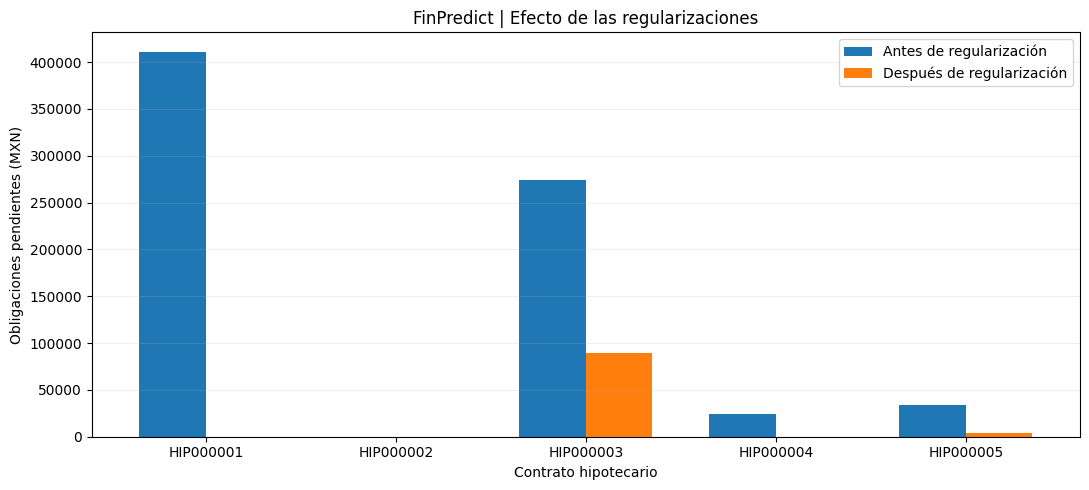

FINPREDICT | Impacto de regularizaciones
-------------------------------------------------------
Saldo anterior: $742,404.00
Saldo posterior: $94,089.55
Reducción: 87.33%
-------------------------------------------------------


In [32]:

# ============================================================
# FINPREDICT | ACTIVIDAD 5
# 29. Comparación de obligaciones pendientes
# ============================================================

# Visualizar el efecto de las regularizaciones
df_grafica = df_resultados_regularizacion.set_index(
    "id_credito"
)[["saldo_antes", "saldo_despues"]]

ax = df_grafica.plot(
    kind="bar",
    figsize=(11, 5),
    width=0.7
)

ax.set_title(
    "FinPredict | Efecto de las regularizaciones"
)
ax.set_xlabel("Contrato hipotecario")
ax.set_ylabel("Obligaciones pendientes (MXN)")
ax.tick_params(axis="x", rotation=0)
ax.grid(axis="y", alpha=0.2)

plt.legend(
    ["Antes de regularización", "Después de regularización"]
)

plt.tight_layout()
plt.show()

# Resumen monetario
saldo_total_antes = (
    df_resultados_regularizacion["saldo_antes"].sum()
)

saldo_total_despues = (
    df_resultados_regularizacion["saldo_despues"].sum()
)

reduccion_porcentual = (
    (saldo_total_antes - saldo_total_despues)
    / saldo_total_antes * 100
    if saldo_total_antes > 0 else 0
)

print("FINPREDICT | Impacto de regularizaciones")
print("-" * 55)
print(f"Saldo anterior: ${saldo_total_antes:,.2f}")
print(f"Saldo posterior: ${saldo_total_despues:,.2f}")
print(f"Reducción: {reduccion_porcentual:.2f}%")
print("-" * 55)



### 09.6. Evaluación del impacto de las regularizaciones

Se evaluó el comportamiento de cinco contratos hipotecarios sintéticos antes y después de incorporar pagos extraordinarios de regularización.

#### Resultados

| Indicador | Importe |
|---|---:|
| Obligaciones pendientes iniciales | $742,404.00 MXN |
| Obligaciones pendientes posteriores | $94,089.55 MXN |
| Reducción absoluta | $648,314.45 MXN |
| Reducción porcentual | 87.33% |
| Movimientos extraordinarios generados | 24 |

#### Interpretación

La simulación permitió reducir el saldo pendiente mediante pagos extraordinarios aplicados a las obligaciones existentes.

Se observaron diferencias entre contratos: algunos presentaron regularización casi completa, mientras otros conservaron obligaciones pendientes.

La reducción del 87.33% corresponde exclusivamente a cinco contratos de prueba y no constituye una estimación representativa del comportamiento de una cartera hipotecaria real.

#### Consideraciones metodológicas

Antes de ejecutar la simulación completa se integrarán controles de aplicación cronológica de pagos, precisión monetaria y evaluación de morosidad.

También se revisará la distribución final de incumplimientos, con el objetivo de comprobar que el conjunto de datos permita entrenar y comparar modelos de clasificación.

#### Conclusión

La prueba demuestra que es posible incorporar mecanismos de regularización a la simulación, manteniendo la conciliación de importes.

La lógica requiere consolidarse y validarse antes de su aplicación al universo completo de contratos.


In [34]:

# ============================================================
# FINPREDICT | ACTIVIDAD 5
# 30. Motor integrado de simulación de movimientos
# ============================================================

def simular_movimientos_finpredict(
    obligaciones_contrato,
    perfil,
    generador
):
    """
    Integra pagos ordinarios y regularizaciones trimestrales.

    Retorna los movimientos ordenados cronológicamente.
    """

    # 1. Generación de pagos ordinarios
    movimientos_ordinarios = generar_movimientos_contrato(
        obligaciones_contrato,
        perfil,
        generador
    )

    # 2. Generación de pagos extraordinarios
    movimientos_extraordinarios = generar_regularizaciones(
        obligaciones_contrato,
        movimientos_ordinarios,
        perfil,
        generador
    )

    # 3. Integración sin concatenar DataFrames vacíos
    partes = [
        df for df in [
            movimientos_ordinarios,
            movimientos_extraordinarios
        ]
        if not df.empty
    ]

    columnas = [
        "id_credito",
        "numero_pago_origen",
        "fecha_movimiento",
        "tipo_movimiento",
        "importe",
        "resultado_simulado"
    ]

    if partes:
        movimientos_finales = pd.concat(
            partes,
            ignore_index=True
        )
    else:
        movimientos_finales = pd.DataFrame(columns=columnas)

    # 4. Ordenar cronológicamente
    if not movimientos_finales.empty:
        movimientos_finales = (
            movimientos_finales
            .sort_values(
                ["fecha_movimiento", "numero_pago_origen"],
                na_position="last",
                kind="stable"
            )
            .reset_index(drop=True)
        )

        # Identificador único de movimiento dentro del contrato
        movimientos_finales["secuencia_movimiento"] = (
            np.arange(1, len(movimientos_finales) + 1)
        )

        # Validaciones
        assert (movimientos_finales["importe"] > 0).all()

        assert (
            movimientos_finales["fecha_movimiento"] <= FECHA_FIN
        ).all()

        assert movimientos_finales[
            "id_credito"
        ].eq(obligaciones_contrato["id_credito"].iloc[0]).all()

    return movimientos_finales


print("FINPREDICT | Motor integrado definido correctamente.")


FINPREDICT | Motor integrado definido correctamente.


In [35]:

# ============================================================
# FINPREDICT | ACTIVIDAD 5
# 31. Prueba integral del motor de simulación
# ============================================================

# Generador independiente para reproducibilidad
rng_integracion = np.random.default_rng(2027)

resultados_integracion = []
movimientos_integrados = []

for id_credito in ids_prueba:

    # Recuperar obligaciones y perfil
    obligaciones_credito = df_simulacion.loc[
        df_simulacion["id_credito"] == id_credito
    ]

    perfil = obligaciones_credito[
        "perfil_simulacion"
    ].iloc[0]

    # Ejecutar motor integrado
    movimientos = simular_movimientos_finpredict(
        obligaciones_credito,
        perfil,
        rng_integracion
    )

    if not movimientos.empty:
        movimientos_integrados.append(movimientos)

    # Conciliación financiera al cierre
    total_exigible = obligaciones_credito[
        "importe_exigible"
    ].sum()

    total_pagado = movimientos["importe"].sum()

    saldo_pendiente = max(
        round(float(total_exigible - total_pagado), 2),
        0
    )

    anticipo = max(
        round(float(total_pagado - total_exigible), 2),
        0
    )

    num_regularizaciones = (
        movimientos["resultado_simulado"]
        .eq("REGULARIZACION")
        .sum()
    )

    resultados_integracion.append({
        "id_credito": id_credito,
        "perfil": perfil,
        "obligaciones": len(obligaciones_credito),
        "movimientos": len(movimientos),
        "regularizaciones": int(num_regularizaciones),
        "total_exigible": round(total_exigible, 2),
        "total_pagado": round(total_pagado, 2),
        "saldo_pendiente": saldo_pendiente,
        "anticipo": anticipo
    })

df_integracion = pd.DataFrame(resultados_integracion)

df_movimientos_integrados = (
    pd.concat(movimientos_integrados, ignore_index=True)
    if movimientos_integrados
    else pd.DataFrame()
)

# Validaciones de integridad
assert len(df_integracion) == len(ids_prueba)

assert np.allclose(
    df_integracion["total_exigible"]
    + df_integracion["anticipo"],
    df_integracion["total_pagado"]
    + df_integracion["saldo_pendiente"],
    atol=0.01
)

assert df_movimientos_integrados[
    "fecha_movimiento"
].le(FECHA_FIN).all()

assert df_movimientos_integrados[
    "importe"
].gt(0).all()

print("FINPREDICT | Prueba integral del motor")
print("-" * 60)

display(df_integracion)

print(
    f"Movimientos totales: "
    f"{len(df_movimientos_integrados):,}"
)

print(
    f"Regularizaciones generadas: "
    f"{df_integracion['regularizaciones'].sum():,}"
)

print("-" * 60)
print("Validaciones integrales satisfactorias.")


FINPREDICT | Prueba integral del motor
------------------------------------------------------------


,id_credito,perfil,obligaciones,movimientos,regularizaciones,total_exigible,total_pagado,saldo_pendiente,anticipo
0,HIP000001,RETRASO_OCASIONAL,54,61,10,2332709.28,2330504.24,2205.04,0.0
1,HIP000002,REGULAR,13,17,4,756627.95,756627.91,0.04,0.0
2,HIP000003,IRREGULAR,20,14,1,796453.00,672450.67,124002.33,0.0
3,HIP000004,REGULAR,33,33,0,789416.10,789416.10,0.00,0.0
4,HIP000005,REGULAR,33,33,0,1110679.68,1110679.68,0.00,0.0


Movimientos totales: 158
Regularizaciones generadas: 15
------------------------------------------------------------
Validaciones integrales satisfactorias.


In [36]:

# ============================================================
# FINPREDICT | ACTIVIDAD 5
# 32. Auditoría temporal y referencial del motor
# ============================================================

# Incorporar fechas de apertura para validar movimientos
df_auditoria_movimientos = df_movimientos_integrados.merge(
    df_contratos[["id_credito", "fecha_apertura"]],
    on="id_credito",
    how="left",
    validate="many_to_one"
)

# Indicadores de calidad
total = len(df_auditoria_movimientos)

sin_contrato = df_auditoria_movimientos[
    "fecha_apertura"
].isna().sum()

antes_apertura = (
    df_auditoria_movimientos["fecha_movimiento"]
    < df_auditoria_movimientos["fecha_apertura"]
).sum()

despues_cierre = (
    df_auditoria_movimientos["fecha_movimiento"]
    > FECHA_FIN
).sum()

importes_invalidos = (
    df_auditoria_movimientos["importe"] <= 0
).sum()

# Duplicados exactos de todas las columnas
duplicados_exactos = df_auditoria_movimientos.duplicated().sum()

resumen_calidad = pd.DataFrame({
    "control": [
        "Movimientos evaluados",
        "Referencias sin contrato",
        "Movimientos antes de apertura",
        "Movimientos después del cierre",
        "Importes no positivos",
        "Filas exactamente duplicadas"
    ],
    "resultado": [
        total,
        sin_contrato,
        antes_apertura,
        despues_cierre,
        importes_invalidos,
        duplicados_exactos
    ]
})

print("FINPREDICT | Auditoría de movimientos")
print("-" * 55)

display(resumen_calidad)

assert sin_contrato == 0
assert antes_apertura == 0
assert despues_cierre == 0
assert importes_invalidos == 0

print("-" * 55)
print("Validaciones temporales y referenciales satisfactorias.")


FINPREDICT | Auditoría de movimientos
-------------------------------------------------------


,control,resultado
0,Movimientos evaluados,158
1,Referencias sin contrato,0
2,Movimientos antes de apertura,0
3,Movimientos después del cierre,0
4,Importes no positivos,0
5,Filas exactamente duplicadas,0


-------------------------------------------------------
Validaciones temporales y referenciales satisfactorias.


In [37]:

# ============================================================
# FINPREDICT | ACTIVIDAD 5
# 33. Comparación histórica de morosidad
# ============================================================

id_validacion = "HIP000001"

# Obligaciones contractuales
obligaciones_credito = (
    df_simulacion.loc[
        df_simulacion["id_credito"] == id_validacion,
        ["fecha_vencimiento", "importe_exigible"]
    ]
    .sort_values("fecha_vencimiento")
    .copy()
)

# Pagos ordinarios
pagos_ordinarios = df_movimientos_integrados.loc[
    (df_movimientos_integrados["id_credito"] == id_validacion)
    & (df_movimientos_integrados["resultado_simulado"] != "REGULARIZACION")
].copy()

# Pagos incluyendo regularizaciones
pagos_integrados = df_movimientos_integrados.loc[
    df_movimientos_integrados["id_credito"] == id_validacion
].copy()


def estado_credito_en_fecha(obligaciones, pagos, fecha):
    """
    Calcula saldo vencido y días de atraso al corte.
    Los pagos se aplican a las obligaciones más antiguas.
    """

    fecha = pd.Timestamp(fecha)

    vencidas = obligaciones.loc[
        obligaciones["fecha_vencimiento"] <= fecha
    ].copy()

    pagado = round(float(
        pagos.loc[
            pagos["fecha_movimiento"] <= fecha,
            "importe"
        ].sum()
    ), 2)

    # Importe pendiente de cada obligación bajo FIFO
    importes = vencidas["importe_exigible"].to_numpy(dtype=float)

    acumulado = np.cumsum(importes)
    acumulado_anterior = acumulado - importes

    pendiente = np.clip(
        acumulado - pagado, 0, importes
    )

    saldo_vencido = round(float(pendiente.sum()), 2)

    indices_pendientes = np.flatnonzero(pendiente > 0.01)

    if len(indices_pendientes) == 0:
        dias_atraso = 0
    else:
        primera_fecha = vencidas.iloc[
            indices_pendientes[0]
        ]["fecha_vencimiento"]

        dias_atraso = max((fecha - primera_fecha).days, 0)

    return saldo_vencido, dias_atraso


# Fechas mensuales hasta diciembre 2025
fechas = pd.date_range(
    start="2025-01-31",
    end="2025-12-31",
    freq="ME"
)

resultados = []

for fecha in fechas:

    saldo_ordinario, atraso_ordinario = estado_credito_en_fecha(
        obligaciones_credito,
        pagos_ordinarios,
        fecha
    )

    saldo_integrado, atraso_integrado = estado_credito_en_fecha(
        obligaciones_credito,
        pagos_integrados,
        fecha
    )

    resultados.append({
        "fecha": fecha,
        "saldo_sin_regularizacion": saldo_ordinario,
        "saldo_con_regularizacion": saldo_integrado,
        "atraso_sin_regularizacion": atraso_ordinario,
        "atraso_con_regularizacion": atraso_integrado
    })

df_comparacion_morosidad = pd.DataFrame(resultados)

# Validaciones
assert (
    df_comparacion_morosidad["saldo_con_regularizacion"]
    <= df_comparacion_morosidad["saldo_sin_regularizacion"] + 0.01
).all()

assert (
    df_comparacion_morosidad["atraso_con_regularizacion"]
    <= df_comparacion_morosidad["atraso_sin_regularizacion"]
).all()

print("FINPREDICT | Comparación histórica de morosidad")
print("-" * 55)

display(df_comparacion_morosidad)

print("-" * 55)
print("Validación de morosidad satisfactoria.")


FINPREDICT | Comparación histórica de morosidad
-------------------------------------------------------


,fecha,saldo_sin_regularizacion,saldo_con_regularizacion,atraso_sin_regularizacion,atraso_con_regularizacion
0,2025-01-31,213289.69,8696.33,141,19
1,2025-02-28,213289.69,8696.33,139,16
2,2025-03-31,213289.69,8696.33,139,19
3,2025-04-30,213289.69,8696.33,139,18
4,2025-05-31,213289.69,8696.33,139,19
5,2025-06-30,213289.69,5026.91,138,18
6,2025-07-31,213289.69,5026.91,141,19
7,2025-08-31,230554.99,22292.21,172,19
8,2025-09-30,230554.99,959.42,171,18
9,2025-10-31,230554.99,959.42,172,19


-------------------------------------------------------
Validación de morosidad satisfactoria.


In [38]:

# ============================================================
# FINPREDICT | ACTIVIDAD 5
# 34. Control de precisión monetaria
# ============================================================

# Tolerancia monetaria para evaluar obligaciones liquidadas
TOLERANCIA_MONETARIA = 0.05

# Validar los saldos pendientes al cierre
df_precision = df_integracion[
    ["id_credito", "saldo_pendiente"]
].copy()

df_precision["saldo_material"] = np.where(
    df_precision["saldo_pendiente"] <= TOLERANCIA_MONETARIA,
    0.0,
    df_precision["saldo_pendiente"]
)

df_precision["diferencia_residual"] = (
    df_precision["saldo_pendiente"]
    - df_precision["saldo_material"]
).round(2)

print("FINPREDICT | Validación de precisión monetaria")
print("-" * 55)

display(df_precision)

print(
    "Contratos con diferencias residuales no materiales: "
    f"{((df_precision['saldo_pendiente'] > 0) & (df_precision['saldo_material'] == 0)).sum()}"
)

print("-" * 55)
print("Control de tolerancia aplicado correctamente.")


FINPREDICT | Validación de precisión monetaria
-------------------------------------------------------


,id_credito,saldo_pendiente,saldo_material,diferencia_residual
0,HIP000001,2205.04,2205.04,0.00
1,HIP000002,0.04,0.00,0.04
2,HIP000003,124002.33,124002.33,0.00
3,HIP000004,0.00,0.00,0.00
4,HIP000005,0.00,0.00,0.00


Contratos con diferencias residuales no materiales: 1
-------------------------------------------------------
Control de tolerancia aplicado correctamente.



### 09.7. Evaluación de morosidad con regularizaciones

Se comparó la evolución histórica de morosidad del contrato HIP000001 durante 2025, considerando dos escenarios: pagos ordinarios y pagos ordinarios complementados con regularizaciones.

#### Resultados al 31 de diciembre de 2025

| Indicador | Sin regularización | Con regularización |
|---|---:|---:|
| Saldo vencido | $252,132.77 | $2,205.04 |
| Días de atraso | 172 | 19 |

#### Interpretación

La incorporación de pagos extraordinarios permitió disminuir las obligaciones vencidas y reducir la antigüedad del saldo pendiente.

En el escenario sin regularización, el contrato mantiene una morosidad superior a 90 días.

En el escenario con regularización, los días de atraso disminuyen debido a la liquidación de obligaciones antiguas.

#### Decisiones metodológicas

- Mantener la aplicación cronológica de pagos.
- Conservar las fechas originales de vencimiento.
- Evitar utilizar movimientos posteriores a la fecha evaluada.
- Establecer una tolerancia monetaria explícita para diferencias residuales de centavos.
- Mantener separados los movimientos de simulación y las variables predictivas.

#### Conclusión

Los resultados demuestran que el mecanismo sintético de regularización permite representar trayectorias de recuperación y persistencia de morosidad.

Esta variabilidad será relevante para construir posteriormente la clasificación de incumplimiento hipotecario.


In [40]:

# ============================================================
# FINPREDICT | ACTIVIDAD 5
# 35. Configuración de la simulación completa
# ============================================================

# Semilla independiente para la simulación definitiva
SEMILLA_MOVIMIENTOS = 2028

# Generador reproducible
rng_movimientos_final = np.random.default_rng(
    SEMILLA_MOVIMIENTOS
)

# Parámetros de ejecución
TOTAL_CONTRATOS = df_simulacion["id_credito"].nunique()
TOTAL_OBLIGACIONES = len(df_simulacion)

# Validaciones previas
assert TOTAL_OBLIGACIONES == len(df_obligaciones)

assert TOTAL_CONTRATOS == 49_093

assert df_simulacion["perfil_simulacion"].notna().all()

assert not df_simulacion.duplicated(
    ["id_credito", "numero_pago"]
).any()

print("FINPREDICT | Preparación de ejecución")
print("-" * 55)
print(f"Contratos con obligaciones: {TOTAL_CONTRATOS:,}")
print(f"Obligaciones: {TOTAL_OBLIGACIONES:,}")
print(f"Semilla de simulación: {SEMILLA_MOVIMIENTOS}")
print(f"Fecha máxima permitida: {FECHA_FIN.date()}")
print("-" * 55)
print("Configuración validada. Lista para generar movimientos.")


FINPREDICT | Preparación de ejecución
-------------------------------------------------------
Contratos con obligaciones: 49,093
Obligaciones: 1,475,182
Semilla de simulación: 2028
Fecha máxima permitida: 2025-12-31
-------------------------------------------------------
Configuración validada. Lista para generar movimientos.


In [41]:

# ============================================================
# FINPREDICT | ACTIVIDAD 5
# 36. Generación completa de movimientos hipotecarios
# ============================================================

import time

inicio = time.perf_counter()

movimientos_cartera = []
contratos_procesados = 0
contratos_sin_movimientos = 0

# Recorrer contratos agrupados, evitando filtros repetitivos
for id_credito, obligaciones_credito in df_simulacion.groupby(
    "id_credito",
    sort=True
):

    perfil = obligaciones_credito[
        "perfil_simulacion"
    ].iloc[0]

    # Ejecutar el motor previamente validado
    movimientos = simular_movimientos_finpredict(
        obligaciones_credito,
        perfil,
        rng_movimientos_final
    )

    if not movimientos.empty:
        movimientos_cartera.append(movimientos)
    else:
        contratos_sin_movimientos += 1

    contratos_procesados += 1

    # Seguimiento del avance
    if contratos_procesados % 5_000 == 0:
        print(
            f"Procesados: {contratos_procesados:,} "
            f"de {TOTAL_CONTRATOS:,} contratos"
        )

# Integrar movimientos
df_movimientos = pd.concat(
    movimientos_cartera,
    ignore_index=True
)

# Orden cronológico y generación de identificadores
df_movimientos = df_movimientos.sort_values(
    ["id_credito", "fecha_movimiento", "secuencia_movimiento"],
    kind="stable"
).reset_index(drop=True)

df_movimientos.insert(
    0,
    "id_movimiento",
    [
        f"MOV{i:09d}"
        for i in range(1, len(df_movimientos) + 1)
    ]
)

tiempo_total = time.perf_counter() - inicio

# Validaciones iniciales
assert contratos_procesados == TOTAL_CONTRATOS
assert df_movimientos["id_movimiento"].is_unique
assert (df_movimientos["importe"] > 0).all()
assert (df_movimientos["fecha_movimiento"] <= FECHA_FIN).all()
assert df_movimientos["id_credito"].isin(
    df_contratos["id_credito"]
).all()

print("\nFINPREDICT | Histórico transaccional generado")
print("-" * 60)

print(f"Contratos procesados: {contratos_procesados:,}")
print(f"Contratos sin movimientos: {contratos_sin_movimientos:,}")
print(f"Movimientos generados: {len(df_movimientos):,}")

print(
    f"Regularizaciones: "
    f"{df_movimientos['resultado_simulado'].eq('REGULARIZACION').sum():,}"
)

print(
    f"Memoria del dataset: "
    f"{df_movimientos.memory_usage(deep=True).sum() / 1024**2:,.2f} MB"
)

print(f"Tiempo de ejecución: {tiempo_total / 60:.2f} minutos")

print("-" * 60)
print("Validaciones iniciales satisfactorias.")

display(df_movimientos.head(10))


Procesados: 5,000 de 49,093 contratos
Procesados: 10,000 de 49,093 contratos
Procesados: 15,000 de 49,093 contratos
Procesados: 20,000 de 49,093 contratos
Procesados: 25,000 de 49,093 contratos
Procesados: 30,000 de 49,093 contratos
Procesados: 35,000 de 49,093 contratos
Procesados: 40,000 de 49,093 contratos
Procesados: 45,000 de 49,093 contratos

FINPREDICT | Histórico transaccional generado
------------------------------------------------------------
Contratos procesados: 49,093
Contratos sin movimientos: 64
Movimientos generados: 1,584,222
Regularizaciones: 199,489
Memoria del dataset: 509.40 MB
Tiempo de ejecución: 22.86 minutos
------------------------------------------------------------
Validaciones iniciales satisfactorias.


,id_movimiento,id_credito,numero_pago_origen,fecha_movimiento,tipo_movimiento,importe,resultado_simulado,secuencia_movimiento
0,MOV000000001,HIP000001,1,2021-07-13,SPEI,43198.32,COMPLETO,1
1,MOV000000002,HIP000001,3,2021-09-17,SPEI,43198.32,COMPLETO,2
2,MOV000000003,HIP000001,4,2021-10-18,SPEI,43198.32,COMPLETO,3
3,MOV000000004,HIP000001,5,2021-11-15,SPEI,43198.32,COMPLETO,4
4,MOV000000005,HIP000001,6,2021-12-10,SPEI,43198.32,COMPLETO,5
5,MOV000000006,HIP000001,7,2022-01-21,SPEI,43198.32,COMPLETO,6
6,MOV000000007,HIP000001,8,2022-02-22,SPEI,43198.32,COMPLETO,7
7,MOV000000008,HIP000001,10,2022-04-11,SPEI,43198.32,COMPLETO,8
8,MOV000000009,HIP000001,11,2022-05-22,SPEI,43198.32,COMPLETO,9
9,MOV000000010,HIP000001,12,2022-06-11,CAJA,43198.32,COMPLETO,10


In [42]:

# ============================================================
# FINPREDICT | ACTIVIDAD 5
# 37. Respaldo de los datos sintéticos generados
# ============================================================

from google.colab import drive
from pathlib import Path

# Montar Google Drive
drive.mount("/content/drive")

# Directorio de respaldo
RUTA_RESPALDO = Path(
    "/content/drive/MyDrive/FinPredict-Actividad5/datos_ini"
)

RUTA_RESPALDO.mkdir(parents=True, exist_ok=True)

# Guardar datasets originales, sin modificar
archivos = {
    "contratos.parquet": df_contratos,
    "obligaciones.parquet": df_obligaciones,
    "movimientos.parquet": df_movimientos
}

for nombre, datos in archivos.items():

    ruta = RUTA_RESPALDO / nombre

    datos.to_parquet(
        ruta,
        index=False,
        engine="pyarrow",
        compression="snappy"
    )

    # Verificar lectura e integridad de registros
    verificacion = pd.read_parquet(ruta)

    assert len(verificacion) == len(datos)
    assert list(verificacion.columns) == list(datos.columns)

    tamano_mb = ruta.stat().st_size / (1024 ** 2)

    print(
        f"{nombre}: "
        f"{len(datos):,} registros | "
        f"{tamano_mb:.2f} MB"
    )

print("-" * 55)
print("Respaldo completado y archivos verificados.")


Mounted at /content/drive
contratos.parquet: 50,000 registros | 1.94 MB
obligaciones.parquet: 1,475,182 registros | 2.82 MB
movimientos.parquet: 1,584,222 registros | 15.48 MB
-------------------------------------------------------
Respaldo completado y archivos verificados.


In [43]:

# ============================================================
# FINPREDICT | ACTIVIDAD 5
# 38. Auditoría general del histórico transaccional
# ============================================================

# Identificadores y referencias
total_movimientos = len(df_movimientos)

ids_unicos = df_movimientos["id_movimiento"].nunique()

ids_invalidos = (
    ~df_movimientos["id_credito"].isin(
        df_contratos["id_credito"]
    )
).sum()

# Calidad de datos
duplicados_id = df_movimientos["id_movimiento"].duplicated().sum()

nulos = df_movimientos.isna().sum()

fechas_invalidas = (
    df_movimientos["fecha_movimiento"] > FECHA_FIN
).sum()

importes_invalidos = (
    df_movimientos["importe"] <= 0
).sum()

# Distribución de movimientos
resumen_tipos = (
    df_movimientos
    .groupby(["tipo_movimiento", "resultado_simulado"])
    .agg(
        movimientos=("id_movimiento", "count"),
        importe_total=("importe", "sum")
    )
    .reset_index()
)

resumen_tipos["porcentaje"] = (
    resumen_tipos["movimientos"]
    / total_movimientos * 100
).round(2)

print("FINPREDICT | Auditoría del histórico")
print("-" * 55)

print(f"Movimientos totales: {total_movimientos:,}")
print(f"Identificadores únicos: {ids_unicos:,}")
print(f"IDs duplicados: {duplicados_id:,}")
print(f"Referencias inválidas: {ids_invalidos:,}")
print(f"Fechas posteriores al cierre: {fechas_invalidas:,}")
print(f"Importes no positivos: {importes_invalidos:,}")

print("\nValores nulos por columna:")
display(nulos.to_frame("nulos"))

print("\nDistribución de movimientos:")
display(resumen_tipos)

# Validaciones
assert duplicados_id == 0
assert ids_invalidos == 0
assert fechas_invalidas == 0
assert importes_invalidos == 0

# Los nulos en numero_pago_origen son esperados
# para movimientos de regularización.
nulos_no_permitidos = [
    "id_movimiento",
    "id_credito",
    "fecha_movimiento",
    "tipo_movimiento",
    "importe",
    "resultado_simulado",
    "secuencia_movimiento"
]

assert df_movimientos[
    nulos_no_permitidos
].notna().all().all()

assert df_movimientos.loc[
    df_movimientos["resultado_simulado"] != "REGULARIZACION",
    "numero_pago_origen"
].notna().all()

print("-" * 55)
print("Auditoría general satisfactoria.")


FINPREDICT | Auditoría del histórico
-------------------------------------------------------
Movimientos totales: 1,584,222
Identificadores únicos: 1,584,222
IDs duplicados: 0
Referencias inválidas: 0
Fechas posteriores al cierre: 0
Importes no positivos: 0

Valores nulos por columna:


,nulos
id_movimiento,0
id_credito,0
numero_pago_origen,199489
fecha_movimiento,0
tipo_movimiento,0
importe,0
resultado_simulado,0
secuencia_movimiento,0



Distribución de movimientos:


,tipo_movimiento,resultado_simulado,movimientos,importe_total,porcentaje
0,CAJA,COMPLETO,311457,8.933470e+09,19.66
1,CAJA,PARCIAL,34911,5.510238e+08,2.20
2,CAJA,REGULARIZACION,49901,7.798403e+08,3.15
3,SPEI,COMPLETO,933739,2.673144e+10,58.94
4,SPEI,PARCIAL,104626,1.648270e+09,6.60
5,SPEI,REGULARIZACION,149588,2.348776e+09,9.44


-------------------------------------------------------
Auditoría general satisfactoria.



### 10.1. Auditoría general del histórico transaccional

Se realizó una auditoría sobre 1,584,222 movimientos hipotecarios sintéticos generados para el periodo 2021–2025.

#### Resultados

| Control | Resultado |
|---|---:|
| Movimientos analizados | 1,584,222 |
| Identificadores únicos | 1,584,222 |
| IDs duplicados | 0 |
| Referencias contractuales inválidas | 0 |
| Fechas posteriores al cierre | 0 |
| Importes no positivos | 0 |
| Valores nulos en numero_pago_origen | 199,489 |

#### Interpretación

Los controles ejecutados no identificaron problemas de unicidad, integridad referencial, importes no positivos ni fechas posteriores al cierre del periodo histórico.

Los 199,489 valores nulos de numero_pago_origen corresponden a movimientos de regularización, que no están asociados a una única mensualidad contractual.

Por tanto, estos valores se consideran ausencias justificadas por el diseño de la simulación y no errores que deban imputarse.

#### Distribución transaccional

Se generaron 1,245,196 pagos completos, 139,537 pagos parciales y 199,489 movimientos extraordinarios de regularización.

El canal SPEI concentra aproximadamente el 75% de los movimientos, conforme a las probabilidades definidas en la simulación.

#### Conclusión

El histórico supera los controles iniciales de integridad y consistencia implementados.

La validación completa para fines predictivos requerirá analizar la distribución de morosidad, la composición de las clases y la coherencia temporal de la variable objetivo.


In [44]:

# ============================================================
# FINPREDICT | ACTIVIDAD 5
# 39. Morosidad de la cartera al 30/09/2025
# ============================================================

# 1. Obligaciones exigibles hasta la fecha de corte
obligaciones_corte = df_obligaciones.loc[
    df_obligaciones["fecha_vencimiento"] <= FECHA_CORTE,
    ["id_credito", "fecha_vencimiento", "importe_exigible"]
].copy()

obligaciones_corte = obligaciones_corte.sort_values(
    ["id_credito", "fecha_vencimiento"]
)

# 2. Pagos efectivos hasta la fecha de corte
pagos_corte = (
    df_movimientos.loc[
        df_movimientos["fecha_movimiento"] <= FECHA_CORTE
    ]
    .groupby("id_credito")["importe"]
    .sum()
    .rename("total_pagado")
)

# 3. Acumulación de obligaciones por crédito
obligaciones_corte["exigible_acumulado"] = (
    obligaciones_corte.groupby("id_credito")["importe_exigible"]
    .cumsum()
)

obligaciones_corte = obligaciones_corte.join(
    pagos_corte,
    on="id_credito"
)

obligaciones_corte["total_pagado"] = (
    obligaciones_corte["total_pagado"].fillna(0)
)

# 4. Saldo pendiente por obligación bajo FIFO
obligaciones_corte["saldo_pendiente"] = np.clip(
    obligaciones_corte["exigible_acumulado"]
    - obligaciones_corte["total_pagado"],
    0,
    obligaciones_corte["importe_exigible"]
).round(2)

# 5. Identificar obligaciones materialmente pendientes
pendientes = obligaciones_corte.loc[
    obligaciones_corte["saldo_pendiente"] > TOLERANCIA_MONETARIA
]

# 6. Resumen de saldos y vencimiento más antiguo
resumen_morosidad = (
    pendientes.groupby("id_credito")
    .agg(
        saldo_vencido_corte=("saldo_pendiente", "sum"),
        vencimiento_antiguo=("fecha_vencimiento", "min")
    )
)

# 7. Integrar todos los contratos elegibles
df_morosidad_corte = df_elegibles[
    ["id_credito"]
].merge(
    resumen_morosidad,
    on="id_credito",
    how="left",
    validate="one_to_one"
)

df_morosidad_corte["saldo_vencido_corte"] = (
    df_morosidad_corte["saldo_vencido_corte"]
    .fillna(0)
    .round(2)
)

df_morosidad_corte["dias_atraso_corte"] = (
    FECHA_CORTE - df_morosidad_corte["vencimiento_antiguo"]
).dt.days.fillna(0).astype(int)

df_morosidad_corte["mora_90_corte"] = (
    df_morosidad_corte["dias_atraso_corte"] >= 90
).astype(int)

# Validaciones
assert len(df_morosidad_corte) == len(df_elegibles)
assert df_morosidad_corte["id_credito"].is_unique
assert (df_morosidad_corte["dias_atraso_corte"] >= 0).all()

print("FINPREDICT | Morosidad al corte")
print("-" * 55)
print(f"Contratos elegibles: {len(df_morosidad_corte):,}")
print(
    f"Contratos con saldo vencido: "
    f"{(df_morosidad_corte['saldo_vencido_corte'] > TOLERANCIA_MONETARIA).sum():,}"
)
print(
    f"Contratos con mora >= 90 días: "
    f"{df_morosidad_corte['mora_90_corte'].sum():,}"
)
print(
    f"Porcentaje mora >= 90 días: "
    f"{df_morosidad_corte['mora_90_corte'].mean():.2%}"
)
print("-" * 55)

display(df_morosidad_corte.head(10))
print("Validaciones iniciales satisfactorias.")


FINPREDICT | Morosidad al corte
-------------------------------------------------------
Contratos elegibles: 47,429
Contratos con saldo vencido: 33,222
Contratos con mora >= 90 días: 4,826
Porcentaje mora >= 90 días: 10.18%
-------------------------------------------------------


,id_credito,saldo_vencido_corte,vencimiento_antiguo,dias_atraso_corte,mora_90_corte
0,HIP000001,57.44,2025-09-12,18,0
1,HIP000002,2072.65,2025-09-14,16,0
2,HIP000003,159077.05,2025-06-10,112,1
3,HIP000004,4575.31,2025-09-13,17,0
4,HIP000005,10.23,2025-09-02,28,0
5,HIP000006,0.00,NaT,0,0
6,HIP000007,0.00,NaT,0,0
7,HIP000008,116.75,2025-09-27,3,0
8,HIP000009,14.24,2025-09-03,27,0
9,HIP000010,20744.67,2025-09-21,9,0


Validaciones iniciales satisfactorias.


In [45]:

# ============================================================
# FINPREDICT | ACTIVIDAD 5
# 40. Definición de la población predictiva
# ============================================================

# Contratos que todavía no tienen mora de 90 días
df_poblacion_predictiva = df_morosidad_corte.loc[
    df_morosidad_corte["mora_90_corte"] == 0
].copy()

# Contratos con mora de 90 días al corte
df_mora_preexistente = df_morosidad_corte.loc[
    df_morosidad_corte["mora_90_corte"] == 1
].copy()

# Validaciones
assert (
    len(df_poblacion_predictiva)
    + len(df_mora_preexistente)
    == len(df_morosidad_corte)
)

assert df_poblacion_predictiva["mora_90_corte"].eq(0).all()

assert df_poblacion_predictiva["id_credito"].is_unique

print("FINPREDICT | Población predictiva")
print("-" * 55)

print(f"Contratos elegibles: {len(df_morosidad_corte):,}")

print(
    f"Sin mora de 90 días al corte: "
    f"{len(df_poblacion_predictiva):,}"
)

print(
    f"Con mora preexistente de 90 días: "
    f"{len(df_mora_preexistente):,}"
)

print(
    f"Población predictiva: "
    f"{len(df_poblacion_predictiva) / len(df_morosidad_corte):.2%}"
)

print("-" * 55)
print("Población predictiva delimitada correctamente.")


FINPREDICT | Población predictiva
-------------------------------------------------------
Contratos elegibles: 47,429
Sin mora de 90 días al corte: 42,603
Con mora preexistente de 90 días: 4,826
Población predictiva: 89.82%
-------------------------------------------------------
Población predictiva delimitada correctamente.


In [46]:

# ============================================================
# FINPREDICT | ACTIVIDAD 5
# 41. Construcción de la variable objetivo
# ============================================================

# Fechas de evaluación
fechas_futuras = pd.date_range(
    FECHA_EVALUACION_INICIO,
    FECHA_EVALUACION_FIN,
    freq="D"
)

# Población de análisis
ids_predictivos = set(
    df_poblacion_predictiva["id_credito"]
)

# Obligaciones de la población predictiva
obligaciones_pred = df_obligaciones.loc[
    df_obligaciones["id_credito"].isin(ids_predictivos)
].copy()

# Movimientos de la población predictiva
movimientos_pred = df_movimientos.loc[
    df_movimientos["id_credito"].isin(ids_predictivos)
].copy()

# Orden temporal
obligaciones_pred = obligaciones_pred.sort_values(
    ["id_credito", "fecha_vencimiento"]
)

movimientos_pred = movimientos_pred.sort_values(
    ["id_credito", "fecha_movimiento"]
)

# Función de evaluación para un contrato
def evaluar_incumplimiento_contrato(
    obligaciones_credito,
    movimientos_credito
):
    """
    Evalúa si el crédito alcanza 90 días de mora durante
    octubre-diciembre de 2025.

    Solo utiliza pagos disponibles hasta cada fecha.
    """

    fechas_vencimiento = obligaciones_credito[
        "fecha_vencimiento"
    ].to_numpy(dtype="datetime64[ns]")

    importes = obligaciones_credito[
        "importe_exigible"
    ].to_numpy(dtype=float)

    fechas_pago = movimientos_credito[
        "fecha_movimiento"
    ].to_numpy(dtype="datetime64[ns]")

    importes_pago = movimientos_credito[
        "importe"
    ].to_numpy(dtype=float)

    acumulado_exigible = np.cumsum(importes)

    acumulado_pagos = np.cumsum(importes_pago)

    max_atraso = 0

    for fecha in fechas_futuras:

        fecha_np = np.datetime64(fecha)

        # Obligaciones vencidas hasta la fecha
        n_obligaciones = np.searchsorted(
            fechas_vencimiento,
            fecha_np,
            side="right"
        )

        # Pagos realizados hasta la fecha
        n_pagos = np.searchsorted(
            fechas_pago,
            fecha_np,
            side="right"
        )

        if n_obligaciones == 0:
            continue

        pagado = (
            acumulado_pagos[n_pagos - 1]
            if n_pagos > 0 else 0.0
        )

        # Identificar primera obligación no cubierta por FIFO
        idx_pendiente = np.searchsorted(
            acumulado_exigible[:n_obligaciones],
            pagado + TOLERANCIA_MONETARIA,
            side="right"
        )

        if idx_pendiente >= n_obligaciones:
            continue

        dias = (
            fecha_np - fechas_vencimiento[idx_pendiente]
        ) / np.timedelta64(1, "D")

        max_atraso = max(max_atraso, int(dias))

        if max_atraso >= 90:
            break

    return max_atraso, int(max_atraso >= 90)


# Evaluación por crédito
resultados_target = []

grupos_obligaciones = obligaciones_pred.groupby(
    "id_credito", sort=True
)

grupos_movimientos = {
    credito: grupo
    for credito, grupo in movimientos_pred.groupby("id_credito")
}

for id_credito, grupo_obligaciones in grupos_obligaciones:

    grupo_movimientos = grupos_movimientos.get(
        id_credito,
        movimientos_pred.iloc[0:0]
    )

    max_atraso, incumplimiento = evaluar_incumplimiento_contrato(
        grupo_obligaciones,
        grupo_movimientos
    )

    resultados_target.append({
        "id_credito": id_credito,
        "max_atraso_futuro": max_atraso,
        "incumplimiento_90d": incumplimiento
    })

df_target = pd.DataFrame(resultados_target)

# Incluir créditos sin obligaciones si existieran
df_target = (
    df_poblacion_predictiva[["id_credito"]]
    .merge(df_target, on="id_credito", how="left", validate="one_to_one")
)

df_target["max_atraso_futuro"] = (
    df_target["max_atraso_futuro"].fillna(0).astype(int)
)

df_target["incumplimiento_90d"] = (
    df_target["incumplimiento_90d"].fillna(0).astype(int)
)

# Validaciones
assert len(df_target) == len(df_poblacion_predictiva)
assert df_target["id_credito"].is_unique
assert df_target["incumplimiento_90d"].isin([0, 1]).all()

print("FINPREDICT | Variable objetivo")
print("-" * 55)
print(f"Contratos evaluados: {len(df_target):,}")
print(f"Nuevos incumplimientos: {df_target['incumplimiento_90d'].sum():,}")
print(f"Tasa de incumplimiento: {df_target['incumplimiento_90d'].mean():.2%}")
print("-" * 55)

display(df_target.head(10))


FINPREDICT | Variable objetivo
-------------------------------------------------------
Contratos evaluados: 42,603
Nuevos incumplimientos: 2,310
Tasa de incumplimiento: 5.42%
-------------------------------------------------------


,id_credito,max_atraso_futuro,incumplimiento_90d
0,HIP000001,46,0
1,HIP000002,35,0
2,HIP000004,49,0
3,HIP000005,36,0
4,HIP000006,8,0
5,HIP000007,1,0
6,HIP000008,14,0
7,HIP000009,39,0
8,HIP000010,40,0
9,HIP000011,37,0



### 10.2. Construcción y distribución de la variable objetivo

Se definió como fecha de corte predictiva el 30 de septiembre de 2025 y como ventana de evaluación el periodo comprendido entre el 1 de octubre y el 31 de diciembre de 2025.

De los 47,429 contratos elegibles, se excluyeron 4,826 que ya presentaban 90 días o más de atraso al corte, delimitando una población predictiva de 42,603 contratos.

La variable `incumplimiento_90d` identifica si un crédito alcanzó al menos 90 días de atraso durante la ventana futura, considerando las obligaciones exigibles y los pagos efectivamente realizados hasta cada fecha evaluada.

| Clase | Contratos | Porcentaje |
|---|---:|---:|
| Sin nuevo incumplimiento (0) | 40,293 | 94.58% |
| Nuevo incumplimiento (1) | 2,310 | 5.42% |
| Total | 42,603 | 100% |

**Interpretación:** la distribución ofrece ejemplos de ambas clases para desarrollar modelos supervisados, aunque presenta un desbalance que deberá considerarse durante el entrenamiento y la evaluación.

**Control temporal:** las variables predictoras se construirán exclusivamente con información disponible hasta el 30 de septiembre de 2025. La información del trimestre posterior se utilizará únicamente para definir la variable objetivo.

**Limitación:** los resultados proceden de una cartera sintética y no representan estimaciones observadas de incumplimiento del sistema hipotecario.


In [47]:

# ============================================================
# FINPREDICT | ACTIVIDAD 5
# 42. Auditoría independiente de la variable objetivo
# ============================================================

import numpy as np
import pandas as pd

# Identificar los créditos clasificados como incumplimiento
ids_incumplidos = set(
    df_target.loc[
        df_target["incumplimiento_90d"] == 1,
        "id_credito"
    ]
)

fecha_inicio = pd.Timestamp(FECHA_EVALUACION_INICIO)
fecha_fin = pd.Timestamp(FECHA_EVALUACION_FIN)

# Preparar obligaciones y pagos históricos
obligaciones_auditoria = df_obligaciones.loc[
    df_obligaciones["id_credito"].isin(ids_incumplidos),
    ["id_credito", "fecha_vencimiento", "importe_exigible"]
].sort_values(["id_credito", "fecha_vencimiento"])

movimientos_auditoria = df_movimientos.loc[
    df_movimientos["id_credito"].isin(ids_incumplidos),
    ["id_credito", "fecha_movimiento", "importe"]
].sort_values(["id_credito", "fecha_movimiento"])

grupos_pagos = {
    credito: grupo
    for credito, grupo in movimientos_auditoria.groupby("id_credito")
}

resultados_auditoria = []

for credito, obligaciones in obligaciones_auditoria.groupby("id_credito"):

    pagos = grupos_pagos.get(credito)

    fechas_vencimiento = obligaciones[
        "fecha_vencimiento"
    ].to_numpy(dtype="datetime64[ns]")

    importes = obligaciones[
        "importe_exigible"
    ].to_numpy(dtype=float)

    acumulado_exigible = np.cumsum(importes)

    if pagos is not None:
        fechas_pago = pagos[
            "fecha_movimiento"
        ].to_numpy(dtype="datetime64[ns]")

        acumulado_pagado = np.cumsum(
            pagos["importe"].to_numpy(dtype=float)
        )
    else:
        fechas_pago = np.array([], dtype="datetime64[ns]")
        acumulado_pagado = np.array([], dtype=float)

    fecha_confirmacion = pd.NaT
    saldo_confirmado = 0.0
    dias_confirmados = 0

    # Revisar todas las fechas candidatas a alcanzar 90 días
    fechas_candidatas = pd.to_datetime(
        obligaciones["fecha_vencimiento"]
        + pd.Timedelta(days=90)
    )

    fechas_candidatas = fechas_candidatas[
        fechas_candidatas <= fecha_fin
    ]

    # Si el umbral se alcanzó antes de octubre,
    # evaluar también el primer día de la ventana.
    fechas_revision = sorted(
        set(
            [fecha_inicio]
            + [
                max(fecha_inicio, fecha)
                for fecha in fechas_candidatas
            ]
        )
    )

    for fecha in fechas_revision:

        if fecha > fecha_fin:
            continue

        fecha_np = np.datetime64(fecha)

        n_vencidas = np.searchsorted(
            fechas_vencimiento,
            fecha_np,
            side="right"
        )

        n_pagos = np.searchsorted(
            fechas_pago,
            fecha_np,
            side="right"
        )

        pagado = (
            acumulado_pagado[n_pagos - 1]
            if n_pagos > 0 else 0.0
        )

        # Primera obligación pendiente con antigüedad >= 90 días
        n_antiguas = np.searchsorted(
            fechas_vencimiento,
            fecha_np - np.timedelta64(90, "D"),
            side="right"
        )

        if n_antiguas == 0:
            continue

        # Saldo no cubierto de obligaciones antiguas bajo FIFO
        saldo_antiguo = max(
            0.0,
            float(acumulado_exigible[n_antiguas - 1] - pagado)
        )

        if saldo_antiguo > TOLERANCIA_MONETARIA:

            # Identificar la primera obligación no liquidada
            indice = np.searchsorted(
                acumulado_exigible[:n_antiguas],
                pagado + TOLERANCIA_MONETARIA,
                side="right"
            )

            if indice < n_antiguas:
                fecha_confirmacion = fecha
                saldo_confirmado = round(saldo_antiguo, 2)
                dias_confirmados = int(
                    (
                        fecha_np - fechas_vencimiento[indice]
                    ) / np.timedelta64(1, "D")
                )
                break

    resultados_auditoria.append({
        "id_credito": credito,
        "fecha_confirmacion": fecha_confirmacion,
        "saldo_antiguo_pendiente": saldo_confirmado,
        "dias_atraso_confirmados": dias_confirmados,
        "incumplimiento_confirmado": int(
            pd.notna(fecha_confirmacion)
        )
    })

df_auditoria_target = pd.DataFrame(resultados_auditoria)

total_positivos = len(ids_incumplidos)
confirmados = int(
    df_auditoria_target["incumplimiento_confirmado"].sum()
)

no_confirmados = total_positivos - confirmados

print("FINPREDICT | Auditoría independiente del target")
print("-" * 60)
print(f"Incumplimientos declarados: {total_positivos:,}")
print(f"Incumplimientos confirmados: {confirmados:,}")
print(f"Sin confirmación independiente: {no_confirmados:,}")
print(
    f"Porcentaje confirmado: "
    f"{confirmados / total_positivos:.2%}"
)
print("-" * 60)

display(df_auditoria_target.head(10))

if no_confirmados == 0:
    print("Auditoría de positivos satisfactoria.")
else:
    print("ATENCIÓN: revisar incumplimientos no confirmados.")


FINPREDICT | Auditoría independiente del target
------------------------------------------------------------
Incumplimientos declarados: 2,310
Incumplimientos confirmados: 2,310
Sin confirmación independiente: 0
Porcentaje confirmado: 100.00%
------------------------------------------------------------


,id_credito,fecha_confirmacion,saldo_antiguo_pendiente,dias_atraso_confirmados,incumplimiento_confirmado
0,HIP000026,2025-10-19,12615.88,90,1
1,HIP000043,2025-11-01,17048.08,90,1
2,HIP000080,2025-11-06,11045.91,90,1
3,HIP000092,2025-11-07,2939.58,90,1
4,HIP000119,2025-10-23,3141.99,90,1
5,HIP000126,2025-10-28,5590.70,90,1
6,HIP000157,2025-10-17,6147.86,90,1
7,HIP000158,2025-10-13,3419.76,90,1
8,HIP000171,2025-12-12,2163.08,90,1
9,HIP000194,2025-12-22,43098.50,90,1


Auditoría de positivos satisfactoria.


In [48]:

# ============================================================
# FINPREDICT | ACTIVIDAD 5
# 43. Respaldo de línea base y auditoría del target
# ============================================================

from pathlib import Path
import pandas as pd

RUTA_LINEA_BASE = (
    Path("/content/drive/MyDrive/FinPredict-Actividad5")
    / "datos_ini"
    / "linea_base_2025"
)

RUTA_LINEA_BASE.mkdir(parents=True, exist_ok=True)

archivos_base = {
    "morosidad_corte_2025.parquet": df_morosidad_corte,
    "poblacion_predictiva_2025.parquet": df_poblacion_predictiva,
    "target_2025.parquet": df_target,
    "auditoria_positivos_2025.parquet": df_auditoria_target
}

for nombre, dataframe in archivos_base.items():

    ruta = RUTA_LINEA_BASE / nombre

    dataframe.to_parquet(
        ruta,
        index=False,
        engine="pyarrow",
        compression="snappy"
    )

    recuperado = pd.read_parquet(ruta)

    pd.testing.assert_frame_equal(
        dataframe.reset_index(drop=True),
        recuperado.reset_index(drop=True)
    )

    print(f"Guardado y verificado: {nombre}")

# Comprobar la concordancia del target
assert len(df_target) == 42_603
assert df_target["incumplimiento_90d"].sum() == 2_310
assert len(df_auditoria_target) == 2_310
assert df_auditoria_target["incumplimiento_confirmado"].eq(1).all()

print("-" * 60)
print("FINPREDICT | Línea base 2025 preservada correctamente")
print("Auditoría de positivos: 2,310 de 2,310 confirmados")


Guardado y verificado: morosidad_corte_2025.parquet
Guardado y verificado: poblacion_predictiva_2025.parquet
Guardado y verificado: target_2025.parquet
Guardado y verificado: auditoria_positivos_2025.parquet
------------------------------------------------------------
FINPREDICT | Línea base 2025 preservada correctamente
Auditoría de positivos: 2,310 de 2,310 confirmados



### 10.3. Preservación de la línea base y extensión histórica

La auditoría independiente de la variable objetivo confirmó los 2,310 incumplimientos positivos identificados durante octubre-diciembre de 2025, sin discrepancias.

Se conserva este resultado como línea base del proyecto.

Adicionalmente, se propone desarrollar un segundo conjunto analítico mediante ventanas históricas de observación, aprovechando los registros disponibles entre 2021 y 2025.

Ambos enfoques conservarán la definición de incumplimiento de 90 días de atraso, diferenciando explícitamente sus horizontes de predicción.

Las observaciones históricas estarán identificadas por contrato y fecha de corte. Las variables explicativas se calcularán exclusivamente con información conocida hasta cada fecha de referencia.

Para prevenir fuga de información, se respetará la separación temporal entre entrenamiento, validación y evaluación final.

La extensión histórica permitirá comparar la utilidad de un único corte temporal frente al aprendizaje a partir de múltiples periodos de comportamiento crediticio.


In [49]:

# ============================================================
# FINPREDICT | ACTIVIDAD 5
# 44. Definición de ventanas temporales históricas
# ============================================================

import pandas as pd

# Cortes trimestrales desde marzo de 2021
# hasta septiembre de 2025
fechas_corte = pd.date_range(
    start="2021-03-31",
    end="2025-09-30",
    freq="QE-DEC"
)

ventanas = []

for fecha_corte in fechas_corte:

    inicio_observacion = (
        fecha_corte - pd.DateOffset(months=3)
        + pd.Timedelta(days=1)
    )

    inicio_prediccion = fecha_corte + pd.Timedelta(days=1)

    fin_prediccion = (
        fecha_corte + pd.DateOffset(months=3)
    )

    ventanas.append({
        "inicio_observacion": inicio_observacion,
        "fecha_corte": fecha_corte,
        "inicio_prediccion": inicio_prediccion,
        "fin_prediccion": fin_prediccion
    })

df_ventanas = pd.DataFrame(ventanas)

# Excluir ventanas que excedan nuestro histórico
df_ventanas = df_ventanas.loc[
    df_ventanas["fin_prediccion"] <= FECHA_FIN
].reset_index(drop=True)

df_ventanas.insert(
    0,
    "id_ventana",
    range(1, len(df_ventanas) + 1)
)

# Identificar ventana final reservada para evaluación
df_ventanas["uso"] = "HISTORICO"

df_ventanas.loc[
    df_ventanas["fecha_corte"] == pd.Timestamp("2025-09-30"),
    "uso"
] = "EVALUACION_FINAL"

# Validaciones
assert df_ventanas["fecha_corte"].is_unique
assert df_ventanas["fin_prediccion"].max() <= FECHA_FIN
assert (df_ventanas["inicio_prediccion"] > df_ventanas["fecha_corte"]).all()

print("FINPREDICT | Calendario de ventanas históricas")
print("-" * 60)
print(f"Ventanas totales: {len(df_ventanas)}")
print(
    "Ventanas históricas: "
    f"{df_ventanas['uso'].eq('HISTORICO').sum()}"
)
print(
    "Ventanas de evaluación final: "
    f"{df_ventanas['uso'].eq('EVALUACION_FINAL').sum()}"
)
print("-" * 60)

display(df_ventanas)


FINPREDICT | Calendario de ventanas históricas
------------------------------------------------------------
Ventanas totales: 19
Ventanas históricas: 18
Ventanas de evaluación final: 1
------------------------------------------------------------


,id_ventana,inicio_observacion,fecha_corte,inicio_prediccion,fin_prediccion,uso
0,1,2021-01-01,2021-03-31,2021-04-01,2021-06-30,HISTORICO
1,2,2021-03-31,2021-06-30,2021-07-01,2021-09-30,HISTORICO
2,3,2021-07-01,2021-09-30,2021-10-01,2021-12-30,HISTORICO
3,4,2021-10-01,2021-12-31,2022-01-01,2022-03-31,HISTORICO
4,5,2022-01-01,2022-03-31,2022-04-01,2022-06-30,HISTORICO
5,6,2022-03-31,2022-06-30,2022-07-01,2022-09-30,HISTORICO
6,7,2022-07-01,2022-09-30,2022-10-01,2022-12-30,HISTORICO
7,8,2022-10-01,2022-12-31,2023-01-01,2023-03-31,HISTORICO
8,9,2023-01-01,2023-03-31,2023-04-01,2023-06-30,HISTORICO
9,10,2023-03-31,2023-06-30,2023-07-01,2023-09-30,HISTORICO


In [50]:

# ============================================================
# FINPREDICT | ACTIVIDAD 5
# 45. Corrección del calendario trimestral
# ============================================================

# Trabajamos sobre el calendario ya generado
df_ventanas = df_ventanas.copy()

# Inicio: primer día del trimestre que termina en fecha_corte
df_ventanas["inicio_observacion"] = (
    df_ventanas["fecha_corte"].dt.to_period("Q")
    .dt.start_time
)

# Inicio de predicción: día posterior al corte
df_ventanas["inicio_prediccion"] = (
    df_ventanas["fecha_corte"] + pd.Timedelta(days=1)
)

# Fin de predicción: último día del trimestre siguiente
df_ventanas["fin_prediccion"] = (
    (df_ventanas["fecha_corte"].dt.to_period("Q") + 1)
    .dt.end_time
    .dt.normalize()
)

# Validaciones temporales
assert (
    df_ventanas["inicio_observacion"]
    <= df_ventanas["fecha_corte"]
).all()

assert (
    df_ventanas["inicio_prediccion"]
    == df_ventanas["fecha_corte"] + pd.Timedelta(days=1)
).all()

assert (
    df_ventanas["fin_prediccion"]
    <= FECHA_FIN
).all()

assert (
    df_ventanas.iloc[-1]["fecha_corte"]
    == pd.Timestamp("2025-09-30")
)

assert (
    df_ventanas.iloc[-1]["fin_prediccion"]
    == pd.Timestamp("2025-12-31")
)

assert len(df_ventanas) == 19

print("FINPREDICT | Calendario trimestral corregido")
print("-" * 60)

print(f"Ventanas históricas: {df_ventanas['uso'].eq('HISTORICO').sum()}")
print(f"Evaluación final: {df_ventanas['uso'].eq('EVALUACION_FINAL').sum()}")

display(df_ventanas)

print("-" * 60)
print("Validaciones temporales satisfactorias.")


FINPREDICT | Calendario trimestral corregido
------------------------------------------------------------
Ventanas históricas: 18
Evaluación final: 1


,id_ventana,inicio_observacion,fecha_corte,inicio_prediccion,fin_prediccion,uso
0,1,2021-01-01,2021-03-31,2021-04-01,2021-06-30,HISTORICO
1,2,2021-04-01,2021-06-30,2021-07-01,2021-09-30,HISTORICO
2,3,2021-07-01,2021-09-30,2021-10-01,2021-12-31,HISTORICO
3,4,2021-10-01,2021-12-31,2022-01-01,2022-03-31,HISTORICO
4,5,2022-01-01,2022-03-31,2022-04-01,2022-06-30,HISTORICO
5,6,2022-04-01,2022-06-30,2022-07-01,2022-09-30,HISTORICO
6,7,2022-07-01,2022-09-30,2022-10-01,2022-12-31,HISTORICO
7,8,2022-10-01,2022-12-31,2023-01-01,2023-03-31,HISTORICO
8,9,2023-01-01,2023-03-31,2023-04-01,2023-06-30,HISTORICO
9,10,2023-04-01,2023-06-30,2023-07-01,2023-09-30,HISTORICO


------------------------------------------------------------
Validaciones temporales satisfactorias.


In [51]:

# ============================================================
# FINPREDICT | ACTIVIDAD 5
# 46. Construcción de observaciones contrato-periodo
# ============================================================

import pandas as pd

# Relacionar contratos con ventanas temporales
df_contrato_periodo = (
    df_contratos[
        ["id_credito", "fecha_apertura"]
    ]
    .merge(
        df_ventanas[
            [
                "id_ventana",
                "inicio_observacion",
                "fecha_corte",
                "inicio_prediccion",
                "fin_prediccion",
                "uso"
            ]
        ],
        how="cross"
    )
)

# Contratos existentes al comenzar el trimestre
df_contrato_periodo = df_contrato_periodo.loc[
    df_contrato_periodo["fecha_apertura"]
    < df_contrato_periodo["inicio_observacion"]
].copy()

# Antigüedad al corte
df_contrato_periodo["antiguedad_meses"] = (
    (
        df_contrato_periodo["fecha_corte"].dt.year
        - df_contrato_periodo["fecha_apertura"].dt.year
    ) * 12
    + (
        df_contrato_periodo["fecha_corte"].dt.month
        - df_contrato_periodo["fecha_apertura"].dt.month
    )
)

# Mantener al menos tres meses de antigüedad
df_contrato_periodo = df_contrato_periodo.loc[
    df_contrato_periodo["antiguedad_meses"] >= 3
].copy()

df_contrato_periodo = (
    df_contrato_periodo
    .sort_values(["fecha_corte", "id_credito"])
    .reset_index(drop=True)
)

# Validaciones
assert not df_contrato_periodo.duplicated(
    ["id_credito", "fecha_corte"]
).any()

assert (
    df_contrato_periodo["fecha_apertura"]
    < df_contrato_periodo["inicio_observacion"]
).all()

assert (
    df_contrato_periodo["antiguedad_meses"] >= 3
).all()

# Resumen por ventana
resumen_ventanas = (
    df_contrato_periodo
    .groupby(["id_ventana", "fecha_corte", "uso"])
    .agg(
        contratos=("id_credito", "nunique")
    )
    .reset_index()
)

print("FINPREDICT | Población histórica")
print("-" * 60)
print(
    f"Observaciones contrato-periodo: "
    f"{len(df_contrato_periodo):,}"
)
print(
    f"Contratos distintos: "
    f"{df_contrato_periodo['id_credito'].nunique():,}"
)
print(
    f"Ventanas representadas: "
    f"{df_contrato_periodo['id_ventana'].nunique()}"
)

print("\nDistribución por ventana:")
display(resumen_ventanas)

print("-" * 60)
print("Construcción contrato-periodo satisfactoria.")


FINPREDICT | Población histórica
------------------------------------------------------------
Observaciones contrato-periodo: 427,538
Contratos distintos: 44,967
Ventanas representadas: 18

Distribución por ventana:


,id_ventana,fecha_corte,uso,contratos
0,2,2021-06-30,HISTORICO,2513
1,3,2021-09-30,HISTORICO,4944
2,4,2021-12-31,HISTORICO,7499
3,5,2022-03-31,HISTORICO,10016
4,6,2022-06-30,HISTORICO,12529
5,7,2022-09-30,HISTORICO,15016
6,8,2022-12-31,HISTORICO,17575
7,9,2023-03-31,HISTORICO,19975
8,10,2023-06-30,HISTORICO,22476
9,11,2023-09-30,HISTORICO,24923


------------------------------------------------------------
Construcción contrato-periodo satisfactoria.


In [52]:

# ============================================================
# FINPREDICT | ACTIVIDAD 5
# 47. Morosidad histórica por contrato-periodo
# ============================================================

import numpy as np
import pandas as pd

# 1. Tomar los cierres trimestrales que tienen observaciones
cortes = sorted(df_contrato_periodo["fecha_corte"].unique())

resultados_mora = []

# 2. Procesar cada corte temporal por separado
for fecha_corte in cortes:

    # Obligaciones exigibles hasta el corte
    obligaciones = df_obligaciones.loc[
        df_obligaciones["fecha_vencimiento"] <= fecha_corte,
        ["id_credito", "fecha_vencimiento", "importe_exigible"]
    ].copy()

    obligaciones = obligaciones.sort_values(
        ["id_credito", "fecha_vencimiento"]
    )

    # Pagos realizados hasta el corte
    pagos = (
        df_movimientos.loc[
            df_movimientos["fecha_movimiento"] <= fecha_corte
        ]
        .groupby("id_credito")["importe"]
        .sum()
        .rename("total_pagado")
    )

    # Obligaciones acumuladas por crédito
    obligaciones["exigible_acumulado"] = (
        obligaciones.groupby("id_credito")["importe_exigible"]
        .cumsum()
    )

    obligaciones = obligaciones.join(
        pagos,
        on="id_credito"
    )

    obligaciones["total_pagado"] = (
        obligaciones["total_pagado"].fillna(0)
    )

    # Saldo pendiente de cada obligación mediante FIFO
    obligaciones["saldo_pendiente"] = np.clip(
        obligaciones["exigible_acumulado"]
        - obligaciones["total_pagado"],
        0,
        obligaciones["importe_exigible"]
    ).round(2)

    # Obligaciones con saldo materialmente pendiente
    pendientes = obligaciones.loc[
        obligaciones["saldo_pendiente"] > TOLERANCIA_MONETARIA
    ]

    resumen = (
        pendientes.groupby("id_credito")
        .agg(
            saldo_vencido=("saldo_pendiente", "sum"),
            vencimiento_antiguo=("fecha_vencimiento", "min")
        )
        .reset_index()
    )

    resumen["fecha_corte"] = fecha_corte

    resultados_mora.append(resumen)

# 3. Consolidar estados históricos
df_mora_historica = pd.concat(
    resultados_mora,
    ignore_index=True
)

# 4. Incorporar créditos sin morosidad
df_estado_historico = df_contrato_periodo.merge(
    df_mora_historica,
    on=["id_credito", "fecha_corte"],
    how="left",
    validate="one_to_one"
)

df_estado_historico["saldo_vencido"] = (
    df_estado_historico["saldo_vencido"]
    .fillna(0)
    .round(2)
)

df_estado_historico["dias_atraso"] = (
    df_estado_historico["fecha_corte"]
    - df_estado_historico["vencimiento_antiguo"]
).dt.days.fillna(0).astype(int)

df_estado_historico["mora_90_corte"] = (
    df_estado_historico["dias_atraso"] >= 90
).astype(int)

# 5. Resumen por periodo
resumen_mora_historica = (
    df_estado_historico
    .groupby(["id_ventana", "fecha_corte", "uso"])
    .agg(
        contratos=("id_credito", "count"),
        contratos_mora_90=("mora_90_corte", "sum"),
        saldo_vencido_total=("saldo_vencido", "sum")
    )
    .reset_index()
)

resumen_mora_historica["tasa_mora_90"] = (
    resumen_mora_historica["contratos_mora_90"]
    / resumen_mora_historica["contratos"]
    * 100
).round(2)

# Validaciones
assert len(df_estado_historico) == len(df_contrato_periodo)

assert not df_estado_historico.duplicated(
    ["id_credito", "fecha_corte"]
).any()

assert (df_estado_historico["dias_atraso"] >= 0).all()

print("FINPREDICT | Morosidad histórica")
print("-" * 60)
print(f"Observaciones: {len(df_estado_historico):,}")
print(
    f"Observaciones con mora >= 90 días: "
    f"{df_estado_historico['mora_90_corte'].sum():,}"
)

print("\nDistribución por trimestre:")
display(resumen_mora_historica)

print("-" * 60)
print("Morosidad histórica calculada correctamente.")


FINPREDICT | Morosidad histórica
------------------------------------------------------------
Observaciones: 427,538
Observaciones con mora >= 90 días: 36,877

Distribución por trimestre:


,id_ventana,fecha_corte,uso,contratos,contratos_mora_90,saldo_vencido_total,tasa_mora_90
0,2,2021-06-30,HISTORICO,2513,8,2.084269e+07,0.32
1,3,2021-09-30,HISTORICO,4944,70,5.023589e+07,1.42
2,4,2021-12-31,HISTORICO,7499,172,8.741103e+07,2.29
3,5,2022-03-31,HISTORICO,10016,367,1.359611e+08,3.66
4,6,2022-06-30,HISTORICO,12529,615,1.876456e+08,4.91
5,7,2022-09-30,HISTORICO,15016,861,2.425158e+08,5.73
6,8,2022-12-31,HISTORICO,17575,1166,3.023685e+08,6.63
7,9,2023-03-31,HISTORICO,19975,1367,3.598432e+08,6.84
8,10,2023-06-30,HISTORICO,22476,1691,4.361086e+08,7.52
9,11,2023-09-30,HISTORICO,24923,2111,5.154557e+08,8.47


------------------------------------------------------------
Morosidad histórica calculada correctamente.


In [53]:

# ============================================================
# FINPREDICT | ACTIVIDAD 5
# 48. Visualización financiera de morosidad histórica
# ============================================================

# Copia exclusiva para presentación
df_resumen_formateado = resumen_mora_historica.copy()

# Formato financiero
df_resumen_formateado["saldo_vencido_total"] = (
    df_resumen_formateado["saldo_vencido_total"]
    .map(lambda x: f"${x:,.2f}")
)

df_resumen_formateado["contratos"] = (
    df_resumen_formateado["contratos"]
    .map(lambda x: f"{x:,}")
)

df_resumen_formateado["contratos_mora_90"] = (
    df_resumen_formateado["contratos_mora_90"]
    .map(lambda x: f"{x:,}")
)

df_resumen_formateado["tasa_mora_90"] = (
    df_resumen_formateado["tasa_mora_90"]
    .map(lambda x: f"{x:.2f}%")
)

print("FINPREDICT | Morosidad histórica (MXN)")
print("-" * 65)

display(df_resumen_formateado)

print("-" * 65)
print("Importes presentados en pesos mexicanos.")


FINPREDICT | Morosidad histórica (MXN)
-----------------------------------------------------------------


,id_ventana,fecha_corte,uso,contratos,contratos_mora_90,saldo_vencido_total,tasa_mora_90
0,2,2021-06-30,HISTORICO,"2,513",8,"$20,842,694.10",0.32%
1,3,2021-09-30,HISTORICO,"4,944",70,"$50,235,887.06",1.42%
2,4,2021-12-31,HISTORICO,"7,499",172,"$87,411,029.51",2.29%
3,5,2022-03-31,HISTORICO,"10,016",367,"$135,961,079.95",3.66%
4,6,2022-06-30,HISTORICO,"12,529",615,"$187,645,570.35",4.91%
5,7,2022-09-30,HISTORICO,"15,016",861,"$242,515,847.54",5.73%
6,8,2022-12-31,HISTORICO,"17,575","1,166","$302,368,522.15",6.63%
7,9,2023-03-31,HISTORICO,"19,975","1,367","$359,843,166.45",6.84%
8,10,2023-06-30,HISTORICO,"22,476","1,691","$436,108,608.71",7.52%
9,11,2023-09-30,HISTORICO,"24,923","2,111","$515,455,694.37",8.47%


-----------------------------------------------------------------
Importes presentados en pesos mexicanos.


In [54]:

# ============================================================
# FINPREDICT | ACTIVIDAD 5
# 49. Delimitación de población predictiva histórica
# ============================================================

# Separar observaciones según morosidad al corte
df_historico_predictivo = df_estado_historico.loc[
    df_estado_historico["mora_90_corte"] == 0
].copy()

df_historico_excluido = df_estado_historico.loc[
    df_estado_historico["mora_90_corte"] == 1
].copy()

# Resumen trimestral
resumen_poblacion = (
    df_estado_historico
    .groupby(["id_ventana", "fecha_corte", "uso"])
    .agg(
        contratos_totales=("id_credito", "count"),
        excluidos_mora_90=("mora_90_corte", "sum")
    )
    .reset_index()
)

resumen_poblacion["poblacion_predictiva"] = (
    resumen_poblacion["contratos_totales"]
    - resumen_poblacion["excluidos_mora_90"]
)

resumen_poblacion["porcentaje_elegible"] = (
    resumen_poblacion["poblacion_predictiva"]
    / resumen_poblacion["contratos_totales"]
    * 100
).round(2)

# Validaciones
assert (
    len(df_historico_predictivo)
    + len(df_historico_excluido)
    == len(df_estado_historico)
)

assert df_historico_predictivo["mora_90_corte"].eq(0).all()

assert not df_historico_predictivo.duplicated(
    ["id_credito", "fecha_corte"]
).any()

print("FINPREDICT | Población predictiva histórica")
print("-" * 60)

print(f"Observaciones originales: {len(df_estado_historico):,}")
print(f"Observaciones predictivas: {len(df_historico_predictivo):,}")
print(f"Observaciones excluidas: {len(df_historico_excluido):,}")

print("\nDistribución por trimestre:")
display(resumen_poblacion)

print("-" * 60)
print("Población predictiva histórica delimitada.")


FINPREDICT | Población predictiva histórica
------------------------------------------------------------
Observaciones originales: 427,538
Observaciones predictivas: 390,661
Observaciones excluidas: 36,877

Distribución por trimestre:


,id_ventana,fecha_corte,uso,contratos_totales,excluidos_mora_90,poblacion_predictiva,porcentaje_elegible
0,2,2021-06-30,HISTORICO,2513,8,2505,99.68
1,3,2021-09-30,HISTORICO,4944,70,4874,98.58
2,4,2021-12-31,HISTORICO,7499,172,7327,97.71
3,5,2022-03-31,HISTORICO,10016,367,9649,96.34
4,6,2022-06-30,HISTORICO,12529,615,11914,95.09
5,7,2022-09-30,HISTORICO,15016,861,14155,94.27
6,8,2022-12-31,HISTORICO,17575,1166,16409,93.37
7,9,2023-03-31,HISTORICO,19975,1367,18608,93.16
8,10,2023-06-30,HISTORICO,22476,1691,20785,92.48
9,11,2023-09-30,HISTORICO,24923,2111,22812,91.53


------------------------------------------------------------
Población predictiva histórica delimitada.


In [55]:

# ============================================================
# FINPREDICT | ACTIVIDAD 5
# 50. Construcción del target histórico por trimestre
# ============================================================

import numpy as np
import pandas as pd

TOLERANCIA = TOLERANCIA_MONETARIA

# Conservamos la población histórica original
df_base_target = df_historico_predictivo[
    [
        "id_credito",
        "id_ventana",
        "fecha_corte",
        "inicio_prediccion",
        "fin_prediccion",
        "uso"
    ]
].copy()

# Preparar pagos acumulados de cada contrato
pagos_ordenados = df_movimientos[
    ["id_credito", "fecha_movimiento", "importe"]
].sort_values(
    ["id_credito", "fecha_movimiento"]
)

pagos_ordenados["pagado_acumulado"] = (
    pagos_ordenados.groupby("id_credito")["importe"].cumsum()
)

# Preparar obligaciones acumuladas
obligaciones_ordenadas = df_obligaciones[
    ["id_credito", "fecha_vencimiento", "importe_exigible"]
].sort_values(
    ["id_credito", "fecha_vencimiento"]
)

obligaciones_ordenadas["exigible_acumulado"] = (
    obligaciones_ordenadas.groupby("id_credito")[
        "importe_exigible"
    ].cumsum()
)

# Evaluación por fecha de ventana:
# una obligación alcanza 90 DPD cuando su saldo sigue pendiente
# al cumplirse 90 días desde el vencimiento.

resultados = []

for ventana in df_ventanas.itertuples(index=False):

    poblacion = df_base_target.loc[
        df_base_target["id_ventana"] == ventana.id_ventana,
        "id_credito"
    ]

    if poblacion.empty:
        continue

    # Obligaciones que alcanzan 90 días durante el trimestre.
    # Incluimos la fecha inicial para verificar cualquier
    # obligación antigua materialmente pendiente.
    obligaciones_evaluar = obligaciones_ordenadas.loc[
        obligaciones_ordenadas["id_credito"].isin(poblacion)
        & (
            obligaciones_ordenadas["fecha_vencimiento"]
            <= ventana.fin_prediccion - pd.Timedelta(days=90)
        )
    ].copy()

    obligaciones_evaluar["fecha_revision"] = (
        obligaciones_evaluar["fecha_vencimiento"]
        + pd.Timedelta(days=90)
    )

    obligaciones_evaluar["fecha_revision"] = (
        obligaciones_evaluar["fecha_revision"]
        .clip(lower=ventana.inicio_prediccion)
    )

    # Solo evaluar fechas dentro de la ventana
    obligaciones_evaluar = obligaciones_evaluar.loc[
        obligaciones_evaluar["fecha_revision"]
        <= ventana.fin_prediccion
    ].copy()

    # Pagos acumulados hasta cada fecha de revisión
    pagos_ventana = pagos_ordenados.loc[
        pagos_ordenados["id_credito"].isin(poblacion),
        ["id_credito", "fecha_movimiento", "pagado_acumulado"]
    ].copy()

    obligaciones_evaluar = obligaciones_evaluar.sort_values(
        ["fecha_revision", "id_credito"]
    )

    pagos_ventana = pagos_ventana.sort_values(
        ["fecha_movimiento", "id_credito"]
    )

    conciliacion = pd.merge_asof(
        obligaciones_evaluar,
        pagos_ventana,
        left_on="fecha_revision",
        right_on="fecha_movimiento",
        by="id_credito",
        direction="backward",
        allow_exact_matches=True
    )

    conciliacion["pagado_acumulado"] = (
        conciliacion["pagado_acumulado"].fillna(0)
    )

    # Saldo de obligaciones que ya tienen 90 días
    conciliacion["saldo_90_pendiente"] = (
        conciliacion["exigible_acumulado"]
        - conciliacion["pagado_acumulado"]
    ).clip(lower=0)

    conciliacion["evento_90"] = (
        conciliacion["saldo_90_pendiente"] > TOLERANCIA
    ).astype(int)

    # Una etiqueta por contrato y ventana
    etiquetas = (
        conciliacion.groupby("id_credito")["evento_90"]
        .max()
        .rename("incumplimiento_90d")
        .reset_index()
    )

    etiquetas["id_ventana"] = ventana.id_ventana
    resultados.append(etiquetas)

# Integración
df_target_historico = pd.concat(
    resultados,
    ignore_index=True
)

df_target_historico = df_base_target.merge(
    df_target_historico,
    on=["id_credito", "id_ventana"],
    how="left",
    validate="one_to_one"
)

df_target_historico["incumplimiento_90d"] = (
    df_target_historico["incumplimiento_90d"]
    .fillna(0)
    .astype(int)
)

# Validaciones
assert len(df_target_historico) == len(df_base_target)

assert not df_target_historico.duplicated(
    ["id_credito", "id_ventana"]
).any()

assert df_target_historico["incumplimiento_90d"].isin([0, 1]).all()

# Resumen
resumen_target_historico = (
    df_target_historico
    .groupby(["id_ventana", "fecha_corte", "uso"])
    .agg(
        observaciones=("id_credito", "count"),
        incumplimientos=("incumplimiento_90d", "sum")
    )
    .reset_index()
)

resumen_target_historico["tasa_incumplimiento"] = (
    resumen_target_historico["incumplimientos"]
    / resumen_target_historico["observaciones"] * 100
).round(2)

print("FINPREDICT | Target histórico")
print("-" * 60)

print(f"Observaciones etiquetadas: {len(df_target_historico):,}")
print(
    f"Eventos de incumplimiento: "
    f"{df_target_historico['incumplimiento_90d'].sum():,}"
)

display(resumen_target_historico)

print("-" * 60)
print("Etiquetado histórico completado.")


FINPREDICT | Target histórico
------------------------------------------------------------
Observaciones etiquetadas: 390,661
Eventos de incumplimiento: 23,650


,id_ventana,fecha_corte,uso,observaciones,incumplimientos,tasa_incumplimiento
0,2,2021-06-30,HISTORICO,2505,112,4.47
1,3,2021-09-30,HISTORICO,4874,254,5.21
2,4,2021-12-31,HISTORICO,7327,491,6.70
3,5,2022-03-31,HISTORICO,9649,682,7.07
4,6,2022-06-30,HISTORICO,11914,807,6.77
5,7,2022-09-30,HISTORICO,14155,950,6.71
6,8,2022-12-31,HISTORICO,16409,1029,6.27
7,9,2023-03-31,HISTORICO,18608,1208,6.49
8,10,2023-06-30,HISTORICO,20785,1405,6.76
9,11,2023-09-30,HISTORICO,22812,1396,6.12


------------------------------------------------------------
Etiquetado histórico completado.


In [56]:

# ============================================================
# FINPREDICT | ACTIVIDAD 5
# 51. Conciliación de la evaluación final
# ============================================================

# Última ventana histórica
df_final_historico = df_target_historico.loc[
    df_target_historico["uso"] == "EVALUACION_FINAL",
    ["id_credito", "incumplimiento_90d"]
].rename(
    columns={
        "incumplimiento_90d": "target_historico"
    }
)

# Comparar contra la línea base original
df_conciliacion_target = df_final_historico.merge(
    df_target[["id_credito", "incumplimiento_90d"]].rename(
        columns={
            "incumplimiento_90d": "target_linea_base"
        }
    ),
    on="id_credito",
    how="left",
    validate="one_to_one",
    indicator=True
)

# Coincidencia de etiquetas
df_conciliacion_target["coincide"] = (
    df_conciliacion_target["target_historico"]
    == df_conciliacion_target["target_linea_base"]
)

# Contratos exclusivos de la línea base
ids_finales = set(df_final_historico["id_credito"])

df_exclusivos_base = df_target.loc[
    ~df_target["id_credito"].isin(ids_finales)
]

# Resumen
print("FINPREDICT | Conciliación del target final")
print("-" * 60)

print(
    f"Contratos comparados: "
    f"{len(df_conciliacion_target):,}"
)

print(
    f"Etiquetas coincidentes: "
    f"{df_conciliacion_target['coincide'].sum():,}"
)

print(
    f"Etiquetas diferentes: "
    f"{(~df_conciliacion_target['coincide']).sum():,}"
)

print(
    f"Positivos históricos: "
    f"{df_conciliacion_target['target_historico'].sum():,}"
)

print(
    f"Positivos línea base (misma población): "
    f"{df_conciliacion_target['target_linea_base'].sum():,.0f}"
)

print(
    f"Contratos excluidos por antigüedad: "
    f"{len(df_exclusivos_base):,}"
)

print(
    f"Positivos entre los excluidos: "
    f"{df_exclusivos_base['incumplimiento_90d'].sum():,}"
)

print("\nMatriz de coincidencia:")
display(
    pd.crosstab(
        df_conciliacion_target["target_linea_base"],
        df_conciliacion_target["target_historico"],
        rownames=["Línea base"],
        colnames=["Histórico"],
        dropna=False
    )
)

print("-" * 60)

if df_conciliacion_target["coincide"].all():
    print("Conciliación satisfactoria: etiquetas coincidentes.")
else:
    print("ATENCIÓN: existen discrepancias por investigar.")


FINPREDICT | Conciliación del target final
------------------------------------------------------------
Contratos comparados: 40,141
Etiquetas coincidentes: 40,141
Etiquetas diferentes: 0
Positivos históricos: 2,282
Positivos línea base (misma población): 2,282
Contratos excluidos por antigüedad: 2,462
Positivos entre los excluidos: 28

Matriz de coincidencia:


Histórico,0,1
Línea base,,
0,37859,0
1,0,2282


------------------------------------------------------------
Conciliación satisfactoria: etiquetas coincidentes.



### 10.4. Conciliación de la variable objetivo histórica

Se realizó una conciliación entre el etiquetado histórico de FinPredict y la línea base previamente validada, utilizando la misma ventana de predicción: octubre–diciembre de 2025.

**Resultados de conciliación:**

| Indicador | Resultado |
|---|---:|
| Contratos comparados | 40,141 |
| Etiquetas coincidentes | 40,141 |
| Etiquetas diferentes | 0 |
| Incumplimientos confirmados | 2,282 |
| Contratos excluidos por antigüedad | 2,462 |
| Incumplimientos entre excluidos | 28 |

La línea base original contiene 2,310 incumplimientos, mientras que la evaluación histórica contiene 2,282. La diferencia corresponde íntegramente a los 28 casos positivos entre los contratos excluidos por la condición adicional de antigüedad.

**Conclusión:** ambos procedimientos generan etiquetas idénticas para la población compartida. Esta conciliación respalda la consistencia del etiquetado histórico frente a la línea base previamente auditada.

La concordancia del 100% corresponde a procedimientos de etiquetado sobre datos sintéticos y no representa el desempeño de un modelo predictivo.


In [57]:

# ============================================================
# FINPREDICT | ACTIVIDAD 5
# 52. Integración de variables contractuales y morosidad
# ============================================================

import pandas as pd
import numpy as np

# 1. Recuperar columnas contractuales
variables_contractuales = [
    "id_credito",
    "fecha_apertura",
    "monto_original",
    "plazo_meses",
    "tasa_interes_anual",
    "pago_mensual",
    "ingreso_mensual",
    "tipo_empleo",
    "edad",
    "region"
]

df_variables_contrato = df_contratos[
    variables_contractuales
].copy()

# 2. Seleccionar estado histórico de morosidad
variables_estado = [
    "id_credito",
    "fecha_corte",
    "saldo_vencido",
    "dias_atraso",
    "mora_90_corte",
    "antiguedad_meses"
]

df_variables_estado = df_estado_historico[
    variables_estado
].copy()

# 3. Integrar con las observaciones etiquetadas
df_analitico = (
    df_target_historico
    .merge(
        df_variables_estado,
        on=["id_credito", "fecha_corte"],
        how="left",
        validate="one_to_one"
    )
    .merge(
        df_variables_contrato,
        on="id_credito",
        how="left",
        validate="many_to_one"
    )
)

# 4. Crear indicadores financieros
df_analitico["relacion_pago_ingreso"] = (
    df_analitico["pago_mensual"]
    / df_analitico["ingreso_mensual"]
)

df_analitico["saldo_vencido_mensualidades"] = (
    df_analitico["saldo_vencido"]
    / df_analitico["pago_mensual"]
)

# 5. Validaciones
assert len(df_analitico) == len(df_target_historico)

assert not df_analitico.duplicated(
    ["id_credito", "fecha_corte"]
).any()

assert df_analitico["monto_original"].notna().all()
assert df_analitico["saldo_vencido"].notna().all()

assert df_analitico["mora_90_corte"].eq(0).all()

assert np.isfinite(
    df_analitico[
        [
            "relacion_pago_ingreso",
            "saldo_vencido_mensualidades"
        ]
    ].to_numpy()
).all()

print("FINPREDICT | Dataset analítico inicial")
print("-" * 60)

print(f"Observaciones: {len(df_analitico):,}")
print(f"Contratos distintos: {df_analitico['id_credito'].nunique():,}")
print(f"Variables disponibles: {df_analitico.shape[1]}")

print("\nColumnas del dataset:")
display(
    pd.DataFrame({
        "variable": df_analitico.columns,
        "tipo_dato": df_analitico.dtypes.astype(str).values,
        "nulos": df_analitico.isna().sum().values
    })
)

print("\nPrimeros registros:")
display(df_analitico.head())

print("-" * 60)
print("Integración contractual satisfactoria.")


FINPREDICT | Dataset analítico inicial
------------------------------------------------------------
Observaciones: 390,661
Contratos distintos: 44,913
Variables disponibles: 22

Columnas del dataset:


,variable,tipo_dato,nulos
0,id_credito,object,0
1,id_ventana,int64,0
2,fecha_corte,datetime64[ns],0
3,inicio_prediccion,datetime64[ns],0
4,fin_prediccion,datetime64[ns],0
5,uso,object,0
6,incumplimiento_90d,int64,0
7,saldo_vencido,float64,0
8,dias_atraso,int64,0
9,mora_90_corte,int64,0



Primeros registros:


,id_credito,id_ventana,fecha_corte,inicio_prediccion,fin_prediccion,uso,incumplimiento_90d,saldo_vencido,dias_atraso,mora_90_corte,...,monto_original,plazo_meses,tasa_interes_anual,pago_mensual,ingreso_mensual,tipo_empleo,edad,region,relacion_pago_ingreso,saldo_vencido_mensualidades
0,HIP000056,2,2021-06-30,2021-07-01,2021-09-30,HISTORICO,0,0.00,0,0,...,4722743.85,240,7.2769,37404.45,126056.44,ASALARIADO,61,CENTRO,0.296728,0.000000
1,HIP000104,2,2021-06-30,2021-07-01,2021-09-30,HISTORICO,1,35821.56,77,0,...,1326400.32,180,9.4087,13777.62,39595.59,ASALARIADO,42,SUR,0.347958,2.599982
2,HIP000117,2,2021-06-30,2021-07-01,2021-09-30,HISTORICO,0,0.00,0,0,...,1974095.99,240,12.5357,22478.21,60683.97,ASALARIADO,58,CENTRO,0.370414,0.000000
3,HIP000138,2,2021-06-30,2021-07-01,2021-09-30,HISTORICO,0,25974.68,4,0,...,3820423.14,240,13.1484,45163.65,141560.63,ASALARIADO,60,OCCIDENTE,0.319041,0.575124
4,HIP000147,2,2021-06-30,2021-07-01,2021-09-30,HISTORICO,0,0.00,0,0,...,1247588.90,180,13.0883,15857.58,52555.36,INDEPENDIENTE,54,NORTE,0.301731,0.000000


------------------------------------------------------------
Integración contractual satisfactoria.


In [58]:

# ============================================================
# FINPREDICT | ACTIVIDAD 5
# 53. Ingeniería de características transaccionales
# ============================================================

import numpy as np
import pandas as pd

# Ventanas de observación
ventanas_observacion = df_ventanas[
    ["id_ventana", "inicio_observacion", "fecha_corte"]
].copy()

# 1. Relacionar movimientos con los trimestres
movimientos_3m = df_movimientos.merge(
    ventanas_observacion,
    how="cross"
)

movimientos_3m = movimientos_3m.loc[
    (movimientos_3m["fecha_movimiento"] >= movimientos_3m["inicio_observacion"])
    & (movimientos_3m["fecha_movimiento"] <= movimientos_3m["fecha_corte"])
].copy()

# 2. Agregar comportamiento por crédito y ventana
movimientos_3m["es_parcial"] = (
    movimientos_3m["resultado_simulado"] == "PARCIAL"
).astype(int)

movimientos_3m["es_regularizacion"] = (
    movimientos_3m["resultado_simulado"] == "REGULARIZACION"
).astype(int)

resumen_movimientos_3m = (
    movimientos_3m
    .groupby(["id_credito", "id_ventana"])
    .agg(
        importe_pagado_3m=("importe", "sum"),
        numero_pagos_3m=("importe", "count"),
        pagos_parciales_3m=("es_parcial", "sum"),
        regularizaciones_3m=("es_regularizacion", "sum")
    )
    .reset_index()
)

# 3. Obligaciones exigibles durante el trimestre
obligaciones_3m = df_obligaciones.merge(
    ventanas_observacion,
    how="cross"
)

obligaciones_3m = obligaciones_3m.loc[
    (obligaciones_3m["fecha_vencimiento"] >= obligaciones_3m["inicio_observacion"])
    & (obligaciones_3m["fecha_vencimiento"] <= obligaciones_3m["fecha_corte"])
].copy()

resumen_obligaciones_3m = (
    obligaciones_3m
    .groupby(["id_credito", "id_ventana"])
    .agg(
        importe_exigible_3m=("importe_exigible", "sum"),
        obligaciones_3m=("importe_exigible", "count")
    )
    .reset_index()
)

# 4. Integrar variables al dataset analítico
df_analitico = (
    df_analitico
    .merge(
        resumen_movimientos_3m,
        on=["id_credito", "id_ventana"],
        how="left",
        validate="one_to_one"
    )
    .merge(
        resumen_obligaciones_3m,
        on=["id_credito", "id_ventana"],
        how="left",
        validate="one_to_one"
    )
)

columnas_3m = [
    "importe_pagado_3m",
    "numero_pagos_3m",
    "pagos_parciales_3m",
    "regularizaciones_3m",
    "importe_exigible_3m",
    "obligaciones_3m"
]

df_analitico[columnas_3m] = (
    df_analitico[columnas_3m].fillna(0)
)

# 5. Indicador de cobertura transaccional
df_analitico["porcentaje_pago_3m"] = np.where(
    df_analitico["importe_exigible_3m"] > 0,
    df_analitico["importe_pagado_3m"]
    / df_analitico["importe_exigible_3m"],
    np.nan
)

# Validaciones
assert len(df_analitico) == 390_661

assert not df_analitico.duplicated(
    ["id_credito", "fecha_corte"]
).any()

assert (
    df_analitico[columnas_3m] >= 0
).all().all()

print("FINPREDICT | Variables transaccionales trimestrales")
print("-" * 60)

print(f"Observaciones: {len(df_analitico):,}")
print(f"Columnas totales: {df_analitico.shape[1]}")

print("\nEstadísticas de comportamiento:")
display(
    df_analitico[
        columnas_3m + ["porcentaje_pago_3m"]
    ].describe().round(2)
)

print("\nValores nulos:")
display(
    df_analitico[
        columnas_3m + ["porcentaje_pago_3m"]
    ].isna().sum().to_frame("nulos")
)

print("-" * 60)
print("Variables transaccionales integradas.")


FINPREDICT | Variables transaccionales trimestrales
------------------------------------------------------------
Observaciones: 390,661
Columnas totales: 29

Estadísticas de comportamiento:


,importe_pagado_3m,numero_pagos_3m,pagos_parciales_3m,regularizaciones_3m,importe_exigible_3m,obligaciones_3m,porcentaje_pago_3m
count,390661.00,390661.00,390661.00,390661.00,390661.00,390661.0,390661.00
mean,85968.34,3.32,0.23,0.44,85908.61,3.0,1.00
std,52408.10,0.64,0.50,0.50,47088.28,0.0,0.23
min,0.00,0.00,0.00,0.00,6263.49,3.0,0.00
25%,44033.69,3.00,0.00,0.00,46203.30,3.0,0.98
50%,80520.48,3.00,0.00,0.00,83748.54,3.0,1.00
75%,119606.16,4.00,0.00,1.00,120527.01,3.0,1.01
max,897048.71,5.00,4.00,1.00,239593.95,3.0,7.28



Valores nulos:


,nulos
importe_pagado_3m,0
numero_pagos_3m,0
pagos_parciales_3m,0
regularizaciones_3m,0
importe_exigible_3m,0
obligaciones_3m,0
porcentaje_pago_3m,0


------------------------------------------------------------
Variables transaccionales integradas.


In [59]:

# ============================================================
# FINPREDICT | ACTIVIDAD 5
# 54. Auditoría de cobertura transaccional
# ============================================================

import pandas as pd
import numpy as np

# Clasificación descriptiva de cobertura
condiciones = [
    df_analitico["porcentaje_pago_3m"] == 0,
    df_analitico["porcentaje_pago_3m"].between(
        0, 0.95, inclusive="left"
    ),
    df_analitico["porcentaje_pago_3m"].between(
        0.95, 1.05, inclusive="both"
    ),
    df_analitico["porcentaje_pago_3m"] > 1.05
]

categorias = [
    "SIN_PAGOS",
    "COBERTURA_BAJA",
    "COBERTURA_CERCANA_100",
    "COBERTURA_SUPERIOR_105"
]

df_analitico["categoria_cobertura_3m"] = np.select(
    condiciones,
    categorias,
    default="REVISAR"
)

# Resumen de distribuciones
resumen_cobertura = (
    df_analitico
    .groupby("categoria_cobertura_3m")
    .agg(
        observaciones=("id_credito", "count"),
        incumplimientos=("incumplimiento_90d", "sum"),
        cobertura_media=("porcentaje_pago_3m", "mean")
    )
    .reset_index()
)

resumen_cobertura["porcentaje_observaciones"] = (
    resumen_cobertura["observaciones"]
    / len(df_analitico) * 100
).round(2)

resumen_cobertura["tasa_incumplimiento"] = (
    resumen_cobertura["incumplimientos"]
    / resumen_cobertura["observaciones"] * 100
).round(2)

# Observaciones con mayor cobertura
mayores_coberturas = (
    df_analitico[
        [
            "id_credito",
            "fecha_corte",
            "importe_pagado_3m",
            "importe_exigible_3m",
            "porcentaje_pago_3m",
            "regularizaciones_3m",
            "incumplimiento_90d"
        ]
    ]
    .nlargest(10, "porcentaje_pago_3m")
)

print("FINPREDICT | Auditoría de cobertura")
print("-" * 60)

print("Distribución:")
display(resumen_cobertura)

print("\n10 coberturas más altas:")
display(
    mayores_coberturas.style.format({
        "importe_pagado_3m": "${:,.2f}",
        "importe_exigible_3m": "${:,.2f}",
        "porcentaje_pago_3m": "{:.2%}"
    })
)

print("-" * 60)
print("Auditoría descriptiva completada.")


FINPREDICT | Auditoría de cobertura
------------------------------------------------------------
Distribución:


,categoria_cobertura_3m,observaciones,incumplimientos,cobertura_media,porcentaje_observaciones,tasa_incumplimiento
0,COBERTURA_BAJA,84969,16219,0.754150,21.75,19.09
1,COBERTURA_CERCANA_100,237239,3318,1.001725,60.73,1.40
2,COBERTURA_SUPERIOR_105,68404,4067,1.304214,17.51,5.95
3,SIN_PAGOS,49,46,0.000000,0.01,93.88



10 coberturas más altas:


,id_credito,fecha_corte,importe_pagado_3m,importe_exigible_3m,porcentaje_pago_3m,regularizaciones_3m,incumplimiento_90d
241802,HIP048969,2024-09-30 00:00:00,"$423,356.46","$58,120.53",728.41%,1.000000,0
385837,HIP044008,2025-09-30 00:00:00,"$498,889.11","$76,079.58",655.75%,1.000000,0
325286,HIP016921,2025-06-30 00:00:00,"$691,370.38","$109,583.58",630.91%,1.000000,0
388689,HIP047537,2025-09-30 00:00:00,"$825,396.52","$131,778.93",626.35%,1.000000,0
384076,HIP041818,2025-09-30 00:00:00,"$655,601.82","$106,043.94",618.24%,1.000000,1
372277,HIP027097,2025-09-30 00:00:00,"$623,336.70","$101,670.72",613.09%,1.000000,0
173053,HIP034593,2024-03-31 00:00:00,"$241,649.68","$39,648.90",609.47%,1.000000,0
336125,HIP031168,2025-06-30 00:00:00,"$771,631.09","$129,393.87",596.34%,1.000000,0
358358,HIP009809,2025-09-30 00:00:00,"$482,869.15","$81,648.30",591.40%,1.000000,0
305475,HIP040403,2025-03-31 00:00:00,"$284,284.61","$49,359.24",575.95%,1.000000,1


------------------------------------------------------------
Auditoría descriptiva completada.


In [60]:

# ============================================================
# FINPREDICT | ACTIVIDAD 5
# 55. Auditoría de cobertura acumulada por contrato-corte
# ============================================================

import pandas as pd
import numpy as np

# Acumular obligaciones cronológicamente
obligaciones_acum = df_obligaciones[
    ["id_credito", "fecha_vencimiento", "importe_exigible"]
].copy()

obligaciones_acum = obligaciones_acum.sort_values(
    ["id_credito", "fecha_vencimiento"]
)

obligaciones_acum["exigible_acumulado"] = (
    obligaciones_acum.groupby("id_credito")["importe_exigible"]
    .cumsum()
)

# Acumular pagos cronológicamente
pagos_acum = df_movimientos[
    ["id_credito", "fecha_movimiento", "importe"]
].copy()

pagos_acum = pagos_acum.sort_values(
    ["id_credito", "fecha_movimiento"]
)

pagos_acum["pagado_acumulado"] = (
    pagos_acum.groupby("id_credito")["importe"]
    .cumsum()
)

# Obtener únicamente los cortes de nuestra población analítica
base_cortes = df_analitico[
    ["id_credito", "fecha_corte", "uso"]
].copy()

# Preparar tablas de eventos para búsqueda temporal
obligaciones_eventos = obligaciones_acum.rename(
    columns={"fecha_vencimiento": "fecha_evento"}
)[["id_credito", "fecha_evento", "exigible_acumulado"]]

pagos_eventos = pagos_acum.rename(
    columns={"fecha_movimiento": "fecha_evento"}
)[["id_credito", "fecha_evento", "pagado_acumulado"]]

# Consolidar movimientos del mismo día para evitar ambigüedad
obligaciones_eventos = (
    obligaciones_eventos
    .groupby(["id_credito", "fecha_evento"], as_index=False)
    ["exigible_acumulado"].max()
)

pagos_eventos = (
    pagos_eventos
    .groupby(["id_credito", "fecha_evento"], as_index=False)
    ["pagado_acumulado"].max()
)

# Cruces asof por contrato y fecha
df_auditoria_acumulada = pd.merge_asof(
    base_cortes.sort_values(["fecha_corte", "id_credito"]),
    obligaciones_eventos.sort_values(
        ["fecha_evento", "id_credito"]
    ),
    left_on="fecha_corte",
    right_on="fecha_evento",
    by="id_credito",
    direction="backward"
).drop(columns="fecha_evento")

df_auditoria_acumulada = pd.merge_asof(
    df_auditoria_acumulada.sort_values(
        ["fecha_corte", "id_credito"]
    ),
    pagos_eventos.sort_values(
        ["fecha_evento", "id_credito"]
    ),
    left_on="fecha_corte",
    right_on="fecha_evento",
    by="id_credito",
    direction="backward"
).drop(columns="fecha_evento")

# Contratos sin movimientos previos
for columna in ["exigible_acumulado", "pagado_acumulado"]:
    df_auditoria_acumulada[columna] = (
        df_auditoria_acumulada[columna].fillna(0)
    )

# Diferencia acumulada
df_auditoria_acumulada["exceso_pagado"] = (
    df_auditoria_acumulada["pagado_acumulado"]
    - df_auditoria_acumulada["exigible_acumulado"]
).clip(lower=0).round(2)

# Indicador de exceso material
df_auditoria_acumulada["exceso_material"] = (
    df_auditoria_acumulada["exceso_pagado"]
    > TOLERANCIA_MONETARIA
)

resumen_excesos = (
    df_auditoria_acumulada.groupby("uso")
    .agg(
        observaciones=("id_credito", "count"),
        casos_exceso=("exceso_material", "sum"),
        exceso_total=("exceso_pagado", "sum"),
        exceso_maximo=("exceso_pagado", "max")
    )
    .reset_index()
)

print("FINPREDICT | Auditoría acumulada")
print("-" * 60)

display(
    resumen_excesos.style.format({
        "observaciones": "{:,.0f}",
        "casos_exceso": "{:,.0f}",
        "exceso_total": "${:,.2f}",
        "exceso_maximo": "${:,.2f}"
    })
)

print("\nMayores excesos identificados:")
display(
    df_auditoria_acumulada.nlargest(
        10, "exceso_pagado"
    )[
        [
            "id_credito",
            "fecha_corte",
            "exigible_acumulado",
            "pagado_acumulado",
            "exceso_pagado"
        ]
    ].style.format({
        "exigible_acumulado": "${:,.2f}",
        "pagado_acumulado": "${:,.2f}",
        "exceso_pagado": "${:,.2f}"
    })
)

print("-" * 60)
print("Auditoría acumulada completada.")


FINPREDICT | Auditoría acumulada
------------------------------------------------------------


,uso,observaciones,casos_exceso,exceso_total,exceso_maximo
0,EVALUACION_FINAL,"40,141","4,629","$89,783,668.83","$75,028.14"
1,HISTORICO,"350,520","35,168","$677,691,232.97","$77,112.64"



Mayores excesos identificados:


,id_credito,fecha_corte,exigible_acumulado,pagado_acumulado,exceso_pagado
174314,HIP036901,2024-03-31 00:00:00,"$2,004,928.64","$2,082,041.28","$77,112.64"
122667,HIP035988,2023-09-30 00:00:00,"$1,153,119.45","$1,229,994.08","$76,874.63"
147146,HIP035988,2023-12-31 00:00:00,"$1,383,743.34","$1,460,617.97","$76,874.63"
302282,HIP035988,2025-03-31 00:00:00,"$2,536,862.79","$2,613,508.62","$76,645.83"
302464,HIP036248,2025-03-31 00:00:00,"$2,972,250.56","$3,047,806.57","$75,556.01"
340000,HIP036248,2025-06-30 00:00:00,"$3,206,901.92","$3,282,457.93","$75,556.01"
317559,HIP006807,2025-06-30 00:00:00,"$1,816,709.76","$1,891,737.90","$75,028.14"
355954,HIP006807,2025-09-30 00:00:00,"$2,043,798.48","$2,118,826.62","$75,028.14"
344110,HIP041619,2025-06-30 00:00:00,"$514,709.93","$588,239.92","$73,529.99"
10778,HIP023102,2021-12-31 00:00:00,"$216,186.84","$288,249.12","$72,062.28"


------------------------------------------------------------
Auditoría acumulada completada.


In [61]:

# ============================================================
# FINPREDICT | ACTIVIDAD 5
# 56. Diagnóstico de excedentes acumulados
# ============================================================

# Identificar observaciones con exceso material
df_excesos = df_auditoria_acumulada.loc[
    df_auditoria_acumulada["exceso_material"]
].copy()

# Recuperar indicadores de regularización y cobertura
df_excesos = df_excesos.merge(
    df_analitico[
        [
            "id_credito",
            "fecha_corte",
            "regularizaciones_3m",
            "porcentaje_pago_3m"
        ]
    ],
    on=["id_credito", "fecha_corte"],
    how="left",
    validate="one_to_one"
)

# Clasificar según presencia de regularizaciones
df_excesos["con_regularizacion_3m"] = (
    df_excesos["regularizaciones_3m"] > 0
)

# Resumen
resumen_origen = (
    df_excesos
    .groupby("con_regularizacion_3m")
    .agg(
        observaciones=("id_credito", "count"),
        contratos_distintos=("id_credito", "nunique"),
        exceso_promedio=("exceso_pagado", "mean"),
        exceso_maximo=("exceso_pagado", "max")
    )
    .reset_index()
)

print("FINPREDICT | Diagnóstico de excedentes")
print("-" * 60)

display(
    resumen_origen.style.format({
        "observaciones": "{:,.0f}",
        "contratos_distintos": "{:,.0f}",
        "exceso_promedio": "${:,.2f}",
        "exceso_maximo": "${:,.2f}"
    })
)

print("\nObservaciones con exceso material:")
print(f"{len(df_excesos):,}")

print("\nContratos distintos con exceso:")
print(f"{df_excesos['id_credito'].nunique():,}")

print("-" * 60)
print("Diagnóstico exploratorio completado.")


FINPREDICT | Diagnóstico de excedentes
------------------------------------------------------------


,con_regularizacion_3m,observaciones,contratos_distintos,exceso_promedio,exceso_maximo
0,False,"39,797","10,997","$19,284.74","$77,112.64"



Observaciones con exceso material:
39,797

Contratos distintos con exceso:
10,997
------------------------------------------------------------
Diagnóstico exploratorio completado.



### 10.5. Diagnóstico de excedentes acumulados

Durante la validación del histórico sintético se identificaron 39,797 observaciones contrato-periodo con pagos acumulados superiores a las obligaciones exigibles al corte, correspondientes a 10,997 contratos distintos.

El exceso promedio observado fue de $19,284.74 MXN y el máximo de $77,112.64 MXN.

Ninguna de estas observaciones registró una regularización durante su trimestre de observación. Este resultado no descarta la influencia de movimientos extraordinarios de periodos anteriores.

**Interpretación**

Los excedentes pueden representar anticipos o diferencias derivadas de las reglas del motor sintético. La estructura actual no distingue explícitamente los saldos a favor ni su aplicación posterior.

**Decisión metodológica**

- Conservar intactos los movimientos originales.
- Mantener el cálculo acumulativo de pagos y obligaciones con aplicación FIFO simplificada.
- No eliminar automáticamente las coberturas superiores al 100%.
- Documentar los excedentes como una limitación conocida del simulador.
- Excluir los indicadores internos del generador de las variables predictoras iniciales.
- Considerar como mejora futura la separación entre pagos anticipados, obligaciones liquidadas y saldos a favor.

**Impacto en el proyecto**

El hallazgo no invalida por sí mismo las etiquetas de incumplimiento previamente conciliadas. Sin embargo, limita la interpretación contable de algunos indicadores y deberá considerarse al evaluar los resultados de los modelos.

**Estado:** hallazgo documentado, sin modificación de datos.


In [62]:

# ============================================================
# FINPREDICT | ACTIVIDAD 5
# 57. Clasificación de variables y cierre de Fase 0
# ============================================================

# Identificadores y control temporal
COLUMNAS_CONTROL = [
    "id_credito",
    "id_ventana",
    "fecha_corte",
    "inicio_prediccion",
    "fin_prediccion",
    "uso",
    "fecha_apertura"
]

# Variable objetivo
COLUMNA_TARGET = "incumplimiento_90d"

# Variables predictoras iniciales
COLUMNAS_PREDICTORAS = [
    "monto_original",
    "plazo_meses",
    "tasa_interes_anual",
    "pago_mensual",
    "ingreso_mensual",
    "antiguedad_meses",
    "saldo_vencido",
    "dias_atraso",
    "relacion_pago_ingreso",
    "saldo_vencido_mensualidades",
    "importe_pagado_3m",
    "numero_pagos_3m",
    "importe_exigible_3m",
    "obligaciones_3m",
    "porcentaje_pago_3m"
]

# Variables reservadas para auditoría
COLUMNAS_AUDITORIA = [
    "mora_90_corte",
    "tipo_empleo",
    "edad",
    "region",
    "pagos_parciales_3m",
    "regularizaciones_3m",
    "categoria_cobertura_3m"
]

# Verificar clasificación completa de columnas
columnas_clasificadas = (
    COLUMNAS_CONTROL
    + [COLUMNA_TARGET]
    + COLUMNAS_PREDICTORAS
    + COLUMNAS_AUDITORIA
)

assert len(columnas_clasificadas) == len(set(columnas_clasificadas))

faltantes = set(df_analitico.columns) - set(columnas_clasificadas)
inexistentes = set(columnas_clasificadas) - set(df_analitico.columns)

assert not faltantes, f"Columnas sin clasificar: {faltantes}"
assert not inexistentes, f"Columnas inexistentes: {inexistentes}"

# Versión original del dataset analítico
df_analitico_v0 = df_analitico[
    columnas_clasificadas
].copy()

# Validaciones finales de estructura
assert len(df_analitico_v0) == 390_661

assert not df_analitico_v0.duplicated(
    ["id_credito", "fecha_corte"]
).any()

assert df_analitico_v0[COLUMNA_TARGET].isin([0, 1]).all()

# Comprobar separación temporal
assert (
    df_analitico_v0["fecha_corte"]
    < df_analitico_v0["inicio_prediccion"]
).all()

assert (
    df_analitico_v0["inicio_prediccion"]
    <= df_analitico_v0["fin_prediccion"]
).all()

# Separar desarrollo y evaluación final
df_desarrollo_v0 = df_analitico_v0.loc[
    df_analitico_v0["uso"] == "HISTORICO"
].copy()

df_evaluacion_v0 = df_analitico_v0.loc[
    df_analitico_v0["uso"] == "EVALUACION_FINAL"
].copy()

assert len(df_desarrollo_v0) + len(df_evaluacion_v0) == len(df_analitico_v0)

print("FINPREDICT | Cierre estructural de Fase 0")
print("-" * 60)
print(f"Observaciones: {len(df_analitico_v0):,}")
print(f"Columnas: {df_analitico_v0.shape[1]}")
print(f"Predictores iniciales: {len(COLUMNAS_PREDICTORAS)}")
print(f"Variables de auditoría: {len(COLUMNAS_AUDITORIA)}")
print(f"Observaciones de desarrollo: {len(df_desarrollo_v0):,}")
print(f"Observaciones de evaluación final: {len(df_evaluacion_v0):,}")
print(f"Incumplimientos totales: {df_analitico_v0[COLUMNA_TARGET].sum():,}")
print("-" * 60)
print("Clasificación estructural validada.")


FINPREDICT | Cierre estructural de Fase 0
------------------------------------------------------------
Observaciones: 390,661
Columnas: 30
Predictores iniciales: 15
Variables de auditoría: 7
Observaciones de desarrollo: 350,520
Observaciones de evaluación final: 40,141
Incumplimientos totales: 23,650
------------------------------------------------------------
Clasificación estructural validada.
